# Adaptive Burgers benchmark — volume 4

Compare a **classical PINN with a trainable dense central map** against a
**noiseless fixed-circuit HQPINN**, under one adaptive collocation protocol.
This notebook is self-contained; copy only this file into your WSL Jupyter folder.
NumPy, PyTorch, pandas, SciPy and Matplotlib should be installed in your kernel.
No IBM account, QPU, noisy simulator, shots or surrogate calibration is used.

## Default experiment

- Horizons: T=0.1 and T=1; viscosity 0.01; periodic unit interval; sine initial condition.
- Central widths n=2,...,15; external pre/post hidden widths remain 10.
- Training collocation counts: 10 and 100; 50 paired seeds for each configuration.
- 100 AdamW outer steps followed by at most 900 L-BFGS outer steps (maximum 1,000).
- Each 10-step adaptive block keeps its points fixed. The next block combines
  uniform coverage with points having the largest residual of the current model.
  Both models use the same selection rule and candidate RNG; their selected points can differ.

This is **5600 model runs**. The optional collocation sweep covers N=10,20,...,100
at five selected central widths. Overlaps are reused; enabling that full extra
sweep gives 13,600 distinct runs with the default grids.

The classical middle is `Linear(n,n) + tanh`; the hybrid middle has no independently
optimized circuit weights. Both retain the same external networks and paired
external initialization. With external widths 10 and depths 1, parameter counts are
`61 + 21*n` for HQPINN and `61 + 22*n + n*n` for classical PINN (271 versus 381 at n=10).
With unbounded encoding, the classical central affine map follows another affine
map; extra parameters therefore do not automatically mean a larger function family.

## Common stopping target

For each seed and horizon, fixed validation coordinates are generated independently
of training. The same coordinates and target are reused for both models and all
central widths/collocation counts. The reference is the positive Cole–Hopf
heat-kernel solution, checked by quadrature refinement.

The reference is evaluated using the **same centered finite-difference residual**
as the networks. Its residual MSE defines the target (TARGET_FACTOR=1).
Because the initial condition is soft by default, a network stops only when
**validation PDE MSE + initial-condition weight × validation IC MSE ≤ target**.
The reference IC penalty is zero. A PDE-only target could incorrectly accept
solutions that do not satisfy the initial condition.

Stopping is checked at initialization and after every accepted outer step.
Scheduler decisions retain their separate 10-step cadence. A common optimizer
policy does not imply identical learning rates after model-dependent scheduler decisions.
The first target-hit state is the endpoint; otherwise it is the state at 1,000 steps.
Test solution MSE is never used to train, stop, select points or select a checkpoint.

**Interpretation:** this target is a discrete residual scale, not a proven floor
for solution MSE. Reaching it does not guarantee small solution error, particularly
near a viscous front. The final independent solution-error comparison is essential.
Equal outer steps do not mean equal compute: L-BFGS closure counts, validation,
adaptive candidate work and wall time are reported separately. A lower error or
step count here alone does not establish computational quantum advantage.

## Running and resuming

1. Execute definitions, edit Configuration, then run Preview.
2. Execute the campaign cell with `ACTION="run"`. Completed endpoints are skipped;
   interrupted/paused cases resume from their one `checkpoint_last.pt`.
3. `ACTION="evaluate"` recomputes final errors from existing completed endpoints.
   `ACTION="compare"` reads saved metrics only, with no model training.
4. Enable each model independently using RUN_CLASSICAL/RUN_EXACT. Reports retain
   missing/failed/paused counts; incomplete campaigns are explicitly marked.

For a small pilot: set WIDTHS=[10], HORIZONS=[1.0], COLLOCATION_COUNTS=[100],
SEEDS=[0] and MAX_STEPS_PER_CALL=2. Keep MAX_EPOCHS=1000 and ADAM_PHASE_EPOCHS=100.
Then restore MAX_STEPS_PER_CALL=None to continue the same runs. Enlarging the
grid/seeds adds cases without rerunning already completed ones.

One rolling latest checkpoint per run stores optimizer/RNG/current-block state.
Lightweight per-step metrics are retained; no per-epoch weight copies are made.
Per-run plots are disabled by default to keep large experiments manageable.
Detailed trainer messages are saved to training_console.log; the notebook prints
one status line per completed invocation. Keep the same numerical environment
throughout a campaign. A scientific setting change creates a separate folder.

Outputs are written under `CBPF_comparison_results_vol4` in the notebook kernel's
working directory (or beside the standalone script). If Jupyter starts elsewhere,
set NOTEBOOK_DIR_OVERRIDE to your actual WSL notebook folder. Preview prints the path.


## Embedded definitions
These source strings are loaded as isolated modules below; the editor may color them red. They are not disabled comments.


In [24]:
import sys
import types
import hashlib

def _vol4_module(name, source):
    module = types.ModuleType(name)
    module.__file__ = "<embedded:" + name + ">"
    sys.modules[name] = module
    exec(compile(source,module.__file__,"exec"),module.__dict__)
    return module

VOL4_SOURCES = {}


In [25]:
VOL4_SOURCES['exact'] = """\"\"\"Exact, noiseless counterpart of the supplied Aer volume-2 neural HPINN.

The trainable model is periodic inputs -> pre MLP -> fixed Rx/Ry+CNOT Z
expectations -> post MLP.  The quantum block is evaluated algebraically with
ordinary differentiable Torch operations.  There are no fitted coefficients,
shots, surrogate calibration, circuit SDK imports, or training on import.

Defaults reproduce the scenario in the supplied Aer notebook's configuration
cell.  Optimizers and persistence are provided by the companion engine.
\"\"\"

import math
from collections.abc import Mapping
from dataclasses import asdict, dataclass, fields, replace

import numpy as np
import torch as tc
import torch.nn as nn


EXACT_CNOT_NETWORKS = (
    "linear_cnot", "reverse_linear_cnot", "ring_cnot", "brickwork_cnot",
    "symmetric_cnot_ladder",
)


def _integer(value, name, minimum=1):
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
        raise TypeError(f"{name} must be an integer.")
    if int(value) < minimum:
        raise ValueError(f"{name} must be at least {minimum}.")
    return int(value)


def _finite(value, name, minimum=None, strict=False):
    if isinstance(value, bool) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TypeError(f"{name} must be a real number.")
    value = float(value)
    if not math.isfinite(value):
        raise ValueError(f"{name} must be finite.")
    if minimum is not None and (value <= minimum if strict else value < minimum):
        relation = "greater than" if strict else "at least"
        raise ValueError(f"{name} must be {relation} {minimum}.")
    return value


class _ConfigMapping:
    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, value):
        if not isinstance(value, Mapping):
            raise ValueError("Configuration must be a mapping.")
        unknown = set(value) - {entry.name for entry in fields(cls)}
        if unknown:
            raise ValueError("Unknown configuration fields: " + ", ".join(sorted(unknown)))
        return cls(**dict(value))


@dataclass(frozen=True)
class ExactMatchedConfig(_ConfigMapping):
    \"\"\"Aer architecture/physics/optimizer settings, without noisy-runner fields.\"\"\"

    n_qubits: int = 10
    pre_neurons: int = 10
    pre_depth: int = 1
    post_neurons: int = 10
    post_depth: int = 1
    fixed_layer: str = "brickwork_cnot"
    fixed_layer_repeats: int = 1
    input_rotation_axis: str = "rx"
    angle_scale: float | None = None
    L: float = 1.0
    Tfin: float = 1.0
    nu: float = 0.01
    initial_condition_mode: str = "soft"
    initial_condition_weight: float = 1.0
    n_initial: int = 256
    n_initial_validation: int = 257
    n_initial_test: int = 509
    hx: float = 0.01
    ht: float = 0.005
    residual_method: str = "finite_difference"
    n_collocation: int = 128
    seed: int = 2
    adam_epochs: int = 500
    adam_lr: float = 0.003
    weight_decay: float = 1e-6
    grad_clip: float = 1.0
    scheduler_factor: float = 0.5
    scheduler_patience: int = 5
    scheduler_min_lr: float = 1e-4
    collocation_distribution: str = "random"
    validation_seed_offset: int = 1_000_000
    evaluation_points: int = 200
    dtype: str = "float64"
    checkpoint_interval: int = 1
    monitor_interval: int = 10
    target_loss: float | None = None

    def __post_init__(self):
        for name in ("n_qubits", "pre_neurons", "pre_depth", "post_neurons", "post_depth",
                     "n_collocation", "adam_epochs", "checkpoint_interval", "monitor_interval"):
            object.__setattr__(self, name, _integer(getattr(self, name), name))
        for name in ("seed", "fixed_layer_repeats", "validation_seed_offset", "scheduler_patience"):
            object.__setattr__(self, name, _integer(getattr(self, name), name, minimum=0))
        for name in ("n_initial", "n_initial_validation", "n_initial_test", "evaluation_points"):
            object.__setattr__(self, name, _integer(getattr(self, name), name, minimum=2))
        if self.seed > 2**32 - 1:
            raise ValueError("seed must fit an unsigned 32-bit integer.")
        for name in ("L", "Tfin", "hx", "ht", "adam_lr", "initial_condition_weight", "grad_clip"):
            object.__setattr__(self, name, _finite(getattr(self, name), name, 0, strict=True))
        for name in ("nu", "weight_decay", "scheduler_min_lr"):
            object.__setattr__(self, name, _finite(getattr(self, name), name, 0))
        object.__setattr__(self, "scheduler_factor", _finite(self.scheduler_factor, "scheduler_factor"))
        if self.Tfin <= 2 * self.ht or self.hx >= self.L / 2:
            raise ValueError("Finite differences require Tfin > 2*ht and 0 < hx < L/2.")
        if not 0 < self.scheduler_factor < 1 or self.scheduler_min_lr > self.adam_lr:
            raise ValueError("Require 0 < scheduler_factor < 1 and scheduler_min_lr <= adam_lr.")
        if self.angle_scale is not None:
            object.__setattr__(self, "angle_scale", _finite(self.angle_scale, "angle_scale", 0, strict=True))
        if self.target_loss is not None:
            object.__setattr__(self, "target_loss", _finite(self.target_loss, "target_loss", 0))
        if self.initial_condition_mode not in {"hard", "soft"}:
            raise ValueError("initial_condition_mode must be hard or soft.")
        if self.fixed_layer not in (*EXACT_CNOT_NETWORKS, "inverse_linear_cnot"):
            raise ValueError("Unsupported CNOT architecture.")
        if self.input_rotation_axis not in {"rx", "ry"}:
            raise ValueError("input_rotation_axis must be rx or ry.")
        if self.residual_method != "finite_difference":
            raise ValueError("Use options.surrogate_derivatives for the optional autodiff protocol.")
        if self.collocation_distribution not in {"random", "uniform"}:
            raise ValueError("collocation_distribution must be random or uniform.")
        if self.dtype not in {"float32", "float64"}:
            raise ValueError("dtype must be float32 or float64.")

    def model_config(self):
        names = ("n_qubits", "pre_neurons", "pre_depth", "post_neurons", "post_depth",
                 "fixed_layer", "fixed_layer_repeats", "input_rotation_axis", "angle_scale", "L", "Tfin")
        return {name: getattr(self, name) for name in names}


@dataclass(frozen=True)
class ExactMatchedOptions(_ConfigMapping):
    \"\"\"Volume-2 scheduling controls; both mode names evaluate exact features.

    ``surrogate_refine`` retains the source's AdamW-to-L-BFGS schedule.  The
    legacy name identifies that schedule only: no surrogate is constructed.
    ``measured_ste`` retains the source's AdamW-only schedule, with exact
    forward values and exact gradients.  ``monitor_repetitions`` is retained
    for configuration comparison; exact monitors have no sampling variance.
    \"\"\"

    training_mode: str = "surrogate_refine"
    adaptive_collocation: bool = True
    candidate_points: int = 512
    uniform_fraction: float = 0.5
    block_epochs: int = 10
    surrogate_derivatives: str = "finite_difference"
    refine_adam_epochs: int = 100
    lbfgs_lr: float = 0.5
    lbfgs_max_iter: int = 5
    lbfgs_max_eval: int = 8
    lbfgs_history_size: int = 20
    validation_points: int = 128
    monitor_repetitions: int = 2
    progress_interval: int = 10

    def __post_init__(self):
        if self.training_mode not in {"surrogate_refine", "measured_ste"}:
            raise ValueError("training_mode must be surrogate_refine or measured_ste.")
        if type(self.adaptive_collocation) is not bool:
            raise ValueError("adaptive_collocation must be a bool.")
        if self.surrogate_derivatives not in {"finite_difference", "autodiff"}:
            raise ValueError("surrogate_derivatives must be finite_difference or autodiff.")
        if self.training_mode == "measured_ste" and self.surrogate_derivatives != "finite_difference":
            raise ValueError("The measured_ste schedule retains the finite-difference PDE stencil.")
        for name in ("candidate_points", "block_epochs", "lbfgs_max_iter", "lbfgs_max_eval",
                     "lbfgs_history_size", "validation_points", "monitor_repetitions", "progress_interval"):
            object.__setattr__(self, name, _integer(getattr(self, name), name))
        object.__setattr__(self, "refine_adam_epochs", _integer(self.refine_adam_epochs, "refine_adam_epochs", 0))
        object.__setattr__(self, "lbfgs_lr", _finite(self.lbfgs_lr, "lbfgs_lr", 0, strict=True))
        object.__setattr__(self, "uniform_fraction", _finite(self.uniform_fraction, "uniform_fraction", 0, strict=True))
        if self.uniform_fraction > 1:
            raise ValueError("uniform_fraction must lie in (0, 1].")


def validate_config(config, options):
    if not isinstance(config, ExactMatchedConfig) or not isinstance(options, ExactMatchedOptions):
        raise TypeError("Supply ExactMatchedConfig and ExactMatchedOptions objects.")
    if options.adaptive_collocation and options.candidate_points < config.n_collocation:
        raise ValueError("candidate_points must be at least n_collocation.")
    return config, options


def initial_condition(x, L=1.0):
    if isinstance(x, tc.Tensor):
        return tc.sin(2.0 * math.pi * x / L)
    return np.sin(2.0 * np.pi * x / L)


def gf2_matmul(left, right):
    left, right = np.asarray(left, dtype=np.int64), np.asarray(right, dtype=np.int64)
    if left.ndim != 2 or right.ndim != 2 or left.shape[1] != right.shape[0]:
        raise ValueError("GF(2) operands must be compatible matrices.")
    return ((left @ right) % 2).astype(np.uint8)


def gf2_matrix_power(matrix, exponent):
    matrix = np.asarray(matrix, dtype=np.int64) % 2
    exponent = _integer(exponent, "exponent", 0)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("matrix must be square.")
    total, base = np.eye(matrix.shape[0], dtype=np.uint8), matrix.astype(np.uint8)
    while exponent:
        if exponent & 1:
            total = gf2_matmul(total, base)
        base = gf2_matmul(base, base)
        exponent >>= 1
    return total


def cnot_gate_matrix(n_qubits, control, target):
    n_qubits = _integer(n_qubits, "n_qubits")
    control, target = _integer(control, "control", 0), _integer(target, "target", 0)
    if control >= n_qubits or target >= n_qubits or control == target:
        raise ValueError("CNOT control and target must be distinct valid qubit indices.")
    matrix = np.eye(n_qubits, dtype=np.uint8)
    matrix[target, control] = 1
    return matrix


def compose_cnot_gates(n_qubits, gates):
    n_qubits = _integer(n_qubits, "n_qubits")
    matrix = np.eye(n_qubits, dtype=np.uint8)
    for control, target in gates:
        matrix = gf2_matmul(cnot_gate_matrix(n_qubits, control, target), matrix)
    return matrix


def fixed_cnot_layer_matrix(n_qubits, network_kind):
    n = _integer(n_qubits, "n_qubits")
    network = str(network_kind).lower()
    if network == "inverse_linear_cnot":
        network = "reverse_linear_cnot"
    forward = [(c, c + 1) for c in range(n - 1)]
    reverse = [(c, c - 1) for c in range(n - 1, 0, -1)]
    if network == "linear_cnot":
        gates = forward
    elif network == "reverse_linear_cnot":
        gates = reverse
    elif network == "ring_cnot":
        gates = forward + ([(n - 1, 0)] if n > 2 else [])
    elif network == "brickwork_cnot":
        gates = ([(c, c + 1) for c in range(0, n - 1, 2)]
                 + [(c, c + 1) for c in range(1, n - 1, 2)])
    elif network == "symmetric_cnot_ladder":
        gates = forward + reverse
    else:
        raise ValueError(f"Unknown CNOT network: {network_kind}.")
    return compose_cnot_gates(n, gates)


def repeated_cnot_network_matrix(n_qubits, network_kind, n_layers=1):
    return gf2_matrix_power(fixed_cnot_layer_matrix(n_qubits, network_kind),
                            _integer(n_layers, "n_layers", 0))


def cnot_cosine_expectations(angle_values, binary_matrix):
    r\"\"\"Return exact logical <Z_i>=prod_j cos(theta_j)**M[i,j].

    This expression holds for either Rx or Ry product encoding of |0...0>
    followed by the fixed CNOT network.  It preserves angle and higher input
    derivatives, including at zero cosines, without division by cos(theta).
    \"\"\"
    if not isinstance(angle_values, tc.Tensor):
        raise TypeError("angle_values must be a torch.Tensor.")
    if angle_values.ndim != 2:
        raise ValueError("angle_values must have shape (batch_size, n_qubits).")
    matrix = tc.as_tensor(binary_matrix, device=angle_values.device)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("binary_matrix must be square.")
    if matrix.shape[1] != angle_values.shape[1]:
        raise ValueError("binary_matrix and angles must use the same number of qubits.")
    if matrix.dtype != tc.bool and not bool(tc.all((matrix == 0) | (matrix == 1))):
        raise ValueError("binary_matrix must contain only zeros and ones.")
    selected = tc.where(matrix.to(tc.bool).unsqueeze(0), tc.cos(angle_values).unsqueeze(1),
                        tc.ones((), dtype=angle_values.dtype, device=angle_values.device))
    return tc.prod(selected, dim=2)


def cnot_cosine_product_expressions(binary_matrix, angle_symbol="theta"):
    matrix = np.asarray(binary_matrix)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1] or not np.all((matrix == 0) | (matrix == 1)):
        raise ValueError("binary_matrix must be a square zero-one matrix.")
    return [" * ".join(f"cos({angle_symbol}_{j + 1})" for j in np.flatnonzero(row)) or "1"
            for row in matrix]


class ExactMatchedPINN(nn.Module):
    \"\"\"The Aer pre/post MLP architecture with an exact fixed quantum block.

    Construction intentionally uses the ambient Torch RNG and default dtype,
    exactly as the source model does.  Training seeds once before construction
    and sets the configured default dtype, or uses ``make_model(config)``.
    Parameter creation order, names, shapes, and persistent CNOT buffer match
    AerNoisyQuantumPINN, allowing a strict architectural state-dict comparison.
    \"\"\"

    def __init__(self, config):
        super().__init__()
        if not isinstance(config, ExactMatchedConfig):
            config = ExactMatchedConfig.from_dict(config)
        self.n_qubits = config.n_qubits
        self.fixed_layer = ("reverse_linear_cnot" if config.fixed_layer == "inverse_linear_cnot"
                            else config.fixed_layer)
        self.fixed_layer_repeats = config.fixed_layer_repeats
        self.input_rotation_axis = config.input_rotation_axis
        self.angle_scale = config.angle_scale
        self.L, self.Tfin = config.L, config.Tfin
        self.initial_condition_mode = config.initial_condition_mode
        self.config = config.model_config()
        self.config["fixed_layer"] = self.fixed_layer

        pre = [nn.Linear(3, config.pre_neurons), nn.Tanh()]
        for _ in range(config.pre_depth - 1):
            pre += [nn.Linear(config.pre_neurons, config.pre_neurons), nn.Tanh()]
        pre += [nn.Linear(config.pre_neurons, self.n_qubits)]
        self.pre = nn.Sequential(*pre)
        self.register_buffer("cnot_matrix", tc.as_tensor(repeated_cnot_network_matrix(
            self.n_qubits, self.fixed_layer, self.fixed_layer_repeats), dtype=tc.bool), persistent=True)
        post = [nn.Linear(self.n_qubits, config.post_neurons), nn.Tanh()]
        for _ in range(config.post_depth - 1):
            post += [nn.Linear(config.post_neurons, config.post_neurons), nn.Tanh()]
        post += [nn.Linear(config.post_neurons, 1)]
        self.post = nn.Sequential(*post)

    def Input_angular(self, xt):
        x, tt = xt[:, 0:1], xt[:, 1:2]
        encoded = tc.cat((tc.sin(2.0 * math.pi * x / self.L),
                          tc.cos(2.0 * math.pi * x / self.L), tt / self.Tfin), dim=1)
        return encoded, x

    def Hard_constrain(self, x, tau, output_nn):
        if self.initial_condition_mode == "soft":
            return output_nn
        return initial_condition(x, self.L) + tau * output_nn

    def quantum_features(self, angles):
        return cnot_cosine_expectations(angles, self.cnot_matrix)

    def forward(self, xt):
        parameter = self.pre[0].weight
        xt = tc.as_tensor(xt, dtype=parameter.dtype, device=parameter.device)
        encoded, x = self.Input_angular(xt)
        raw = self.pre(encoded)
        angles = raw if self.angle_scale is None else self.angle_scale * tc.tanh(raw)
        return self.Hard_constrain(x, encoded[:, 2:3], self.post(self.quantum_features(angles)))

    def cosine_expressions(self, angle_symbol="theta"):
        return cnot_cosine_product_expressions(self.cnot_matrix.detach().cpu().numpy(), angle_symbol)


def make_model(config):
    \"\"\"Honor the config dtype at random initialization, without consuming extra RNG.\"\"\"
    previous_dtype = tc.get_default_dtype()
    tc.set_default_dtype(getattr(tc, config.dtype))
    try:
        return ExactMatchedPINN(config)
    finally:
        tc.set_default_dtype(previous_dtype)


def residual(model, xt, config, derivative="finite_difference"):
    \"\"\"Same centered periodic stencil, or the source's optional autodiff PDE.\"\"\"
    parameter = next(model.parameters())
    xt = tc.as_tensor(xt, dtype=parameter.dtype, device=parameter.device)
    if xt.ndim != 2 or xt.shape[1] != 2 or not len(xt):
        raise ValueError("PDE coordinates must have nonempty shape (N, 2).")
    if derivative == "autodiff":
        # Adaptive selection is called under no_grad, as in the Aer source.
        with tc.enable_grad():
            coordinates = xt.detach().clone().to(parameter).requires_grad_(True)
            u = model(coordinates)
            du = tc.autograd.grad(u, coordinates, tc.ones_like(u), create_graph=True)[0]
            ux, ut = du[:, :1], du[:, 1:2]
            uxx = tc.autograd.grad(ux, coordinates, tc.ones_like(ux), create_graph=True)[0][:, :1]
            return ut + u * ux - config.nu * uxx
    if derivative != "finite_difference":
        raise ValueError("derivative must be finite_difference or autodiff.")
    xp, xm, tp, tm = (xt.clone() for _ in range(4))
    xp[:, 0] = tc.remainder(xp[:, 0] + config.hx, config.L)
    xm[:, 0] = tc.remainder(xm[:, 0] - config.hx, config.L)
    tp[:, 1] += config.ht
    tm[:, 1] -= config.ht
    u, up, um, utp, utm = model(tc.cat((xt, xp, xm, tp, tm))).split(len(xt), dim=0)
    return ((utp - utm) / (2 * config.ht) + u * (up - um) / (2 * config.hx)
            - config.nu * (up - 2 * u + um) / config.hx**2)


def initial_points(config, kind="training"):
    \"\"\"Aer's independent t=0 grids, with offsets 0, 1/2, and 1/3.\"\"\"
    settings = {"training": (config.n_initial, 0.0),
                "validation": (config.n_initial_validation, 0.5),
                "test": (config.n_initial_test, 1.0 / 3.0)}
    if kind not in settings:
        raise ValueError("Initial-point kind must be training, validation, or test.")
    count, offset = settings[kind]
    x = config.L * (np.arange(count, dtype=np.float64) + offset) / count
    return np.column_stack((x, np.zeros_like(x)))


def initial_mse(model, config, points=None):
    parameter = next(model.parameters())
    if config.initial_condition_mode == "hard":
        return parameter.new_zeros(())
    points = initial_points(config) if points is None else points
    points = tc.as_tensor(points, dtype=parameter.dtype, device=parameter.device)
    target = tc.sin(2 * math.pi * points[:, :1] / config.L)
    return tc.mean((model(points) - target).square())


def objective_components(model, points, config, *, derivative="finite_difference", initial_points=None):
    \"\"\"Separate mean reductions for PDE and IC, with the source IC weighting.\"\"\"
    values = residual(model, points, config, derivative=derivative)
    pde_mse = tc.mean(values.square())
    ic_mse = initial_mse(model, config, initial_points)
    total = pde_mse + config.initial_condition_weight * ic_mse
    if not bool(tc.isfinite(total)):
        raise FloatingPointError("The exact matched objective became non-finite.")
    return {"total_loss": total, "pde_mse": pde_mse, "ic_mse": ic_mse, "residual": values}


def collocation_points(config, generator):
    \"\"\"Aer's random draws or deterministic tensor-product interior grid.\"\"\"
    n = config.n_collocation
    if config.collocation_distribution == "random":
        x = generator.uniform(0.0, config.L, (n, 1))
        t = generator.uniform(config.ht, config.Tfin - config.ht, (n, 1))
    else:
        nx = max(1, int(math.ceil(math.sqrt(n))))
        nt = int(math.ceil(n / nx))
        xx, tt = np.meshgrid(np.linspace(0.0, config.L, nx, endpoint=False),
                             np.linspace(config.ht, config.Tfin - config.ht, nt), indexing="ij")
        x, t = xx.reshape(-1, 1)[:n], tt.reshape(-1, 1)[:n]
    return tc.as_tensor(np.hstack((x, t)), dtype=getattr(tc, config.dtype))


def uniform_points(config, n, rng):
    \"\"\"Source volume-2 Latin-hypercube coverage, with identical RNG consumption.\"\"\"
    n = _integer(n, "n")
    unit = (np.arange(n)[:, None] + rng.random((n, 2))) / n
    rng.shuffle(unit[:, 1])
    unit[:, 0] *= config.L
    unit[:, 1] = config.ht + unit[:, 1] * (config.Tfin - 2 * config.ht)
    return tc.as_tensor(unit, dtype=getattr(tc, config.dtype))


def select_collocation(model, config, options, rng):
    \"\"\"Source uniform/high-residual mix, using the exact current model to score.\"\"\"
    validate_config(config, options)
    if not options.adaptive_collocation:
        return collocation_points(config, rng), {"adaptive": False, "n_points": config.n_collocation}
    candidates = uniform_points(config, options.candidate_points, rng)
    was_training = model.training
    model.eval()
    try:
        with tc.no_grad():
            values = residual(model, candidates, config, derivative=options.surrogate_derivatives)
            scores = values.detach().cpu().numpy().reshape(-1)**2
    finally:
        model.train(was_training)
    if not np.all(np.isfinite(scores)):
        raise FloatingPointError("Adaptive candidate residuals became non-finite.")
    n_uniform = min(config.n_collocation, max(1, int(math.ceil(config.n_collocation * options.uniform_fraction))))
    n_adaptive = config.n_collocation - n_uniform
    coverage = uniform_points(config, n_uniform, rng)
    order = np.argsort(-scores, kind="stable")[:n_adaptive]
    points = tc.cat((coverage, candidates[order]), dim=0)
    points = points[tc.as_tensor(rng.permutation(len(points)), dtype=tc.long)]
    return points, {"adaptive": True, "n_points": len(points), "n_uniform": n_uniform,
                    "n_adaptive": n_adaptive, "candidate_points": len(candidates),
                    "candidate_residual_mse": float(scores.mean()),
                    "candidate_residual_max_squared": float(scores.max()),
                    "score_model": "exact_cnot_expectations"}


def sampling_state(config, options):
    \"\"\"Initialize all source grids and the sampling stream before epoch one.

    The initial fixed-training draw is deliberately consumed even when the
    first adaptive block immediately replaces it; omitting this draw would
    shift every subsequent source RNG state.  Validation uses its own seed.
    \"\"\"
    validate_config(config, options)
    generator = np.random.default_rng(config.seed)
    grids = {"fixed_training": collocation_points(config, generator)}
    validation_config = replace(config, n_collocation=options.validation_points,
                                collocation_distribution="random")
    grids["validation"] = collocation_points(validation_config,
        np.random.default_rng(config.seed + config.validation_seed_offset))
    for key, kind in (("initial_points", "training"), ("initial_validation_points", "validation"),
                      ("initial_test_points", "test")):
        grids[key] = tc.as_tensor(initial_points(config, kind), dtype=getattr(tc, config.dtype))
    return generator, grids


# Explicitly prefixed API used by the standalone engine/notebook.
exact_validate_config = validate_config
exact_residual = residual
exact_initial_mse = initial_mse
exact_objective_components = objective_components
exact_collocation_points = collocation_points
exact_initial_points = initial_points
exact_uniform_points = uniform_points
exact_select_collocation = select_collocation
exact_sampling_state = sampling_state
exact_make_model = make_model

SOURCE_AER_SHA256 = 'f970171101ff46782ea0bae996effb856f00759ad9d571e237dd88da9d248613'


\"\"\"Matched exact-circuit training, checkpointing and evaluation (no quantum SDK).\"\"\"
import copy
import csv
import hashlib
import json
import os
import random
import re
import time
import uuid
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path, PureWindowsPath
from dataclasses import asdict, replace

EXACT_MATCHED_SCHEMA = "exact_circuit_aer_vol2_matched_v1"
EXACT_MATCHED_RESULTS_NAME = "CBPF_quantum_exact_adaptive_results_vol2_aer_matched"


def exact_local_path(value):
    text = str(value)
    if os.name != "nt" and PureWindowsPath(text).drive:
        win = PureWindowsPath(text)
        return Path('/mnt') / win.drive[0].lower() / Path(*win.parts[1:])
    return Path(text).expanduser()


def resolve_exact_matched_roots(experiment_root=None, output_root=None):
    if experiment_root is not None:
        project = exact_local_path(experiment_root).resolve()
        if not project.is_dir():
            raise FileNotFoundError(f"Experiment root does not exist: {project}")
    else:
        candidates = [Path.cwd(), *Path.cwd().parents, Path.home()/'Experiment1Modified',
                      Path.home()/'Downloads'/'Experiment1Modified',
                      Path('/mnt/c/Users/Usuario/Downloads/Experiment1Modified')]
        project = next((p for p in candidates if p.is_dir() and p.name == 'Experiment1Modified'), None)
        if project is None:
            project = next((p/'Experiment1Modified' for p in candidates
                            if (p/'Experiment1Modified').is_dir()), Path.cwd())
        project = project.resolve()
    destination = project / EXACT_MATCHED_RESULTS_NAME if output_root is None else exact_local_path(output_root).resolve()
    if any((p/'aer_training_run.json').exists() or (p/'exact_matched_run.json').exists()
           for p in (destination, *destination.parents)):
        raise ValueError("Choose a results root outside an existing experiment run.")
    if destination.name.startswith('CBPF_quantum_aer_') or destination.name == 'CBPF_quantum_exact_adaptive_results_vol2':
        raise ValueError("Keep matched exact results separate from noisy and legacy feature/LM results.")
    return project, destination


def _em_plain(value):
    if isinstance(value, tc.Tensor): return value.detach().cpu().tolist()
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, Path): return str(value)
    if isinstance(value, dict): return {str(k): _em_plain(v) for k,v in value.items()}
    if isinstance(value, (tuple,list)): return [_em_plain(v) for v in value]
    return value


def _em_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
    try:
        tmp.write_text(json.dumps(_em_plain(value), indent=2, allow_nan=False), encoding='utf-8')
        os.replace(tmp, path)
    finally: tmp.unlink(missing_ok=True)


def _em_save(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
    try:
        with tmp.open('wb') as stream:
            tc.save(value, stream); stream.flush(); os.fsync(stream.fileno())
        os.replace(tmp, path)
    finally: tmp.unlink(missing_ok=True)


@contextmanager
def _em_lock(directory):
    \"\"\"An OS lock is released automatically if the Jupyter kernel exits.\"\"\"
    path = Path(directory)/'.exact_matched.lock'
    with path.open('a+b') as stream:
        stream.seek(0); stream.write(b'0'); stream.flush(); stream.seek(0)
        if os.name == 'nt':
            import msvcrt
            try: msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            except OSError as exc: raise RuntimeError('This run is already being trained by another kernel.') from exc
        else:
            import fcntl
            try: fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            except OSError as exc: raise RuntimeError('This run is already being trained by another kernel.') from exc
        try: yield
        finally:
            stream.seek(0)
            if os.name == 'nt': msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else: fcntl.flock(stream.fileno(), fcntl.LOCK_UN)


def _em_rng():
    state = np.random.get_state()
    return {'python': random.getstate(), 'torch': tc.get_rng_state().clone(),
            'numpy': [state[0], state[1].tolist(), int(state[2]), int(state[3]), float(state[4])]}


def _em_restore_rng(state):
    random.setstate(state['python']); tc.set_rng_state(state['torch'])
    n=state['numpy']; np.random.set_state((n[0],np.asarray(n[1],dtype=np.uint32),n[2],n[3],n[4]))


@contextmanager
def _em_preserve_globals():
    state, dtype = _em_rng(), tc.get_default_dtype()
    try: yield
    finally: _em_restore_rng(state); tc.set_default_dtype(dtype)


def load_exact_matched_checkpoint(path):
    path=exact_local_path(path)
    if path.is_dir(): path=path/'checkpoint_last.pt'
    data=tc.load(path, map_location='cpu', weights_only=True)
    if not isinstance(data,dict) or data.get('schema') != EXACT_MATCHED_SCHEMA:
        raise ValueError('This is not a matched exact/Aer-vol2 checkpoint. Legacy fixed-feature/LM checkpoints cannot resume this architecture; start ACTION="train".')
    required={'config','options','progress','history','model_state_dict','sampling_state',
              'optimizer_states','scheduler_state_dict','rng_state','metadata'}
    if not required.issubset(data):
        raise ValueError('Matched checkpoint is missing required state fields.')
    cfg=ExactMatchedConfig.from_dict(data['config']); opts=ExactMatchedOptions.from_dict(data['options'])
    exact_validate_config(cfg,opts)
    if not isinstance(data['progress'],dict):
        raise ValueError('Checkpoint progress must be a dictionary.')
    step=data['progress']['global_step']
    if (type(step) is not int or step < 0 or step > cfg.adam_epochs
            or not isinstance(data['history'],list) or len(data['history']) != step):
        raise ValueError('Checkpoint progress/history are inconsistent.')
    if any(not isinstance(row,dict) for row in data['history']) or [row.get('epoch') for row in data['history']] != list(range(1,step+1)):
        raise ValueError('Checkpoint history is not contiguous.')
    # Validate the circuit and learned tensors before either inference or resume.
    # Model construction must not alter the caller's initialization/RNG stream.
    with _em_preserve_globals():
        tc.set_default_dtype(getattr(tc,cfg.dtype))
        expected_state=ExactMatchedPINN(cfg).state_dict()
    saved_state=data['model_state_dict']
    if not isinstance(saved_state,dict) or set(saved_state)!=set(expected_state):
        raise ValueError('Saved model parameter/buffer names disagree with its configuration.')
    for name,expected_tensor in expected_state.items():
        value=saved_state[name]
        if (not isinstance(value,tc.Tensor) or value.shape!=expected_tensor.shape
                or value.dtype!=expected_tensor.dtype):
            raise ValueError('Saved model shape or dtype disagrees with its configuration: '+name)
        if name=='cnot_matrix':
            if not tc.equal(value,expected_tensor):
                raise ValueError('Saved circuit topology disagrees with the configuration.')
        elif not bool(tc.isfinite(value).all()):
            raise ValueError('Saved model contains non-finite weights: '+name)
    sample=data['sampling_state']
    if not isinstance(sample,dict):
        raise ValueError('Checkpoint sampling state must be a dictionary.')
    dtype=getattr(tc,cfg.dtype)
    def validate_coordinates(name,a,count,*,initial=False):
        if (not isinstance(a,tc.Tensor) or a.shape!=(count,2) or a.dtype!=dtype
                or not bool(tc.isfinite(a).all())):
            raise ValueError('Invalid saved coordinate array shape, dtype or values: '+name)
        # Source draws exclude L mathematically, but conversion to float32 can
        # round their endpoint to L.  It is an equivalent periodic coordinate.
        if not bool(((a[:,0]>=0)&(a[:,0]<=cfg.L)).all()):
            raise ValueError('Saved spatial coordinates are outside the periodic domain: '+name)
        if initial:
            valid_time=(a[:,1]==0)
        else:
            valid_time=(a[:,1]>=cfg.ht)&(a[:,1]<=cfg.Tfin-cfg.ht)
        if not bool(valid_time.all()):
            raise ValueError('Saved time coordinates violate the IC or interior stencil domain: '+name)
    for name,count in [('fixed_training',cfg.n_collocation),('validation',opts.validation_points),
                       ('initial_points',cfg.n_initial),('initial_validation_points',cfg.n_initial_validation),
                       ('initial_test_points',cfg.n_initial_test)]:
        if name not in sample:
            raise ValueError('Checkpoint is missing coordinate array: '+name)
        validate_coordinates(name,sample[name],count,initial=name.startswith('initial_'))
    for name,kind in [('initial_points','training'),('initial_validation_points','validation'),
                      ('initial_test_points','test')]:
        expected_grid=tc.as_tensor(exact_initial_points(cfg,kind),dtype=dtype)
        if not tc.equal(sample[name],expected_grid):
            raise ValueError('Saved IC coordinates disagree with the declared independent grid: '+name)
    expected=1+(step-1)//opts.block_epochs*opts.block_epochs if step else 0
    if type(sample.get('block_start_epoch')) is not int or sample['block_start_epoch'] != expected:
        raise ValueError('Saved optimization block is inconsistent.')
    schedule=sample.get('training_schedule')
    expected_blocks=set(range(1,expected+1,opts.block_epochs)) if step else set()
    if (not isinstance(schedule,dict) or any(type(k) is not int for k in schedule)
            or set(schedule)!=expected_blocks):
        raise ValueError('Saved collocation block schedule is incomplete or inconsistent.')
    for block,points in schedule.items():
        validate_coordinates(f'training_schedule[{block}]',points,cfg.n_collocation)
    if step and not tc.equal(sample['fixed_training'],schedule[expected]):
        raise ValueError('Saved active collocation points disagree with their optimization block.')
    return data


def exact_model_from_checkpoint(checkpoint):
    payload=load_exact_matched_checkpoint(checkpoint) if not isinstance(checkpoint,dict) else checkpoint
    if payload.get('schema') != EXACT_MATCHED_SCHEMA: raise ValueError('Unsupported exact checkpoint schema.')
    cfg=ExactMatchedConfig(**payload['config']); opts=ExactMatchedOptions(**payload['options'])
    with _em_preserve_globals():
        tc.set_default_dtype(getattr(tc,cfg.dtype)); model=ExactMatchedPINN(cfg)
        if not tc.equal(model.state_dict()['cnot_matrix'],payload['model_state_dict']['cnot_matrix']):
            raise ValueError('Saved circuit topology disagrees with the configuration.')
        model.load_state_dict(payload['model_state_dict'],strict=True); model.eval()
    return {'payload':payload,'config':cfg,'options':opts,'model':model}


def _em_compatible(payload, config, options):
    mutable={'adam_epochs','checkpoint_interval','evaluation_points','target_loss'}
    a,b=payload['config'],asdict(config)
    changed=[k for k in a if k not in mutable and a[k]!=b.get(k)]
    changed += ['options.'+k for k,v in payload['options'].items()
                if k != 'progress_interval' and v!=asdict(options).get(k)]
    if changed: raise ValueError('Resume cannot change the saved protocol: '+', '.join(changed)+'. Use warm_start for a new experiment.')
    if payload.get('torch_version') != str(tc.__version__):
        raise ValueError('Exact optimizer resume requires the saved PyTorch version; use warm_start to transfer weights.')


def latest_exact_matched_checkpoint(root, config=None, options=None):
    choices=[]
    for marker in exact_local_path(root).glob('*/exact_matched_run.json'):
        path=marker.parent/'checkpoint_last.pt'
        if not path.exists(): continue
        try:
            p=load_exact_matched_checkpoint(path)
            if config is not None and options is not None: _em_compatible(p,config,options)
        except (ValueError,KeyError,OSError): continue
        choices.append(path)
    if not choices: raise FileNotFoundError('No compatible matched exact LAST checkpoint. Set RESUME_CHECKPOINT explicitly.')
    return max(choices,key=lambda p:p.stat().st_mtime_ns)


def _em_write_history(directory, history):
    path=Path(directory)/'training_history.csv'; tmp=path.with_suffix('.csv.tmp')
    fields=list(dict.fromkeys(k for row in history for k in row)) or ['epoch','optimizer_loss','monitor_loss','lr']
    with tmp.open('w',newline='',encoding='utf-8') as stream:
        writer=csv.DictWriter(stream,fieldnames=fields); writer.writeheader(); writer.writerows(history)
    os.replace(tmp,path)
    _em_json(Path(directory)/'training_history.json',history)


def _em_archive(directory, payload):
    step=payload['progress']['global_step']; folder=Path(directory)/'epochs'/f'epoch_{step:06d}'
    checkpoint=folder/'checkpoint.pt'
    if checkpoint.exists():
        saved=load_exact_matched_checkpoint(checkpoint)
        if any(not tc.equal(v,saved['model_state_dict'][k]) for k,v in payload['model_state_dict'].items()):
            raise RuntimeError('An existing epoch archive contains different weights; do not branch inside a saved run.')
    else: _em_save(checkpoint,payload)
    np.savez_compressed(folder/'parameters.npz',**{k:v.detach().cpu().numpy() for k,v in payload['model_state_dict'].items()})
    _em_json(folder/'metrics.json',payload['history'][-1])


def _em_optimizer_map(model, config, options):
    adam=tc.optim.AdamW(model.parameters(),lr=config.adam_lr,weight_decay=config.weight_decay)
    optimizers={'adam':adam}
    if options.training_mode=='surrogate_refine':
        optimizers['lbfgs']=tc.optim.LBFGS(model.parameters(),lr=options.lbfgs_lr,max_iter=options.lbfgs_max_iter,
            max_eval=options.lbfgs_max_eval,history_size=options.lbfgs_history_size,line_search_fn='strong_wolfe')
    scheduler=tc.optim.lr_scheduler.ReduceLROnPlateau(adam,mode='min',factor=config.scheduler_factor,
        patience=config.scheduler_patience,min_lr=config.scheduler_min_lr)
    return optimizers,scheduler


def train_exact_matched(config, options, output_root, *, resume_checkpoint=None,
                        warm_start_checkpoint=None, run_name=None, evaluate=False, show=True):
    exact_validate_config(config, options)
    if resume_checkpoint is not None and warm_start_checkpoint is not None:
        raise ValueError('Select resume or warm_start, not both.')
    old_dtype=tc.get_default_dtype(); tc.set_default_dtype(getattr(tc,config.dtype))
    try:
        return _train_exact_matched_impl(config,options,output_root,resume_checkpoint,
                                        warm_start_checkpoint,run_name,evaluate,show)
    finally: tc.set_default_dtype(old_dtype)


def _train_exact_matched_impl(config,options,output_root,resume_checkpoint,warm_start_checkpoint,run_name,evaluate,show):
    root=exact_local_path(output_root).resolve(); root.mkdir(parents=True,exist_ok=True)
    payload=None
    def assert_no_resume_rewind():
        current_last=directory/'checkpoint_last.pt'
        if payload is not None and current_last.exists():
            current=load_exact_matched_checkpoint(current_last)
            if payload['progress']['global_step'] < current['progress']['global_step']:
                raise ValueError('Cannot resume an earlier epoch over a later LAST state in the same run. '
                                 'Use warm_start for a new run, or evaluate the archived checkpoint.')
    if resume_checkpoint is not None:
        checkpoint=exact_local_path(resume_checkpoint).resolve()
        if checkpoint.is_dir(): checkpoint=checkpoint/'checkpoint_last.pt'
        payload=load_exact_matched_checkpoint(checkpoint); _em_compatible(payload,config,options)
        directory=next((p for p in checkpoint.parents if (p/'exact_matched_run.json').exists()),None)
        if directory is None or not directory.is_relative_to(root):
            raise ValueError('Resume must use this exact experiment root and its existing run folder.')
        assert_no_resume_rewind()
        if payload['progress']['global_step'] >= config.adam_epochs:
            raise ValueError('Increase ADAM_EPOCHS to a larger TOTAL count, or choose evaluate.')
    else:
        label=re.sub(r'[^A-Za-z0-9_.-]+','_',str(run_name or 'exact_matched'))[:80]
        directory=root/('run_'+uuid.uuid4().hex[:8])
        directory.mkdir(exist_ok=False)
        _em_json(directory/'exact_matched_run.json',{'schema':EXACT_MATCHED_SCHEMA,'config':asdict(config),
            'options':asdict(options),'source_aer_sha256':globals().get('SOURCE_AER_SHA256'),
            'quantum_evaluation':'exact cosine products; no noise, shots or fitted surrogate'})
    with _em_lock(directory):
        # A different kernel could have completed a save after the first check.
        assert_no_resume_rewind()
        random.seed(config.seed); np.random.seed(config.seed); tc.manual_seed(config.seed)
        model=ExactMatchedPINN(config)
        provenance=None
        if warm_start_checkpoint is not None:
            source_path=exact_local_path(warm_start_checkpoint); raw=source_path.read_bytes()
            import io
            source=tc.load(io.BytesIO(raw),map_location='cpu',weights_only=True)
            if 'model_state_dict' not in source or 'config' not in source:
                raise ValueError('Warm start requires compatible pre/post weights, not the old fixed-feature/LM model.')
            keys=('n_qubits','L','Tfin','nu','initial_condition_mode','pre_neurons','pre_depth','post_neurons',
                  'post_depth','fixed_layer','fixed_layer_repeats','input_rotation_axis','angle_scale')
            changes=[k for k in keys if source['config'].get(k)!=asdict(config)[k]]
            if changes: raise ValueError('Warm-start model/physics mismatch: '+', '.join(changes))
            if not tc.equal(model.state_dict()['cnot_matrix'],source['model_state_dict']['cnot_matrix']):
                raise ValueError('Warm-start CNOT matrix mismatch.')
            model.load_state_dict(source['model_state_dict'],strict=True)
            provenance={'checkpoint':str(source_path),'sha256':hashlib.sha256(raw).hexdigest(),
                        'policy':'weights only; fresh exact optimizer, RNG and adaptive points'}
        optimizers,scheduler=_em_optimizer_map(model,config,options)
        generator,grids=exact_sampling_state(config,options)
        fixed_training=grids['fixed_training']; validation=grids['validation']
        initial=grids['initial_points']; initial_val=grids['initial_validation_points']
        initial_test=grids['initial_test_points']
        progress={'global_step':0,'status':'initialized','target_reached':False,'best_monitor_loss':None}
        history=[]; selection=None; block_start=0; schedule={}
        if payload is not None:
            model.load_state_dict(payload['model_state_dict'],strict=True)
            if set(optimizers)!=set(payload['optimizer_states']): raise ValueError('Optimizer sets differ.')
            for key,opt in optimizers.items(): opt.load_state_dict(payload['optimizer_states'][key])
            scheduler.load_state_dict(payload['scheduler_state_dict'])
            sample=payload['sampling_state']; generator.bit_generator.state=copy.deepcopy(sample['generator_state'])
            fixed_training,validation,initial,initial_val,initial_test=(sample[k].clone() for k in
                ('fixed_training','validation','initial_points','initial_validation_points','initial_test_points'))
            selection=copy.deepcopy(sample['selection_report']); block_start=sample['block_start_epoch']
            schedule=copy.deepcopy(sample.get('training_schedule',{}))
            progress=copy.deepcopy(payload['progress']); progress['target_reached']=False
            history=copy.deepcopy(payload['history']); provenance=payload['metadata'].get('warm_start')
            _em_restore_rng(payload['rng_state'])
        def capture(status):
            p=copy.deepcopy(progress); p['status']=status
            return copy.deepcopy({'schema':EXACT_MATCHED_SCHEMA,'config':asdict(config),'options':asdict(options),
                'torch_version':str(tc.__version__),'model_state_dict':model.state_dict(),
                'optimizer_states':{k:v.state_dict() for k,v in optimizers.items()},'scheduler_state_dict':scheduler.state_dict(),
                'progress':p,'history':history,'rng_state':_em_rng(),
                'sampling_state':{'generator_state':copy.deepcopy(generator.bit_generator.state),'fixed_training':fixed_training,
                    'validation':validation,'initial_points':initial,'initial_validation_points':initial_val,
                    'initial_test_points':initial_test,'selection_report':selection,'block_start_epoch':block_start,
                    'training_schedule':schedule},
                'metadata':{'vol2':{'options':asdict(options)},'warm_start':provenance,
                    'source_aer_sha256':globals().get('SOURCE_AER_SHA256'),'final_state_is_best_state':False,
                    'evaluation':'exact expectations','monitor_estimator':'deterministic exact finite-difference residual',
                    'comparison_note':'Same adaptive policy and candidate RNG as Aer; selected points and LR may differ with the response.'}})
        accepted=capture('initialized' if payload is None else 'resumed')
        if payload is None: _em_save(directory/'exact_training_initial.pt',accepted)
        last=directory/'checkpoint_last.pt'; _em_save(last,accepted); _em_write_history(directory,history)
        started=time.monotonic()
        print(f'Run directory: {directory}')
        print(f'Exact circuit; outer step {progress["global_step"]} to {config.adam_epochs}; no noise or shots.')
        try:
            for step in range(progress['global_step']+1,config.adam_epochs+1):
                if (step-1)%options.block_epochs==0:
                    fixed_training,selection=select_collocation(model,config,options,generator)
                    block_start=step; schedule[step]=fixed_training.detach().cpu().clone()
                    if 'lbfgs' in optimizers: optimizers['lbfgs'].state.clear()
                kind='lbfgs' if options.training_mode=='surrogate_refine' and step>options.refine_adam_epochs else 'adam'
                active=optimizers[kind]; losses=[]; components_log=[]
                derivative=options.surrogate_derivatives if options.training_mode=='surrogate_refine' else 'finite_difference'
                def closure():
                    active.zero_grad(set_to_none=True)
                    comp=objective_components(model,fixed_training,config,derivative=derivative,initial_points=initial)
                    loss=comp['total_loss']; loss.backward()
                    if any(p.grad is not None and not bool(tc.isfinite(p.grad).all()) for p in model.parameters()):
                        raise FloatingPointError('Non-finite exact gradient.')
                    losses.append(float(loss.detach())); components_log.append({k:float(comp[k].detach()) for k in ('pde_mse','ic_mse')})
                    return loss
                model.train()
                if kind=='lbfgs': active.step(closure)
                else:
                    closure(); tc.nn.utils.clip_grad_norm_(model.parameters(),config.grad_clip); active.step()
                if any(not bool(tc.isfinite(p).all()) for p in model.parameters()):
                    raise FloatingPointError('Optimizer produced non-finite exact weights.')
                model.eval(); verification=None; monitor=monitor_pde=monitor_ic=None
                if step%options.block_epochs==0:
                    with tc.no_grad():
                        c=objective_components(model,fixed_training,config,derivative='finite_difference',initial_points=initial)
                        verification={k:float(c[k]) for k in ('total_loss','pde_mse','ic_mse')}
                if step==1 or step%config.monitor_interval==0:
                    values=[]
                    with tc.no_grad():
                        for _ in range(options.monitor_repetitions):
                            c=objective_components(model,validation,config,derivative='finite_difference',initial_points=initial_val)
                            values.append([float(c[k]) for k in ('total_loss','pde_mse','ic_mse')])
                    monitor,monitor_pde,monitor_ic=np.mean(values,axis=0).tolist()
                    if kind=='adam': scheduler.step(monitor)
                best=progress['best_monitor_loss']; improved=monitor is not None and (best is None or monitor<best)
                if improved: progress['best_monitor_loss']=monitor
                reached=config.target_loss is not None and monitor is not None and monitor<=config.target_loss
                progress.update(global_step=step,target_reached=bool(reached))
                history.append({'epoch':step,'optimizer_loss':losses[0],'train_pde_mse':components_log[0]['pde_mse'],
                    'train_ic_mse':components_log[0]['ic_mse'],'initial_condition_weight':config.initial_condition_weight,
                    'initial_condition_mode':config.initial_condition_mode,'optimizer_kind':'adamw' if kind=='adam' else kind,
                    'closure_evaluations':len(losses),'training_mode':options.training_mode,'quantum_evaluation':'exact',
                    'monitor_loss':monitor,'monitor_pde_mse':monitor_pde,'monitor_ic_mse':monitor_ic,
                    'monitor_residual_rms':None if monitor_pde is None else math.sqrt(monitor_pde),
                    'monitor_std':None if monitor is None else 0.0,'monitor_repetitions':options.monitor_repetitions if monitor is not None else 0,
                    'lr':float(active.param_groups[0]['lr']),'block_start_epoch':block_start,
                    'block_center_verification_loss':None if verification is None else verification['total_loss'],
                    'block_center_verification_pde_mse':None if verification is None else verification['pde_mse'],
                    'block_center_verification_ic_mse':None if verification is None else verification['ic_mse']})
                candidate=capture('target_reached' if reached else 'training')
                _em_archive(directory,candidate)
                if improved: _em_save(directory/'exact_training_best.pt',candidate)
                accepted=candidate
                if step%config.checkpoint_interval==0 or reached: _em_save(last,accepted)
                _em_write_history(directory,accepted['history'])
                if step==1 or step%options.progress_interval==0 or reached:
                    print(f'Epoch {step}: {kind}, train={losses[0]:.6g}, exact_monitor={monitor}, lr={active.param_groups[0]["lr"]:.4g}, closures={len(losses)}.')
                if reached: break
            accepted['progress']['status']='target_reached' if accepted['progress']['target_reached'] else 'completed'
        except BaseException as exc:
            accepted['progress']['status']='interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed'
            accepted['metadata']['last_error_type']=type(exc).__name__
            print(f'Partial step discarded. Saved completed epoch {accepted["progress"]["global_step"]}.')
            raise
        finally:
            _em_save(last,accepted); _em_save(directory/'exact_training_final.pt',accepted)
            _em_write_history(directory,accepted['history'])
        summary={'run_dir':str(directory),'last_checkpoint':str(last),'last_epoch':accepted['progress']['global_step'],
                 'status':accepted['progress']['status'],'best_monitor_loss':accepted['progress']['best_monitor_loss'],
                 'elapsed_seconds_this_call':time.monotonic()-started,'trainable_parameters':sum(p.numel() for p in model.parameters()),
                 'optimizer_closures_total':sum(row['closure_evaluations'] for row in history),'shots':0,'noise':False,
                 'calibration':False,'source_aer_sha256':globals().get('SOURCE_AER_SHA256')}
        _em_json(directory/'exact_training_summary.json',summary)
    result={'model':model,'history':history,'checkpoint':last,'run_dir':directory,'summary':summary}
    if evaluate: result['evaluation']=evaluate_exact_matched_checkpoint(last,root,n_points=config.evaluation_points,show=show)
    return result


\"\"\"Read-only exact evaluation and plots; source checkpoints remain unchanged.\"\"\"


def exact_fdm_reference(x_query, config, nx=512, requested_dt=1e-4):
    grid=np.linspace(0,config.L,nx,endpoint=False); dx=config.L/nx
    u=np.sin(2*np.pi*grid/config.L)
    rate=1/dx+2*config.nu/dx**2
    limit=min(requested_dt,.4*dx**2/config.nu if config.nu else math.inf,.4*dx,.8/rate)
    steps=max(1,math.ceil(config.Tfin/limit)); dt=config.Tfin/steps
    for _ in range(steps):
        up,um=np.roll(u,-1),np.roll(u,1)
        ux=np.where(u>=0,(u-um)/dx,(up-u)/dx)
        u += dt*(-u*ux+config.nu*(up-2*u+um)/dx**2)
    return np.interp(np.remainder(x_query,config.L),np.r_[grid,config.L],np.r_[u,u[0]])


def _em_save_arrays(directory,name,arrays):
    np.savez_compressed(Path(directory)/(name+'.npz'),**arrays)
    with (Path(directory)/(name+'.csv')).open('w',newline='',encoding='utf-8') as stream:
        writer=csv.writer(stream); writer.writerow(arrays); writer.writerows(zip(*arrays.values()))


def evaluate_exact_matched_checkpoint(checkpoint, output_root, *, n_points=None, show=True):
    with _em_preserve_globals():
        path=exact_local_path(checkpoint)
        if path.is_dir(): path=path/'checkpoint_last.pt'
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
        b=exact_model_from_checkpoint(path); cfg,opts,model,payload=(b[k] for k in ('config','options','model','payload'))
        count=cfg.evaluation_points if n_points is None else int(n_points)
        if count<2: raise ValueError('At least two evaluation points are required.')
        directory=exact_local_path(output_root)/'evaluations'/('evaluation_'+uuid.uuid4().hex[:12])
        directory.mkdir(parents=True,exist_ok=False)
        x=np.linspace(0,cfg.L,count); coordinates=np.column_stack((x,np.full_like(x,cfg.Tfin)))
        with tc.no_grad(): predicted=model(tc.as_tensor(coordinates,dtype=getattr(tc,cfg.dtype))).numpy().ravel()
        reference=exact_fdm_reference(x,cfg)
        _em_save_arrays(directory,'u_x_Tfin',{'x':x,'u_exact':predicted,'u_fdm':reference})
        ic=payload['sampling_state']['initial_test_points']
        with tc.no_grad(): initial_values=model(ic).numpy().ravel()
        initial_x=ic[:,0].numpy(); target=np.sin(2*np.pi*initial_x/cfg.L)
        _em_save_arrays(directory,'u_x_initial',{'x':initial_x,'u_initial_target':target,'u_exact':initial_values})
        sample=payload['sampling_state']
        with tc.no_grad():
            validation=objective_components(model,sample['validation'],cfg,derivative='finite_difference',initial_points=sample['initial_validation_points'])
        report={'directory':str(directory),'checkpoint':str(path),'checkpoint_sha256':digest,
                'epoch':payload['progress']['global_step'],'solution_mse_vs_fdm':float(np.mean((predicted-reference)**2)),
                'solution_relative_l2_vs_fdm':float(np.linalg.norm(predicted-reference)/max(np.linalg.norm(reference),1e-15)),
                'initial_condition_mse_exact':float(np.mean((initial_values-target)**2)),
                'validation':{k:float(validation[k]) for k in ('total_loss','pde_mse','ic_mse')},
                'config':asdict(cfg),'options':asdict(opts),'shots':0,'quantum_evaluation':'ideal exact expectations',
                'reference':'periodic upwind FDM, nx=512, requested dt=1e-4, joint stability cap',
                'note':'Profile error against FDM is distinct from the PDE/IC training objective.'}
        _em_json(directory/'comparison.json',report)
        import matplotlib.pyplot as plt
        with plt.rc_context({'figure.dpi':150,'font.size':11}):
            def save(fig,name):
                fig.tight_layout()
                for suffix in ('png','pdf'): fig.savefig(directory/(name+'.'+suffix))
                if show: plt.show()
                plt.close(fig)
            fig,ax=plt.subplots(figsize=(9,4.5))
            ax.plot(x,reference,'k-',lw=2,label='FDM reference')
            ax.plot(x,predicted,color='tab:green',label='Exact-circuit HPINN (no noise or shots)')
            ax.set(xlabel='$x$',ylabel=rf'$u(x,t={cfg.Tfin:g})$',title=f'{cfg.n_qubits} qubits | outer step {payload["progress"]["global_step"]}')
            ax.grid(True,linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'u_x_Tfin')
            fig,ax=plt.subplots(figsize=(9,4.5))
            ax.plot(initial_x,target,'k-',lw=2,label='Prescribed initial condition')
            ax.plot(initial_x,initial_values,color='tab:green',label='Exact-circuit HPINN')
            ax.set(xlabel='$x$',ylabel='$u(x,t=0)$',title='Independent initial-condition test grid')
            ax.grid(True,linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'u_x_initial')
            history=payload['history']
            if history:
                fig,ax=plt.subplots(figsize=(9,4.5))
                for key,label,color in [('optimizer_loss','Exact training objective, before update','tab:green'),
                                        ('monitor_loss','Fixed validation objective, after update','tab:orange')]:
                    rows=[r for r in history if r.get(key) is not None]
                    ax.semilogy([r['epoch'] for r in rows],[max(r[key],np.finfo(float).tiny) for r in rows],label=label,color=color)
                ax.set(xlabel='Optimizer outer step',ylabel='Total loss (PDE + weighted IC)' if cfg.initial_condition_mode=='soft' else 'PDE residual MSE')
                ax.grid(True,which='both',linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'training_loss')
                if cfg.initial_condition_mode=='soft':
                    fig,ax=plt.subplots(figsize=(9,4.5))
                    for key,label,color,ls in [('train_pde_mse','Training PDE MSE','tab:green','-'),
                        ('train_ic_mse','Training IC MSE (unweighted)','tab:blue','-'),
                        ('monitor_pde_mse','Fixed validation PDE MSE','tab:orange','--'),
                        ('monitor_ic_mse','Fixed validation IC MSE (unweighted)','tab:red','--')]:
                        rows=[r for r in history if r.get(key) is not None]
                        ax.semilogy([r['epoch'] for r in rows],[max(r[key],np.finfo(float).tiny) for r in rows],label=label,color=color,ls=ls)
                    ax.set(xlabel='Optimizer outer step',ylabel='MSE',title=f'IC weight = {cfg.initial_condition_weight:g}')
                    ax.grid(True,which='both',linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'loss_components')
        if hashlib.sha256(path.read_bytes()).hexdigest()!=digest: raise RuntimeError('Checkpoint changed during evaluation.')
        return report

# Volume 3 persistence: one restartable state, no per-epoch or best-state copies.
_vol3_original_exact_save = _em_save
def _em_save(path, value):
    if Path(path).name != "checkpoint_last.pt":
        return None
    return _vol3_original_exact_save(path, value)

def _em_archive(directory, payload):
    return None

VOL3_KIND = "exact"

VOL3_SOURCE_PROVENANCE = {'exact_original_sha256': '08718238e9247014ecf94174ccabbe30527a1d0fb3cac2dea73893f722ed3f1f', 'aer_original_sha256': '87377532f6965ebf71049633f01674f944bfa037b248834d9c91717b993acea6', 'policy': 'Numerical engines preserved. Fixed tanh classical control; latest-only checkpoint adapters.'}
"""


In [26]:
VOL4_SOURCES['classical'] = """\"\"\"Exact, noiseless counterpart of the supplied Aer volume-2 neural HPINN.

The trainable model is periodic inputs -> pre MLP -> fixed Rx/Ry+CNOT Z
expectations -> post MLP.  The quantum block is evaluated algebraically with
ordinary differentiable Torch operations.  There are no fitted coefficients,
shots, surrogate calibration, circuit SDK imports, or training on import.

Defaults reproduce the scenario in the supplied Aer notebook's configuration
cell.  Optimizers and persistence are provided by the companion engine.
\"\"\"

import math
from collections.abc import Mapping
from dataclasses import asdict, dataclass, fields, replace

import numpy as np
import torch as tc
import torch.nn as nn


EXACT_CNOT_NETWORKS = (
    "linear_cnot", "reverse_linear_cnot", "ring_cnot", "brickwork_cnot",
    "symmetric_cnot_ladder",
)


def _integer(value, name, minimum=1):
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
        raise TypeError(f"{name} must be an integer.")
    if int(value) < minimum:
        raise ValueError(f"{name} must be at least {minimum}.")
    return int(value)


def _finite(value, name, minimum=None, strict=False):
    if isinstance(value, bool) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TypeError(f"{name} must be a real number.")
    value = float(value)
    if not math.isfinite(value):
        raise ValueError(f"{name} must be finite.")
    if minimum is not None and (value <= minimum if strict else value < minimum):
        relation = "greater than" if strict else "at least"
        raise ValueError(f"{name} must be {relation} {minimum}.")
    return value


class _ConfigMapping:
    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, value):
        if not isinstance(value, Mapping):
            raise ValueError("Configuration must be a mapping.")
        unknown = set(value) - {entry.name for entry in fields(cls)}
        if unknown:
            raise ValueError("Unknown configuration fields: " + ", ".join(sorted(unknown)))
        return cls(**dict(value))


@dataclass(frozen=True)
class ExactMatchedConfig(_ConfigMapping):
    \"\"\"Aer architecture/physics/optimizer settings, without noisy-runner fields.\"\"\"

    n_qubits: int = 10
    pre_neurons: int = 10
    pre_depth: int = 1
    post_neurons: int = 10
    post_depth: int = 1
    fixed_layer: str = "brickwork_cnot"
    fixed_layer_repeats: int = 1
    input_rotation_axis: str = "rx"
    angle_scale: float | None = None
    L: float = 1.0
    Tfin: float = 1.0
    nu: float = 0.01
    initial_condition_mode: str = "soft"
    initial_condition_weight: float = 1.0
    n_initial: int = 256
    n_initial_validation: int = 257
    n_initial_test: int = 509
    hx: float = 0.01
    ht: float = 0.005
    residual_method: str = "finite_difference"
    n_collocation: int = 128
    seed: int = 2
    adam_epochs: int = 500
    adam_lr: float = 0.003
    weight_decay: float = 1e-6
    grad_clip: float = 1.0
    scheduler_factor: float = 0.5
    scheduler_patience: int = 5
    scheduler_min_lr: float = 1e-4
    collocation_distribution: str = "random"
    validation_seed_offset: int = 1_000_000
    evaluation_points: int = 200
    dtype: str = "float64"
    checkpoint_interval: int = 1
    monitor_interval: int = 10
    target_loss: float | None = None

    def __post_init__(self):
        for name in ("n_qubits", "pre_neurons", "pre_depth", "post_neurons", "post_depth",
                     "n_collocation", "adam_epochs", "checkpoint_interval", "monitor_interval"):
            object.__setattr__(self, name, _integer(getattr(self, name), name))
        for name in ("seed", "fixed_layer_repeats", "validation_seed_offset", "scheduler_patience"):
            object.__setattr__(self, name, _integer(getattr(self, name), name, minimum=0))
        for name in ("n_initial", "n_initial_validation", "n_initial_test", "evaluation_points"):
            object.__setattr__(self, name, _integer(getattr(self, name), name, minimum=2))
        if self.seed > 2**32 - 1:
            raise ValueError("seed must fit an unsigned 32-bit integer.")
        for name in ("L", "Tfin", "hx", "ht", "adam_lr", "initial_condition_weight", "grad_clip"):
            object.__setattr__(self, name, _finite(getattr(self, name), name, 0, strict=True))
        for name in ("nu", "weight_decay", "scheduler_min_lr"):
            object.__setattr__(self, name, _finite(getattr(self, name), name, 0))
        object.__setattr__(self, "scheduler_factor", _finite(self.scheduler_factor, "scheduler_factor"))
        if self.Tfin <= 2 * self.ht or self.hx >= self.L / 2:
            raise ValueError("Finite differences require Tfin > 2*ht and 0 < hx < L/2.")
        if not 0 < self.scheduler_factor < 1 or self.scheduler_min_lr > self.adam_lr:
            raise ValueError("Require 0 < scheduler_factor < 1 and scheduler_min_lr <= adam_lr.")
        if self.angle_scale is not None:
            object.__setattr__(self, "angle_scale", _finite(self.angle_scale, "angle_scale", 0, strict=True))
        if self.target_loss is not None:
            object.__setattr__(self, "target_loss", _finite(self.target_loss, "target_loss", 0))
        if self.initial_condition_mode not in {"hard", "soft"}:
            raise ValueError("initial_condition_mode must be hard or soft.")
        if self.fixed_layer not in (*EXACT_CNOT_NETWORKS, "inverse_linear_cnot"):
            raise ValueError("Unsupported CNOT architecture.")
        if self.input_rotation_axis not in {"rx", "ry"}:
            raise ValueError("input_rotation_axis must be rx or ry.")
        if self.residual_method != "finite_difference":
            raise ValueError("Use options.surrogate_derivatives for the optional autodiff protocol.")
        if self.collocation_distribution not in {"random", "uniform"}:
            raise ValueError("collocation_distribution must be random or uniform.")
        if self.dtype not in {"float32", "float64"}:
            raise ValueError("dtype must be float32 or float64.")

    def model_config(self):
        names = ("n_qubits", "pre_neurons", "pre_depth", "post_neurons", "post_depth",
                 "fixed_layer", "fixed_layer_repeats", "input_rotation_axis", "angle_scale", "L", "Tfin")
        return {name: getattr(self, name) for name in names}


@dataclass(frozen=True)
class ExactMatchedOptions(_ConfigMapping):
    \"\"\"Volume-2 scheduling controls; both mode names evaluate exact features.

    ``surrogate_refine`` retains the source's AdamW-to-L-BFGS schedule.  The
    legacy name identifies that schedule only: no surrogate is constructed.
    ``measured_ste`` retains the source's AdamW-only schedule, with exact
    forward values and exact gradients.  ``monitor_repetitions`` is retained
    for configuration comparison; exact monitors have no sampling variance.
    \"\"\"

    training_mode: str = "surrogate_refine"
    adaptive_collocation: bool = True
    candidate_points: int = 512
    uniform_fraction: float = 0.5
    block_epochs: int = 10
    surrogate_derivatives: str = "finite_difference"
    refine_adam_epochs: int = 100
    lbfgs_lr: float = 0.5
    lbfgs_max_iter: int = 5
    lbfgs_max_eval: int = 8
    lbfgs_history_size: int = 20
    validation_points: int = 128
    monitor_repetitions: int = 2
    progress_interval: int = 10

    def __post_init__(self):
        if self.training_mode not in {"surrogate_refine", "measured_ste"}:
            raise ValueError("training_mode must be surrogate_refine or measured_ste.")
        if type(self.adaptive_collocation) is not bool:
            raise ValueError("adaptive_collocation must be a bool.")
        if self.surrogate_derivatives not in {"finite_difference", "autodiff"}:
            raise ValueError("surrogate_derivatives must be finite_difference or autodiff.")
        if self.training_mode == "measured_ste" and self.surrogate_derivatives != "finite_difference":
            raise ValueError("The measured_ste schedule retains the finite-difference PDE stencil.")
        for name in ("candidate_points", "block_epochs", "lbfgs_max_iter", "lbfgs_max_eval",
                     "lbfgs_history_size", "validation_points", "monitor_repetitions", "progress_interval"):
            object.__setattr__(self, name, _integer(getattr(self, name), name))
        object.__setattr__(self, "refine_adam_epochs", _integer(self.refine_adam_epochs, "refine_adam_epochs", 0))
        object.__setattr__(self, "lbfgs_lr", _finite(self.lbfgs_lr, "lbfgs_lr", 0, strict=True))
        object.__setattr__(self, "uniform_fraction", _finite(self.uniform_fraction, "uniform_fraction", 0, strict=True))
        if self.uniform_fraction > 1:
            raise ValueError("uniform_fraction must lie in (0, 1].")


def validate_config(config, options):
    if not isinstance(config, ExactMatchedConfig) or not isinstance(options, ExactMatchedOptions):
        raise TypeError("Supply ExactMatchedConfig and ExactMatchedOptions objects.")
    if options.adaptive_collocation and options.candidate_points < config.n_collocation:
        raise ValueError("candidate_points must be at least n_collocation.")
    return config, options


def initial_condition(x, L=1.0):
    if isinstance(x, tc.Tensor):
        return tc.sin(2.0 * math.pi * x / L)
    return np.sin(2.0 * np.pi * x / L)


def gf2_matmul(left, right):
    left, right = np.asarray(left, dtype=np.int64), np.asarray(right, dtype=np.int64)
    if left.ndim != 2 or right.ndim != 2 or left.shape[1] != right.shape[0]:
        raise ValueError("GF(2) operands must be compatible matrices.")
    return ((left @ right) % 2).astype(np.uint8)


def gf2_matrix_power(matrix, exponent):
    matrix = np.asarray(matrix, dtype=np.int64) % 2
    exponent = _integer(exponent, "exponent", 0)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("matrix must be square.")
    total, base = np.eye(matrix.shape[0], dtype=np.uint8), matrix.astype(np.uint8)
    while exponent:
        if exponent & 1:
            total = gf2_matmul(total, base)
        base = gf2_matmul(base, base)
        exponent >>= 1
    return total


def cnot_gate_matrix(n_qubits, control, target):
    n_qubits = _integer(n_qubits, "n_qubits")
    control, target = _integer(control, "control", 0), _integer(target, "target", 0)
    if control >= n_qubits or target >= n_qubits or control == target:
        raise ValueError("CNOT control and target must be distinct valid qubit indices.")
    matrix = np.eye(n_qubits, dtype=np.uint8)
    matrix[target, control] = 1
    return matrix


def compose_cnot_gates(n_qubits, gates):
    n_qubits = _integer(n_qubits, "n_qubits")
    matrix = np.eye(n_qubits, dtype=np.uint8)
    for control, target in gates:
        matrix = gf2_matmul(cnot_gate_matrix(n_qubits, control, target), matrix)
    return matrix


def fixed_cnot_layer_matrix(n_qubits, network_kind):
    n = _integer(n_qubits, "n_qubits")
    network = str(network_kind).lower()
    if network == "inverse_linear_cnot":
        network = "reverse_linear_cnot"
    forward = [(c, c + 1) for c in range(n - 1)]
    reverse = [(c, c - 1) for c in range(n - 1, 0, -1)]
    if network == "linear_cnot":
        gates = forward
    elif network == "reverse_linear_cnot":
        gates = reverse
    elif network == "ring_cnot":
        gates = forward + ([(n - 1, 0)] if n > 2 else [])
    elif network == "brickwork_cnot":
        gates = ([(c, c + 1) for c in range(0, n - 1, 2)]
                 + [(c, c + 1) for c in range(1, n - 1, 2)])
    elif network == "symmetric_cnot_ladder":
        gates = forward + reverse
    else:
        raise ValueError(f"Unknown CNOT network: {network_kind}.")
    return compose_cnot_gates(n, gates)


def repeated_cnot_network_matrix(n_qubits, network_kind, n_layers=1):
    return gf2_matrix_power(fixed_cnot_layer_matrix(n_qubits, network_kind),
                            _integer(n_layers, "n_layers", 0))


def cnot_cosine_expectations(angle_values, binary_matrix):
    r\"\"\"Return exact logical <Z_i>=prod_j cos(theta_j)**M[i,j].

    This expression holds for either Rx or Ry product encoding of |0...0>
    followed by the fixed CNOT network.  It preserves angle and higher input
    derivatives, including at zero cosines, without division by cos(theta).
    \"\"\"
    if not isinstance(angle_values, tc.Tensor):
        raise TypeError("angle_values must be a torch.Tensor.")
    if angle_values.ndim != 2:
        raise ValueError("angle_values must have shape (batch_size, n_qubits).")
    matrix = tc.as_tensor(binary_matrix, device=angle_values.device)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("binary_matrix must be square.")
    if matrix.shape[1] != angle_values.shape[1]:
        raise ValueError("binary_matrix and angles must use the same number of qubits.")
    if matrix.dtype != tc.bool and not bool(tc.all((matrix == 0) | (matrix == 1))):
        raise ValueError("binary_matrix must contain only zeros and ones.")
    selected = tc.where(matrix.to(tc.bool).unsqueeze(0), tc.cos(angle_values).unsqueeze(1),
                        tc.ones((), dtype=angle_values.dtype, device=angle_values.device))
    return tc.prod(selected, dim=2)


def cnot_cosine_product_expressions(binary_matrix, angle_symbol="theta"):
    matrix = np.asarray(binary_matrix)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1] or not np.all((matrix == 0) | (matrix == 1)):
        raise ValueError("binary_matrix must be a square zero-one matrix.")
    return [" * ".join(f"cos({angle_symbol}_{j + 1})" for j in np.flatnonzero(row)) or "1"
            for row in matrix]


class ExactMatchedPINN(nn.Module):
    \"\"\"The Aer pre/post MLP architecture with an exact fixed quantum block.

    Construction intentionally uses the ambient Torch RNG and default dtype,
    exactly as the source model does.  Training seeds once before construction
    and sets the configured default dtype, or uses ``make_model(config)``.
    Parameter creation order, names, shapes, and persistent CNOT buffer match
    AerNoisyQuantumPINN, allowing a strict architectural state-dict comparison.
    \"\"\"

    def __init__(self, config):
        super().__init__()
        if not isinstance(config, ExactMatchedConfig):
            config = ExactMatchedConfig.from_dict(config)
        self.n_qubits = config.n_qubits
        self.fixed_layer = ("reverse_linear_cnot" if config.fixed_layer == "inverse_linear_cnot"
                            else config.fixed_layer)
        self.fixed_layer_repeats = config.fixed_layer_repeats
        self.input_rotation_axis = config.input_rotation_axis
        self.angle_scale = config.angle_scale
        self.L, self.Tfin = config.L, config.Tfin
        self.initial_condition_mode = config.initial_condition_mode
        self.config = config.model_config()
        self.config["fixed_layer"] = self.fixed_layer

        pre = [nn.Linear(3, config.pre_neurons), nn.Tanh()]
        for _ in range(config.pre_depth - 1):
            pre += [nn.Linear(config.pre_neurons, config.pre_neurons), nn.Tanh()]
        pre += [nn.Linear(config.pre_neurons, self.n_qubits)]
        self.pre = nn.Sequential(*pre)
        self.register_buffer("cnot_matrix", tc.as_tensor(repeated_cnot_network_matrix(
            self.n_qubits, self.fixed_layer, self.fixed_layer_repeats), dtype=tc.bool), persistent=True)
        post = [nn.Linear(self.n_qubits, config.post_neurons), nn.Tanh()]
        for _ in range(config.post_depth - 1):
            post += [nn.Linear(config.post_neurons, config.post_neurons), nn.Tanh()]
        post += [nn.Linear(config.post_neurons, 1)]
        self.post = nn.Sequential(*post)

    def Input_angular(self, xt):
        x, tt = xt[:, 0:1], xt[:, 1:2]
        encoded = tc.cat((tc.sin(2.0 * math.pi * x / self.L),
                          tc.cos(2.0 * math.pi * x / self.L), tt / self.Tfin), dim=1)
        return encoded, x

    def Hard_constrain(self, x, tau, output_nn):
        if self.initial_condition_mode == "soft":
            return output_nn
        return initial_condition(x, self.L) + tau * output_nn

    def quantum_features(self, angles):
        return cnot_cosine_expectations(angles, self.cnot_matrix)

    def forward(self, xt):
        parameter = self.pre[0].weight
        xt = tc.as_tensor(xt, dtype=parameter.dtype, device=parameter.device)
        encoded, x = self.Input_angular(xt)
        raw = self.pre(encoded)
        angles = raw if self.angle_scale is None else self.angle_scale * tc.tanh(raw)
        return self.Hard_constrain(x, encoded[:, 2:3], self.post(self.quantum_features(angles)))

    def cosine_expressions(self, angle_symbol="theta"):
        return cnot_cosine_product_expressions(self.cnot_matrix.detach().cpu().numpy(), angle_symbol)


def make_model(config):
    \"\"\"Honor the config dtype at random initialization, without consuming extra RNG.\"\"\"
    previous_dtype = tc.get_default_dtype()
    tc.set_default_dtype(getattr(tc, config.dtype))
    try:
        return ExactMatchedPINN(config)
    finally:
        tc.set_default_dtype(previous_dtype)


def residual(model, xt, config, derivative="finite_difference"):
    \"\"\"Same centered periodic stencil, or the source's optional autodiff PDE.\"\"\"
    parameter = next(model.parameters())
    xt = tc.as_tensor(xt, dtype=parameter.dtype, device=parameter.device)
    if xt.ndim != 2 or xt.shape[1] != 2 or not len(xt):
        raise ValueError("PDE coordinates must have nonempty shape (N, 2).")
    if derivative == "autodiff":
        # Adaptive selection is called under no_grad, as in the Aer source.
        with tc.enable_grad():
            coordinates = xt.detach().clone().to(parameter).requires_grad_(True)
            u = model(coordinates)
            du = tc.autograd.grad(u, coordinates, tc.ones_like(u), create_graph=True)[0]
            ux, ut = du[:, :1], du[:, 1:2]
            uxx = tc.autograd.grad(ux, coordinates, tc.ones_like(ux), create_graph=True)[0][:, :1]
            return ut + u * ux - config.nu * uxx
    if derivative != "finite_difference":
        raise ValueError("derivative must be finite_difference or autodiff.")
    xp, xm, tp, tm = (xt.clone() for _ in range(4))
    xp[:, 0] = tc.remainder(xp[:, 0] + config.hx, config.L)
    xm[:, 0] = tc.remainder(xm[:, 0] - config.hx, config.L)
    tp[:, 1] += config.ht
    tm[:, 1] -= config.ht
    u, up, um, utp, utm = model(tc.cat((xt, xp, xm, tp, tm))).split(len(xt), dim=0)
    return ((utp - utm) / (2 * config.ht) + u * (up - um) / (2 * config.hx)
            - config.nu * (up - 2 * u + um) / config.hx**2)


def initial_points(config, kind="training"):
    \"\"\"Aer's independent t=0 grids, with offsets 0, 1/2, and 1/3.\"\"\"
    settings = {"training": (config.n_initial, 0.0),
                "validation": (config.n_initial_validation, 0.5),
                "test": (config.n_initial_test, 1.0 / 3.0)}
    if kind not in settings:
        raise ValueError("Initial-point kind must be training, validation, or test.")
    count, offset = settings[kind]
    x = config.L * (np.arange(count, dtype=np.float64) + offset) / count
    return np.column_stack((x, np.zeros_like(x)))


def initial_mse(model, config, points=None):
    parameter = next(model.parameters())
    if config.initial_condition_mode == "hard":
        return parameter.new_zeros(())
    points = initial_points(config) if points is None else points
    points = tc.as_tensor(points, dtype=parameter.dtype, device=parameter.device)
    target = tc.sin(2 * math.pi * points[:, :1] / config.L)
    return tc.mean((model(points) - target).square())


def objective_components(model, points, config, *, derivative="finite_difference", initial_points=None):
    \"\"\"Separate mean reductions for PDE and IC, with the source IC weighting.\"\"\"
    values = residual(model, points, config, derivative=derivative)
    pde_mse = tc.mean(values.square())
    ic_mse = initial_mse(model, config, initial_points)
    total = pde_mse + config.initial_condition_weight * ic_mse
    if not bool(tc.isfinite(total)):
        raise FloatingPointError("The exact matched objective became non-finite.")
    return {"total_loss": total, "pde_mse": pde_mse, "ic_mse": ic_mse, "residual": values}


def collocation_points(config, generator):
    \"\"\"Aer's random draws or deterministic tensor-product interior grid.\"\"\"
    n = config.n_collocation
    if config.collocation_distribution == "random":
        x = generator.uniform(0.0, config.L, (n, 1))
        t = generator.uniform(config.ht, config.Tfin - config.ht, (n, 1))
    else:
        nx = max(1, int(math.ceil(math.sqrt(n))))
        nt = int(math.ceil(n / nx))
        xx, tt = np.meshgrid(np.linspace(0.0, config.L, nx, endpoint=False),
                             np.linspace(config.ht, config.Tfin - config.ht, nt), indexing="ij")
        x, t = xx.reshape(-1, 1)[:n], tt.reshape(-1, 1)[:n]
    return tc.as_tensor(np.hstack((x, t)), dtype=getattr(tc, config.dtype))


def uniform_points(config, n, rng):
    \"\"\"Source volume-2 Latin-hypercube coverage, with identical RNG consumption.\"\"\"
    n = _integer(n, "n")
    unit = (np.arange(n)[:, None] + rng.random((n, 2))) / n
    rng.shuffle(unit[:, 1])
    unit[:, 0] *= config.L
    unit[:, 1] = config.ht + unit[:, 1] * (config.Tfin - 2 * config.ht)
    return tc.as_tensor(unit, dtype=getattr(tc, config.dtype))


def select_collocation(model, config, options, rng):
    \"\"\"Source uniform/high-residual mix, using the exact current model to score.\"\"\"
    validate_config(config, options)
    if not options.adaptive_collocation:
        return collocation_points(config, rng), {"adaptive": False, "n_points": config.n_collocation}
    candidates = uniform_points(config, options.candidate_points, rng)
    was_training = model.training
    model.eval()
    try:
        with tc.no_grad():
            values = residual(model, candidates, config, derivative=options.surrogate_derivatives)
            scores = values.detach().cpu().numpy().reshape(-1)**2
    finally:
        model.train(was_training)
    if not np.all(np.isfinite(scores)):
        raise FloatingPointError("Adaptive candidate residuals became non-finite.")
    n_uniform = min(config.n_collocation, max(1, int(math.ceil(config.n_collocation * options.uniform_fraction))))
    n_adaptive = config.n_collocation - n_uniform
    coverage = uniform_points(config, n_uniform, rng)
    order = np.argsort(-scores, kind="stable")[:n_adaptive]
    points = tc.cat((coverage, candidates[order]), dim=0)
    points = points[tc.as_tensor(rng.permutation(len(points)), dtype=tc.long)]
    return points, {"adaptive": True, "n_points": len(points), "n_uniform": n_uniform,
                    "n_adaptive": n_adaptive, "candidate_points": len(candidates),
                    "candidate_residual_mse": float(scores.mean()),
                    "candidate_residual_max_squared": float(scores.max()),
                    "score_model": "exact_cnot_expectations"}


def sampling_state(config, options):
    \"\"\"Initialize all source grids and the sampling stream before epoch one.

    The initial fixed-training draw is deliberately consumed even when the
    first adaptive block immediately replaces it; omitting this draw would
    shift every subsequent source RNG state.  Validation uses its own seed.
    \"\"\"
    validate_config(config, options)
    generator = np.random.default_rng(config.seed)
    grids = {"fixed_training": collocation_points(config, generator)}
    validation_config = replace(config, n_collocation=options.validation_points,
                                collocation_distribution="random")
    grids["validation"] = collocation_points(validation_config,
        np.random.default_rng(config.seed + config.validation_seed_offset))
    for key, kind in (("initial_points", "training"), ("initial_validation_points", "validation"),
                      ("initial_test_points", "test")):
        grids[key] = tc.as_tensor(initial_points(config, kind), dtype=getattr(tc, config.dtype))
    return generator, grids


# Explicitly prefixed API used by the standalone engine/notebook.
exact_validate_config = validate_config
exact_residual = residual
exact_initial_mse = initial_mse
exact_objective_components = objective_components
exact_collocation_points = collocation_points
exact_initial_points = initial_points
exact_uniform_points = uniform_points
exact_select_collocation = select_collocation
exact_sampling_state = sampling_state
exact_make_model = make_model

SOURCE_AER_SHA256 = 'f970171101ff46782ea0bae996effb856f00759ad9d571e237dd88da9d248613'


\"\"\"Matched exact-circuit training, checkpointing and evaluation (no quantum SDK).\"\"\"
import copy
import csv
import hashlib
import json
import os
import random
import re
import time
import uuid
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path, PureWindowsPath
from dataclasses import asdict, replace

EXACT_MATCHED_SCHEMA = "exact_circuit_aer_vol2_matched_v1"
EXACT_MATCHED_RESULTS_NAME = "CBPF_quantum_exact_adaptive_results_vol2_aer_matched"


def exact_local_path(value):
    text = str(value)
    if os.name != "nt" and PureWindowsPath(text).drive:
        win = PureWindowsPath(text)
        return Path('/mnt') / win.drive[0].lower() / Path(*win.parts[1:])
    return Path(text).expanduser()


def resolve_exact_matched_roots(experiment_root=None, output_root=None):
    if experiment_root is not None:
        project = exact_local_path(experiment_root).resolve()
        if not project.is_dir():
            raise FileNotFoundError(f"Experiment root does not exist: {project}")
    else:
        candidates = [Path.cwd(), *Path.cwd().parents, Path.home()/'Experiment1Modified',
                      Path.home()/'Downloads'/'Experiment1Modified',
                      Path('/mnt/c/Users/Usuario/Downloads/Experiment1Modified')]
        project = next((p for p in candidates if p.is_dir() and p.name == 'Experiment1Modified'), None)
        if project is None:
            project = next((p/'Experiment1Modified' for p in candidates
                            if (p/'Experiment1Modified').is_dir()), Path.cwd())
        project = project.resolve()
    destination = project / EXACT_MATCHED_RESULTS_NAME if output_root is None else exact_local_path(output_root).resolve()
    if any((p/'aer_training_run.json').exists() or (p/'exact_matched_run.json').exists()
           for p in (destination, *destination.parents)):
        raise ValueError("Choose a results root outside an existing experiment run.")
    if destination.name.startswith('CBPF_quantum_aer_') or destination.name == 'CBPF_quantum_exact_adaptive_results_vol2':
        raise ValueError("Keep matched exact results separate from noisy and legacy feature/LM results.")
    return project, destination


def _em_plain(value):
    if isinstance(value, tc.Tensor): return value.detach().cpu().tolist()
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, Path): return str(value)
    if isinstance(value, dict): return {str(k): _em_plain(v) for k,v in value.items()}
    if isinstance(value, (tuple,list)): return [_em_plain(v) for v in value]
    return value


def _em_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
    try:
        tmp.write_text(json.dumps(_em_plain(value), indent=2, allow_nan=False), encoding='utf-8')
        os.replace(tmp, path)
    finally: tmp.unlink(missing_ok=True)


def _em_save(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
    try:
        with tmp.open('wb') as stream:
            tc.save(value, stream); stream.flush(); os.fsync(stream.fileno())
        os.replace(tmp, path)
    finally: tmp.unlink(missing_ok=True)


@contextmanager
def _em_lock(directory):
    \"\"\"An OS lock is released automatically if the Jupyter kernel exits.\"\"\"
    path = Path(directory)/'.exact_matched.lock'
    with path.open('a+b') as stream:
        stream.seek(0); stream.write(b'0'); stream.flush(); stream.seek(0)
        if os.name == 'nt':
            import msvcrt
            try: msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            except OSError as exc: raise RuntimeError('This run is already being trained by another kernel.') from exc
        else:
            import fcntl
            try: fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            except OSError as exc: raise RuntimeError('This run is already being trained by another kernel.') from exc
        try: yield
        finally:
            stream.seek(0)
            if os.name == 'nt': msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else: fcntl.flock(stream.fileno(), fcntl.LOCK_UN)


def _em_rng():
    state = np.random.get_state()
    return {'python': random.getstate(), 'torch': tc.get_rng_state().clone(),
            'numpy': [state[0], state[1].tolist(), int(state[2]), int(state[3]), float(state[4])]}


def _em_restore_rng(state):
    random.setstate(state['python']); tc.set_rng_state(state['torch'])
    n=state['numpy']; np.random.set_state((n[0],np.asarray(n[1],dtype=np.uint32),n[2],n[3],n[4]))


@contextmanager
def _em_preserve_globals():
    state, dtype = _em_rng(), tc.get_default_dtype()
    try: yield
    finally: _em_restore_rng(state); tc.set_default_dtype(dtype)


def load_exact_matched_checkpoint(path):
    path=exact_local_path(path)
    if path.is_dir(): path=path/'checkpoint_last.pt'
    data=tc.load(path, map_location='cpu', weights_only=True)
    if not isinstance(data,dict) or data.get('schema') != EXACT_MATCHED_SCHEMA:
        raise ValueError('This is not a matched exact/Aer-vol2 checkpoint. Legacy fixed-feature/LM checkpoints cannot resume this architecture; start ACTION="train".')
    required={'config','options','progress','history','model_state_dict','sampling_state',
              'optimizer_states','scheduler_state_dict','rng_state','metadata'}
    if not required.issubset(data):
        raise ValueError('Matched checkpoint is missing required state fields.')
    cfg=ExactMatchedConfig.from_dict(data['config']); opts=ExactMatchedOptions.from_dict(data['options'])
    exact_validate_config(cfg,opts)
    if not isinstance(data['progress'],dict):
        raise ValueError('Checkpoint progress must be a dictionary.')
    step=data['progress']['global_step']
    if (type(step) is not int or step < 0 or step > cfg.adam_epochs
            or not isinstance(data['history'],list) or len(data['history']) != step):
        raise ValueError('Checkpoint progress/history are inconsistent.')
    if any(not isinstance(row,dict) for row in data['history']) or [row.get('epoch') for row in data['history']] != list(range(1,step+1)):
        raise ValueError('Checkpoint history is not contiguous.')
    # Validate the circuit and learned tensors before either inference or resume.
    # Model construction must not alter the caller's initialization/RNG stream.
    with _em_preserve_globals():
        tc.set_default_dtype(getattr(tc,cfg.dtype))
        expected_state=ExactMatchedPINN(cfg).state_dict()
    saved_state=data['model_state_dict']
    if not isinstance(saved_state,dict) or set(saved_state)!=set(expected_state):
        raise ValueError('Saved model parameter/buffer names disagree with its configuration.')
    for name,expected_tensor in expected_state.items():
        value=saved_state[name]
        if (not isinstance(value,tc.Tensor) or value.shape!=expected_tensor.shape
                or value.dtype!=expected_tensor.dtype):
            raise ValueError('Saved model shape or dtype disagrees with its configuration: '+name)
        if name=='cnot_matrix':
            if not tc.equal(value,expected_tensor):
                raise ValueError('Saved circuit topology disagrees with the configuration.')
        elif not bool(tc.isfinite(value).all()):
            raise ValueError('Saved model contains non-finite weights: '+name)
    sample=data['sampling_state']
    if not isinstance(sample,dict):
        raise ValueError('Checkpoint sampling state must be a dictionary.')
    dtype=getattr(tc,cfg.dtype)
    def validate_coordinates(name,a,count,*,initial=False):
        if (not isinstance(a,tc.Tensor) or a.shape!=(count,2) or a.dtype!=dtype
                or not bool(tc.isfinite(a).all())):
            raise ValueError('Invalid saved coordinate array shape, dtype or values: '+name)
        # Source draws exclude L mathematically, but conversion to float32 can
        # round their endpoint to L.  It is an equivalent periodic coordinate.
        if not bool(((a[:,0]>=0)&(a[:,0]<=cfg.L)).all()):
            raise ValueError('Saved spatial coordinates are outside the periodic domain: '+name)
        if initial:
            valid_time=(a[:,1]==0)
        else:
            valid_time=(a[:,1]>=cfg.ht)&(a[:,1]<=cfg.Tfin-cfg.ht)
        if not bool(valid_time.all()):
            raise ValueError('Saved time coordinates violate the IC or interior stencil domain: '+name)
    for name,count in [('fixed_training',cfg.n_collocation),('validation',opts.validation_points),
                       ('initial_points',cfg.n_initial),('initial_validation_points',cfg.n_initial_validation),
                       ('initial_test_points',cfg.n_initial_test)]:
        if name not in sample:
            raise ValueError('Checkpoint is missing coordinate array: '+name)
        validate_coordinates(name,sample[name],count,initial=name.startswith('initial_'))
    for name,kind in [('initial_points','training'),('initial_validation_points','validation'),
                      ('initial_test_points','test')]:
        expected_grid=tc.as_tensor(exact_initial_points(cfg,kind),dtype=dtype)
        if not tc.equal(sample[name],expected_grid):
            raise ValueError('Saved IC coordinates disagree with the declared independent grid: '+name)
    expected=1+(step-1)//opts.block_epochs*opts.block_epochs if step else 0
    if type(sample.get('block_start_epoch')) is not int or sample['block_start_epoch'] != expected:
        raise ValueError('Saved optimization block is inconsistent.')
    schedule=sample.get('training_schedule')
    expected_blocks=set(range(1,expected+1,opts.block_epochs)) if step else set()
    if (not isinstance(schedule,dict) or any(type(k) is not int for k in schedule)
            or set(schedule)!=expected_blocks):
        raise ValueError('Saved collocation block schedule is incomplete or inconsistent.')
    for block,points in schedule.items():
        validate_coordinates(f'training_schedule[{block}]',points,cfg.n_collocation)
    if step and not tc.equal(sample['fixed_training'],schedule[expected]):
        raise ValueError('Saved active collocation points disagree with their optimization block.')
    return data


def exact_model_from_checkpoint(checkpoint):
    payload=load_exact_matched_checkpoint(checkpoint) if not isinstance(checkpoint,dict) else checkpoint
    if payload.get('schema') != EXACT_MATCHED_SCHEMA: raise ValueError('Unsupported exact checkpoint schema.')
    cfg=ExactMatchedConfig(**payload['config']); opts=ExactMatchedOptions(**payload['options'])
    with _em_preserve_globals():
        tc.set_default_dtype(getattr(tc,cfg.dtype)); model=ExactMatchedPINN(cfg)
        if not tc.equal(model.state_dict()['cnot_matrix'],payload['model_state_dict']['cnot_matrix']):
            raise ValueError('Saved circuit topology disagrees with the configuration.')
        model.load_state_dict(payload['model_state_dict'],strict=True); model.eval()
    return {'payload':payload,'config':cfg,'options':opts,'model':model}


def _em_compatible(payload, config, options):
    mutable={'adam_epochs','checkpoint_interval','evaluation_points','target_loss'}
    a,b=payload['config'],asdict(config)
    changed=[k for k in a if k not in mutable and a[k]!=b.get(k)]
    changed += ['options.'+k for k,v in payload['options'].items()
                if k != 'progress_interval' and v!=asdict(options).get(k)]
    if changed: raise ValueError('Resume cannot change the saved protocol: '+', '.join(changed)+'. Use warm_start for a new experiment.')
    if payload.get('torch_version') != str(tc.__version__):
        raise ValueError('Exact optimizer resume requires the saved PyTorch version; use warm_start to transfer weights.')


def latest_exact_matched_checkpoint(root, config=None, options=None):
    choices=[]
    for marker in exact_local_path(root).glob('*/exact_matched_run.json'):
        path=marker.parent/'checkpoint_last.pt'
        if not path.exists(): continue
        try:
            p=load_exact_matched_checkpoint(path)
            if config is not None and options is not None: _em_compatible(p,config,options)
        except (ValueError,KeyError,OSError): continue
        choices.append(path)
    if not choices: raise FileNotFoundError('No compatible matched exact LAST checkpoint. Set RESUME_CHECKPOINT explicitly.')
    return max(choices,key=lambda p:p.stat().st_mtime_ns)


def _em_write_history(directory, history):
    path=Path(directory)/'training_history.csv'; tmp=path.with_suffix('.csv.tmp')
    fields=list(dict.fromkeys(k for row in history for k in row)) or ['epoch','optimizer_loss','monitor_loss','lr']
    with tmp.open('w',newline='',encoding='utf-8') as stream:
        writer=csv.DictWriter(stream,fieldnames=fields); writer.writeheader(); writer.writerows(history)
    os.replace(tmp,path)
    _em_json(Path(directory)/'training_history.json',history)


def _em_archive(directory, payload):
    step=payload['progress']['global_step']; folder=Path(directory)/'epochs'/f'epoch_{step:06d}'
    checkpoint=folder/'checkpoint.pt'
    if checkpoint.exists():
        saved=load_exact_matched_checkpoint(checkpoint)
        if any(not tc.equal(v,saved['model_state_dict'][k]) for k,v in payload['model_state_dict'].items()):
            raise RuntimeError('An existing epoch archive contains different weights; do not branch inside a saved run.')
    else: _em_save(checkpoint,payload)
    np.savez_compressed(folder/'parameters.npz',**{k:v.detach().cpu().numpy() for k,v in payload['model_state_dict'].items()})
    _em_json(folder/'metrics.json',payload['history'][-1])


def _em_optimizer_map(model, config, options):
    adam=tc.optim.AdamW(model.parameters(),lr=config.adam_lr,weight_decay=config.weight_decay)
    optimizers={'adam':adam}
    if options.training_mode=='surrogate_refine':
        optimizers['lbfgs']=tc.optim.LBFGS(model.parameters(),lr=options.lbfgs_lr,max_iter=options.lbfgs_max_iter,
            max_eval=options.lbfgs_max_eval,history_size=options.lbfgs_history_size,line_search_fn='strong_wolfe')
    scheduler=tc.optim.lr_scheduler.ReduceLROnPlateau(adam,mode='min',factor=config.scheduler_factor,
        patience=config.scheduler_patience,min_lr=config.scheduler_min_lr)
    return optimizers,scheduler


def train_exact_matched(config, options, output_root, *, resume_checkpoint=None,
                        warm_start_checkpoint=None, run_name=None, evaluate=False, show=True):
    exact_validate_config(config, options)
    if resume_checkpoint is not None and warm_start_checkpoint is not None:
        raise ValueError('Select resume or warm_start, not both.')
    old_dtype=tc.get_default_dtype(); tc.set_default_dtype(getattr(tc,config.dtype))
    try:
        return _train_exact_matched_impl(config,options,output_root,resume_checkpoint,
                                        warm_start_checkpoint,run_name,evaluate,show)
    finally: tc.set_default_dtype(old_dtype)


def _train_exact_matched_impl(config,options,output_root,resume_checkpoint,warm_start_checkpoint,run_name,evaluate,show):
    root=exact_local_path(output_root).resolve(); root.mkdir(parents=True,exist_ok=True)
    payload=None
    def assert_no_resume_rewind():
        current_last=directory/'checkpoint_last.pt'
        if payload is not None and current_last.exists():
            current=load_exact_matched_checkpoint(current_last)
            if payload['progress']['global_step'] < current['progress']['global_step']:
                raise ValueError('Cannot resume an earlier epoch over a later LAST state in the same run. '
                                 'Use warm_start for a new run, or evaluate the archived checkpoint.')
    if resume_checkpoint is not None:
        checkpoint=exact_local_path(resume_checkpoint).resolve()
        if checkpoint.is_dir(): checkpoint=checkpoint/'checkpoint_last.pt'
        payload=load_exact_matched_checkpoint(checkpoint); _em_compatible(payload,config,options)
        directory=next((p for p in checkpoint.parents if (p/'exact_matched_run.json').exists()),None)
        if directory is None or not directory.is_relative_to(root):
            raise ValueError('Resume must use this exact experiment root and its existing run folder.')
        assert_no_resume_rewind()
        if payload['progress']['global_step'] >= config.adam_epochs:
            raise ValueError('Increase ADAM_EPOCHS to a larger TOTAL count, or choose evaluate.')
    else:
        label=re.sub(r'[^A-Za-z0-9_.-]+','_',str(run_name or 'exact_matched'))[:80]
        directory=root/('run_'+uuid.uuid4().hex[:8])
        directory.mkdir(exist_ok=False)
        _em_json(directory/'exact_matched_run.json',{'schema':EXACT_MATCHED_SCHEMA,'config':asdict(config),
            'options':asdict(options),'source_aer_sha256':globals().get('SOURCE_AER_SHA256'),
            'quantum_evaluation':'not used: classical '+config.middle_type+' central map'})
    with _em_lock(directory):
        # A different kernel could have completed a save after the first check.
        assert_no_resume_rewind()
        random.seed(config.seed); np.random.seed(config.seed); tc.manual_seed(config.seed)
        model=ExactMatchedPINN(config)
        provenance=None
        if warm_start_checkpoint is not None:
            source_path=exact_local_path(warm_start_checkpoint); raw=source_path.read_bytes()
            import io
            source=tc.load(io.BytesIO(raw),map_location='cpu',weights_only=True)
            if 'model_state_dict' not in source or 'config' not in source:
                raise ValueError('Warm start requires compatible pre/post weights, not the old fixed-feature/LM model.')
            keys=('n_qubits','L','Tfin','nu','initial_condition_mode','pre_neurons','pre_depth','post_neurons',
                  'post_depth','fixed_layer','fixed_layer_repeats','input_rotation_axis','angle_scale')
            changes=[k for k in keys if source['config'].get(k)!=asdict(config)[k]]
            if changes: raise ValueError('Warm-start model/physics mismatch: '+', '.join(changes))
            if not tc.equal(model.state_dict()['cnot_matrix'],source['model_state_dict']['cnot_matrix']):
                raise ValueError('Warm-start CNOT matrix mismatch.')
            model.load_state_dict(source['model_state_dict'],strict=True)
            provenance={'checkpoint':str(source_path),'sha256':hashlib.sha256(raw).hexdigest(),
                        'policy':'weights only; fresh exact optimizer, RNG and adaptive points'}
        optimizers,scheduler=_em_optimizer_map(model,config,options)
        generator,grids=exact_sampling_state(config,options)
        fixed_training=grids['fixed_training']; validation=grids['validation']
        initial=grids['initial_points']; initial_val=grids['initial_validation_points']
        initial_test=grids['initial_test_points']
        progress={'global_step':0,'status':'initialized','target_reached':False,'best_monitor_loss':None}
        history=[]; selection=None; block_start=0; schedule={}
        if payload is not None:
            model.load_state_dict(payload['model_state_dict'],strict=True)
            if set(optimizers)!=set(payload['optimizer_states']): raise ValueError('Optimizer sets differ.')
            for key,opt in optimizers.items(): opt.load_state_dict(payload['optimizer_states'][key])
            scheduler.load_state_dict(payload['scheduler_state_dict'])
            sample=payload['sampling_state']; generator.bit_generator.state=copy.deepcopy(sample['generator_state'])
            fixed_training,validation,initial,initial_val,initial_test=(sample[k].clone() for k in
                ('fixed_training','validation','initial_points','initial_validation_points','initial_test_points'))
            selection=copy.deepcopy(sample['selection_report']); block_start=sample['block_start_epoch']
            schedule=copy.deepcopy(sample.get('training_schedule',{}))
            progress=copy.deepcopy(payload['progress']); progress['target_reached']=False
            history=copy.deepcopy(payload['history']); provenance=payload['metadata'].get('warm_start')
            _em_restore_rng(payload['rng_state'])
        def capture(status):
            p=copy.deepcopy(progress); p['status']=status
            return copy.deepcopy({'schema':EXACT_MATCHED_SCHEMA,'config':asdict(config),'options':asdict(options),
                'torch_version':str(tc.__version__),'model_state_dict':model.state_dict(),
                'optimizer_states':{k:v.state_dict() for k,v in optimizers.items()},'scheduler_state_dict':scheduler.state_dict(),
                'progress':p,'history':history,'rng_state':_em_rng(),
                'sampling_state':{'generator_state':copy.deepcopy(generator.bit_generator.state),'fixed_training':fixed_training,
                    'validation':validation,'initial_points':initial,'initial_validation_points':initial_val,
                    'initial_test_points':initial_test,'selection_report':selection,'block_start_epoch':block_start,
                    'training_schedule':schedule},
                'metadata':{'vol2':{'options':asdict(options)},'warm_start':provenance,
                    'source_aer_sha256':globals().get('SOURCE_AER_SHA256'),'final_state_is_best_state':False,
                    'evaluation':'exact expectations','monitor_estimator':'deterministic exact finite-difference residual',
                    'comparison_note':'Same adaptive policy and candidate RNG as Aer; selected points and LR may differ with the response.'}})
        accepted=capture('initialized' if payload is None else 'resumed')
        if payload is None: _em_save(directory/'exact_training_initial.pt',accepted)
        last=directory/'checkpoint_last.pt'; _em_save(last,accepted); _em_write_history(directory,history)
        started=time.monotonic()
        print(f'Run directory: {directory}')
        print(f'Classical matched PINN; outer step {progress["global_step"]} to {config.adam_epochs}; no noise or shots.')
        try:
            for step in range(progress['global_step']+1,config.adam_epochs+1):
                if (step-1)%options.block_epochs==0:
                    fixed_training,selection=select_collocation(model,config,options,generator)
                    block_start=step; schedule[step]=fixed_training.detach().cpu().clone()
                    if 'lbfgs' in optimizers: optimizers['lbfgs'].state.clear()
                kind='lbfgs' if options.training_mode=='surrogate_refine' and step>options.refine_adam_epochs else 'adam'
                active=optimizers[kind]; losses=[]; components_log=[]
                derivative=options.surrogate_derivatives if options.training_mode=='surrogate_refine' else 'finite_difference'
                def closure():
                    active.zero_grad(set_to_none=True)
                    comp=objective_components(model,fixed_training,config,derivative=derivative,initial_points=initial)
                    loss=comp['total_loss']; loss.backward()
                    if any(p.grad is not None and not bool(tc.isfinite(p.grad).all()) for p in model.parameters()):
                        raise FloatingPointError('Non-finite exact gradient.')
                    losses.append(float(loss.detach())); components_log.append({k:float(comp[k].detach()) for k in ('pde_mse','ic_mse')})
                    return loss
                model.train()
                if kind=='lbfgs': active.step(closure)
                else:
                    closure(); tc.nn.utils.clip_grad_norm_(model.parameters(),config.grad_clip); active.step()
                if any(not bool(tc.isfinite(p).all()) for p in model.parameters()):
                    raise FloatingPointError('Optimizer produced non-finite exact weights.')
                model.eval(); verification=None; monitor=monitor_pde=monitor_ic=None
                if step%options.block_epochs==0:
                    with tc.no_grad():
                        c=objective_components(model,fixed_training,config,derivative='finite_difference',initial_points=initial)
                        verification={k:float(c[k]) for k in ('total_loss','pde_mse','ic_mse')}
                if step==1 or step%config.monitor_interval==0:
                    values=[]
                    with tc.no_grad():
                        for _ in range(options.monitor_repetitions):
                            c=objective_components(model,validation,config,derivative='finite_difference',initial_points=initial_val)
                            values.append([float(c[k]) for k in ('total_loss','pde_mse','ic_mse')])
                    monitor,monitor_pde,monitor_ic=np.mean(values,axis=0).tolist()
                    if kind=='adam': scheduler.step(monitor)
                best=progress['best_monitor_loss']; improved=monitor is not None and (best is None or monitor<best)
                if improved: progress['best_monitor_loss']=monitor
                reached=config.target_loss is not None and monitor is not None and monitor<=config.target_loss
                progress.update(global_step=step,target_reached=bool(reached))
                history.append({'epoch':step,'optimizer_loss':losses[0],'train_pde_mse':components_log[0]['pde_mse'],
                    'train_ic_mse':components_log[0]['ic_mse'],'initial_condition_weight':config.initial_condition_weight,
                    'initial_condition_mode':config.initial_condition_mode,'optimizer_kind':'adamw' if kind=='adam' else kind,
                    'closure_evaluations':len(losses),'training_mode':options.training_mode,'quantum_evaluation':'classical_'+config.middle_type,
                    'monitor_loss':monitor,'monitor_pde_mse':monitor_pde,'monitor_ic_mse':monitor_ic,
                    'monitor_residual_rms':None if monitor_pde is None else math.sqrt(monitor_pde),
                    'monitor_std':None if monitor is None else 0.0,'monitor_repetitions':options.monitor_repetitions if monitor is not None else 0,
                    'lr':float(active.param_groups[0]['lr']),'block_start_epoch':block_start,
                    'block_center_verification_loss':None if verification is None else verification['total_loss'],
                    'block_center_verification_pde_mse':None if verification is None else verification['pde_mse'],
                    'block_center_verification_ic_mse':None if verification is None else verification['ic_mse']})
                candidate=capture('target_reached' if reached else 'training')
                _em_archive(directory,candidate)
                if improved: _em_save(directory/'exact_training_best.pt',candidate)
                accepted=candidate
                if step%config.checkpoint_interval==0 or reached: _em_save(last,accepted)
                _em_write_history(directory,accepted['history'])
                if step==1 or step%options.progress_interval==0 or reached:
                    print(f'Epoch {step}: {kind}, train={losses[0]:.6g}, validation={monitor}, lr={active.param_groups[0]["lr"]:.4g}, closures={len(losses)}.')
                if reached: break
            accepted['progress']['status']='target_reached' if accepted['progress']['target_reached'] else 'completed'
        except BaseException as exc:
            accepted['progress']['status']='interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed'
            accepted['metadata']['last_error_type']=type(exc).__name__
            print(f'Partial step discarded. Saved completed epoch {accepted["progress"]["global_step"]}.')
            raise
        finally:
            _em_save(last,accepted); _em_save(directory/'exact_training_final.pt',accepted)
            _em_write_history(directory,accepted['history'])
        summary={'run_dir':str(directory),'last_checkpoint':str(last),'last_epoch':accepted['progress']['global_step'],
                 'status':accepted['progress']['status'],'best_monitor_loss':accepted['progress']['best_monitor_loss'],
                 'elapsed_seconds_this_call':time.monotonic()-started,'trainable_parameters':sum(p.numel() for p in model.parameters()),
                 'optimizer_closures_total':sum(row['closure_evaluations'] for row in history),'shots':0,'noise':False,
                 'calibration':False,'source_aer_sha256':globals().get('SOURCE_AER_SHA256')}
        _em_json(directory/'exact_training_summary.json',summary)
    result={'model':model,'history':history,'checkpoint':last,'run_dir':directory,'summary':summary}
    if evaluate: result['evaluation']=evaluate_exact_matched_checkpoint(last,root,n_points=config.evaluation_points,show=show)
    return result


\"\"\"Read-only exact evaluation and plots; source checkpoints remain unchanged.\"\"\"


def exact_fdm_reference(x_query, config, nx=512, requested_dt=1e-4):
    grid=np.linspace(0,config.L,nx,endpoint=False); dx=config.L/nx
    u=np.sin(2*np.pi*grid/config.L)
    rate=1/dx+2*config.nu/dx**2
    limit=min(requested_dt,.4*dx**2/config.nu if config.nu else math.inf,.4*dx,.8/rate)
    steps=max(1,math.ceil(config.Tfin/limit)); dt=config.Tfin/steps
    for _ in range(steps):
        up,um=np.roll(u,-1),np.roll(u,1)
        ux=np.where(u>=0,(u-um)/dx,(up-u)/dx)
        u += dt*(-u*ux+config.nu*(up-2*u+um)/dx**2)
    return np.interp(np.remainder(x_query,config.L),np.r_[grid,config.L],np.r_[u,u[0]])


def _em_save_arrays(directory,name,arrays):
    np.savez_compressed(Path(directory)/(name+'.npz'),**arrays)
    with (Path(directory)/(name+'.csv')).open('w',newline='',encoding='utf-8') as stream:
        writer=csv.writer(stream); writer.writerow(arrays); writer.writerows(zip(*arrays.values()))


def evaluate_exact_matched_checkpoint(checkpoint, output_root, *, n_points=None, show=True):
    with _em_preserve_globals():
        path=exact_local_path(checkpoint)
        if path.is_dir(): path=path/'checkpoint_last.pt'
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
        b=exact_model_from_checkpoint(path); cfg,opts,model,payload=(b[k] for k in ('config','options','model','payload'))
        count=cfg.evaluation_points if n_points is None else int(n_points)
        if count<2: raise ValueError('At least two evaluation points are required.')
        directory=exact_local_path(output_root)/'evaluations'/('evaluation_'+uuid.uuid4().hex[:12])
        directory.mkdir(parents=True,exist_ok=False)
        x=np.linspace(0,cfg.L,count); coordinates=np.column_stack((x,np.full_like(x,cfg.Tfin)))
        with tc.no_grad(): predicted=model(tc.as_tensor(coordinates,dtype=getattr(tc,cfg.dtype))).numpy().ravel()
        reference=exact_fdm_reference(x,cfg)
        _em_save_arrays(directory,'u_x_Tfin',{'x':x,'u_exact':predicted,'u_fdm':reference})
        ic=payload['sampling_state']['initial_test_points']
        with tc.no_grad(): initial_values=model(ic).numpy().ravel()
        initial_x=ic[:,0].numpy(); target=np.sin(2*np.pi*initial_x/cfg.L)
        _em_save_arrays(directory,'u_x_initial',{'x':initial_x,'u_initial_target':target,'u_exact':initial_values})
        sample=payload['sampling_state']
        with tc.no_grad():
            validation=objective_components(model,sample['validation'],cfg,derivative='finite_difference',initial_points=sample['initial_validation_points'])
        report={'directory':str(directory),'checkpoint':str(path),'checkpoint_sha256':digest,
                'epoch':payload['progress']['global_step'],'solution_mse_vs_fdm':float(np.mean((predicted-reference)**2)),
                'solution_relative_l2_vs_fdm':float(np.linalg.norm(predicted-reference)/max(np.linalg.norm(reference),1e-15)),
                'initial_condition_mse_exact':float(np.mean((initial_values-target)**2)),
                'validation':{k:float(validation[k]) for k in ('total_loss','pde_mse','ic_mse')},
                'config':asdict(cfg),'options':asdict(opts),'shots':0,'quantum_evaluation':'ideal exact expectations',
                'reference':'periodic upwind FDM, nx=512, requested dt=1e-4, joint stability cap',
                'note':'Profile error against FDM is distinct from the PDE/IC training objective.'}
        _em_json(directory/'comparison.json',report)
        import matplotlib.pyplot as plt
        with plt.rc_context({'figure.dpi':150,'font.size':11}):
            def save(fig,name):
                fig.tight_layout()
                for suffix in ('png','pdf'): fig.savefig(directory/(name+'.'+suffix))
                if show: plt.show()
                plt.close(fig)
            fig,ax=plt.subplots(figsize=(9,4.5))
            ax.plot(x,reference,'k-',lw=2,label='FDM reference')
            ax.plot(x,predicted,color='tab:green',label='Exact-circuit HPINN (no noise or shots)')
            ax.set(xlabel='$x$',ylabel=rf'$u(x,t={cfg.Tfin:g})$',title=f'{cfg.n_qubits} qubits | outer step {payload["progress"]["global_step"]}')
            ax.grid(True,linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'u_x_Tfin')
            fig,ax=plt.subplots(figsize=(9,4.5))
            ax.plot(initial_x,target,'k-',lw=2,label='Prescribed initial condition')
            ax.plot(initial_x,initial_values,color='tab:green',label='Exact-circuit HPINN')
            ax.set(xlabel='$x$',ylabel='$u(x,t=0)$',title='Independent initial-condition test grid')
            ax.grid(True,linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'u_x_initial')
            history=payload['history']
            if history:
                fig,ax=plt.subplots(figsize=(9,4.5))
                for key,label,color in [('optimizer_loss','Exact training objective, before update','tab:green'),
                                        ('monitor_loss','Fixed validation objective, after update','tab:orange')]:
                    rows=[r for r in history if r.get(key) is not None]
                    ax.semilogy([r['epoch'] for r in rows],[max(r[key],np.finfo(float).tiny) for r in rows],label=label,color=color)
                ax.set(xlabel='Optimizer outer step',ylabel='Total loss (PDE + weighted IC)' if cfg.initial_condition_mode=='soft' else 'PDE residual MSE')
                ax.grid(True,which='both',linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'training_loss')
                if cfg.initial_condition_mode=='soft':
                    fig,ax=plt.subplots(figsize=(9,4.5))
                    for key,label,color,ls in [('train_pde_mse','Training PDE MSE','tab:green','-'),
                        ('train_ic_mse','Training IC MSE (unweighted)','tab:blue','-'),
                        ('monitor_pde_mse','Fixed validation PDE MSE','tab:orange','--'),
                        ('monitor_ic_mse','Fixed validation IC MSE (unweighted)','tab:red','--')]:
                        rows=[r for r in history if r.get(key) is not None]
                        ax.semilogy([r['epoch'] for r in rows],[max(r[key],np.finfo(float).tiny) for r in rows],label=label,color=color,ls=ls)
                    ax.set(xlabel='Optimizer outer step',ylabel='MSE',title=f'IC weight = {cfg.initial_condition_weight:g}')
                    ax.grid(True,which='both',linestyle='--',alpha=.4); ax.legend(fontsize=9); save(fig,'loss_components')
        if hashlib.sha256(path.read_bytes()).hexdigest()!=digest: raise RuntimeError('Checkpoint changed during evaluation.')
        return report

# Volume 3 persistence: one restartable state, no per-epoch or best-state copies.
_vol3_original_exact_save = _em_save
def _em_save(path, value):
    if Path(path).name != "checkpoint_last.pt":
        return None
    return _vol3_original_exact_save(path, value)

def _em_archive(directory, payload):
    return None

VOL3_KIND = "exact"

# Identical external maps, with a selectable classical central nonlinear map.
# Missing middle_type retains the earlier parameter-matched fixed-tanh control.
_Vol3ExactConfig = ExactMatchedConfig
@dataclass(frozen=True)
class ClassicalMatchedConfig(_Vol3ExactConfig):
    middle_type: str = "fixed_tanh"

    def __post_init__(self):
        super().__post_init__()
        if self.middle_type not in {"fixed_tanh", "trainable_dense"}:
            raise ValueError("middle_type must be fixed_tanh or trainable_dense.")

ExactMatchedConfig = ClassicalMatchedConfig
_Vol3ExactArchitecture = ExactMatchedPINN
class ClassicalMatchedPINN(_Vol3ExactArchitecture):
    def __init__(self, config):
        if not isinstance(config, ClassicalMatchedConfig):
            config = ClassicalMatchedConfig.from_dict(config)
        # All external weights are drawn BEFORE the new central layer.
        super().__init__(config)
        self.middle_type = config.middle_type
        self.middle_seed = (config.seed + 104729) % 2**32
        self.config["middle_type"] = self.middle_type
        if self.middle_type == "trainable_dense":
            # Isolate the central initialization from the pre/post and global RNG.
            with tc.random.fork_rng(devices=[]):
                tc.random.default_generator.manual_seed(self.middle_seed)
                self.middle = nn.Sequential(nn.Linear(self.n_qubits, self.n_qubits), nn.Tanh())
        else:
            self.middle = nn.Tanh()

    def quantum_features(self, angles):
        return self.middle(angles)

ExactMatchedPINN = ClassicalMatchedPINN
_vol3_original_classical_compatible = _em_compatible
def _em_compatible(payload, config, options):
    saved_mode = payload["config"].get("middle_type", "fixed_tanh")
    if saved_mode != config.middle_type:
        raise ValueError("Resume cannot change the classical middle_type. Start a new study for another central map.")
    return _vol3_original_classical_compatible(payload, config, options)

EXACT_MATCHED_SCHEMA = "vol3_classical_prepost_adaptive_v1"
VOL3_KIND = "classical"

VOL3_SOURCE_PROVENANCE = {'exact_original_sha256': '08718238e9247014ecf94174ccabbe30527a1d0fb3cac2dea73893f722ed3f1f', 'aer_original_sha256': '87377532f6965ebf71049633f01674f944bfa037b248834d9c91717b993acea6', 'policy': 'Numerical engine preserved. Selectable fixed_tanh or trainable_dense central map; identical external initialization and latest-only checkpoint adapters.'}
"""


In [27]:
_VOL4_TRAINING_SOURCE = """\"\"\"Restartable noiseless adaptive training with one common validation target.

The supplied numerical module owns the architecture and Burgers discretization.
Only the latest accepted optimizer state is retained.  Validation is performed
after every outer step; changing the training points never changes that test.
\"\"\"
from __future__ import annotations

import copy
import csv
import json
import math
import os
import random
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch


SCHEMA = "vol4_noiseless_adaptive_common_target_v1"


def _plain(value):
    if isinstance(value, dict):
        return {str(k): _plain(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [_plain(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


def _atomic_json(path, data):
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(_plain(data), indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def _save(path, payload):
    temporary = path.with_name(path.name + ".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)


def _write_history(directory, history):
    path = directory / "training_history.csv"
    temporary = path.with_name(path.name + ".tmp")
    if not history:
        return
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    os.replace(temporary, path)


def _rng_state():
    state = np.random.get_state()
    return {"python": random.getstate(), "torch": torch.get_rng_state(),
            "numpy": {"name": state[0], "keys": torch.tensor(state[1].astype(np.int64)),
                      "position": state[2], "has_gauss": state[3], "cached_gaussian": state[4]}}


def _restore_rng(state):
    random.setstate(state["python"])
    torch.set_rng_state(state["torch"])
    saved = state["numpy"]
    np.random.set_state((saved["name"], saved["keys"].numpy().astype(np.uint32),
                         saved["position"], saved["has_gauss"], saved["cached_gaussian"]))


def _module_identity(module, kind, config):
    if kind not in ("exact", "classical"):
        raise ValueError("Volume 4 accepts only exact and classical models.")
    middle = getattr(config, "middle_type", None)
    if kind == "classical" and middle not in ("fixed_tanh", "trainable_dense"):
        raise ValueError("Classical configuration must identify its central map.")
    if kind == "exact" and middle is not None:
        raise ValueError("The exact model cannot use a classical configuration.")
    return {"kind": kind, "model_class": module.ExactMatchedPINN.__name__,
            "middle_type": middle,
            "source_sha256": getattr(module, "VOL3_SOURCE_SHA256", None)}


def _normalized_config(config):
    data = asdict(config)
    data.pop("checkpoint_interval", None)
    return data


def _normalized_options(options):
    data = asdict(options)
    data.pop("progress_interval", None)
    return data


def _target_payload(bundle, config):
    target = float(bundle["target"])
    if not math.isfinite(target) or target < 0:
        raise ValueError("The shared validation target must be finite and nonnegative.")
    target_hash = str(bundle["target_hash"])
    if not target_hash:
        raise ValueError("The common reference target must have a provenance hash.")
    result = {"target": target, "target_hash": target_hash,
              "metadata": _plain(bundle.get("metadata", {}))}
    for key in ("validation_points", "initial_validation_points"):
        points = np.asarray(bundle[key], dtype=np.float64)
        if points.ndim != 2 or points.shape[1] != 2 or not len(points) or not np.isfinite(points).all():
            raise ValueError(f"{key} must contain finite coordinates with shape (N, 2).")
        if np.any(points[:, 0] < 0) or np.any(points[:, 0] >= config.L):
            raise ValueError(f"{key} must use the periodic domain [0, L).")
        if key == "validation_points":
            tolerance = 1e-12 * max(1.0, config.Tfin)
            if np.any(points[:, 1] < config.ht - tolerance) or np.any(points[:, 1] > config.Tfin - config.ht + tolerance):
                raise ValueError("Fixed PDE validation points must admit the centered time stencil.")
        elif np.any(points[:, 1] != 0):
            raise ValueError("Initial-condition validation must use t=0.")
        result[key] = torch.tensor(points, dtype=torch.float64)
    return result


def _check_resume(payload, module, kind, config, options, target):
    if payload.get("schema") != SCHEMA:
        raise ValueError("This checkpoint is not a volume-4 training state.")
    if payload["identity"] != _module_identity(module, kind, config):
        raise ValueError("Checkpoint model type or central map differs from this case.")
    saved_config = module.ExactMatchedConfig.from_dict(payload["config"])
    saved_options = module.ExactMatchedOptions.from_dict(payload["options"])
    if _normalized_config(saved_config) != _normalized_config(config):
        raise ValueError("Checkpoint training/physics configuration differs from this case.")
    if _normalized_options(saved_options) != _normalized_options(options):
        raise ValueError("Checkpoint adaptive/optimizer options differ from this case.")
    saved_target = payload["target_bundle"]
    if any(saved_target[k] != target[k] for k in ("target", "target_hash")):
        raise ValueError("Checkpoint common validation target differs from this case.")
    if any(not torch.equal(saved_target[k], target[k]) for k in
           ("validation_points", "initial_validation_points")):
        raise ValueError("Checkpoint fixed validation coordinates differ from this case.")


def _build_model(module, config):
    # Constructor randomness is isolated during loading, including the classical
    # middle layer.  New training explicitly seeds before calling this helper.
    dtype = torch.get_default_dtype()
    torch.set_default_dtype(getattr(torch, config.dtype))
    try:
        return module.ExactMatchedPINN(config)
    finally:
        torch.set_default_dtype(dtype)


def _result(module, checkpoint, payload, model=None):
    config = module.ExactMatchedConfig.from_dict(payload["config"])
    options = module.ExactMatchedOptions.from_dict(payload["options"])
    if model is None:
        with torch.random.fork_rng(devices=[]):
            model = _build_model(module, config)
    model.load_state_dict(payload["model_state_dict"], strict=True)
    model.eval()
    return {"kind": payload["identity"]["kind"],
            "checkpoint": str(checkpoint), "run_dir": str(checkpoint.parent),
            "model": model, "config": config, "options": options,
            "history": copy.deepcopy(payload["history"]),
            "progress": copy.deepcopy(payload["progress"]),
            "counters": copy.deepcopy(payload["counters"]), "payload": payload}


def load_case(module, path):
    \"\"\"Load an accepted state for evaluation, without changing random streams.\"\"\"
    checkpoint = Path(path).resolve()
    if checkpoint.is_dir():
        checkpoint = checkpoint / "checkpoint_last.pt"
    payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if payload.get("schema") != SCHEMA:
        raise ValueError("Expected a volume-4 checkpoint.")
    config = module.ExactMatchedConfig.from_dict(payload["config"])
    if payload["identity"] != _module_identity(module, payload["identity"]["kind"], config):
        raise ValueError("Supply the same numerical model module used for training.")
    return _result(module, checkpoint, payload)


def train_case(module, kind, config, options, case_dir, target_bundle, *, max_steps_per_call=None):
    \"\"\"Train or resume; stopping uses one shared fixed-grid validation objective.

    An outer L-BFGS step may evaluate several closures.  These costs are counted
    separately, so a matched number of outer steps is never called equal work.
    ``max_steps_per_call`` limits this invocation, not the experiment budget.
    \"\"\"
    module.validate_config(config, options)
    if options.training_mode != "surrogate_refine":
        raise ValueError("Volume 4 uses the common AdamW-to-L-BFGS schedule.")
    if config.target_loss is not None:
        raise ValueError("Use the shared reference target bundle; set config.target_loss=None.")
    if max_steps_per_call is not None and (isinstance(max_steps_per_call, bool) or
            not isinstance(max_steps_per_call, (int, np.integer)) or max_steps_per_call < 0):
        raise ValueError("max_steps_per_call must be a nonnegative integer or None.")
    identity = _module_identity(module, kind, config)
    target = _target_payload(target_bundle, config)
    directory = Path(case_dir).resolve()
    directory.mkdir(parents=True, exist_ok=True)
    checkpoint = directory / "checkpoint_last.pt"
    state_path = directory / "run_state.json"
    previous_active = False
    if state_path.exists():
        previous_active = bool(json.loads(state_path.read_text(encoding="utf-8")).get("active", False))
    payload = None
    if checkpoint.exists():
        payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
        _check_resume(payload, module, kind, config, options, target)
        if payload["progress"]["status"] in ("target_reached", "budget_exhausted"):
            if previous_active:
                payload["counters"]["timing_complete"] = False
                _save(checkpoint, payload)
                _atomic_json(state_path, {"active": False, "status": payload["progress"]["status"],
                                         "timing_complete": False})
            _write_history(directory, payload["history"])
            return _result(module, checkpoint, payload)
    _atomic_json(state_path, {"active": True, "schema": SCHEMA,
                             "previous_invocation_unclean": previous_active})
    started = time.perf_counter()
    previous_rng = _rng_state()
    previous_dtype = torch.get_default_dtype()
    accepted = None
    try:
        torch.set_default_dtype(getattr(torch, config.dtype))
        random.seed(config.seed)
        np.random.seed(config.seed)
        torch.random.default_generator.manual_seed(config.seed)
        model = _build_model(module, config)
        optimizers = {
            "adamw": torch.optim.AdamW(model.parameters(), lr=config.adam_lr, weight_decay=config.weight_decay),
            "lbfgs": torch.optim.LBFGS(model.parameters(), lr=options.lbfgs_lr,
                max_iter=options.lbfgs_max_iter, max_eval=options.lbfgs_max_eval,
                history_size=options.lbfgs_history_size, line_search_fn="strong_wolfe"),
        }
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizers["adamw"], mode="min",
            factor=config.scheduler_factor, patience=config.scheduler_patience, min_lr=config.scheduler_min_lr)
        generator, grids = module.sampling_state(config, options)
        fixed_training = grids["fixed_training"]
        initial = grids["initial_points"]
        validation = target["validation_points"].to(dtype=getattr(torch, config.dtype))
        initial_validation = target["initial_validation_points"].to(dtype=getattr(torch, config.dtype))
        history = []
        selection = None
        block_start = 0
        progress = {"global_step": 0, "status": "initialized", "target_reached": False,
                    "last_validation_loss": None, "best_validation_loss": None,
                    "budget": int(config.adam_epochs)}
        counters = {"closure_evaluations": 0, "objective_evaluations": 0,
                    "validation_evaluations": 0, "candidate_evaluations": 0,
                    "candidate_points_evaluated": 0, "training_pde_points_evaluated": 0,
                    "training_ic_points_evaluated": 0, "validation_pde_points_evaluated": 0,
                    "validation_ic_points_evaluated": 0, "accepted_outer_steps": 0,
                    "discarded_outer_step_attempts": 0, "train_seconds": 0.0,
                    "timing_complete": not previous_active}
        if payload is not None:
            model.load_state_dict(payload["model_state_dict"], strict=True)
            for name, optimizer in optimizers.items():
                optimizer.load_state_dict(payload["optimizer_states"][name])
            scheduler.load_state_dict(payload["scheduler_state_dict"])
            sample = payload["sampling_state"]
            generator.bit_generator.state = copy.deepcopy(sample["generator_state"])
            fixed_training = sample["fixed_training"].clone()
            initial = sample["initial_points"].clone()
            selection = copy.deepcopy(sample["selection_report"])
            block_start = sample["block_start_epoch"]
            history = copy.deepcopy(payload["history"])
            progress = copy.deepcopy(payload["progress"])
            progress.pop("last_error", None)
            counters = copy.deepcopy(payload["counters"])
            counters["timing_complete"] = counters["timing_complete"] and not previous_active
            _restore_rng(payload["rng_state"])
        base_seconds = float(counters["train_seconds"])

        def update_time():
            counters["train_seconds"] = base_seconds + time.perf_counter() - started

        def capture(status):
            update_time()
            saved_progress = copy.deepcopy(progress)
            saved_progress["status"] = status
            return copy.deepcopy({"schema": SCHEMA, "identity": identity,
                "config": asdict(config), "options": asdict(options),
                "model_state_dict": model.state_dict(),
                "optimizer_states": {name: opt.state_dict() for name, opt in optimizers.items()},
                "scheduler_state_dict": scheduler.state_dict(), "rng_state": _rng_state(),
                "sampling_state": {"generator_state": generator.bit_generator.state,
                    "fixed_training": fixed_training, "initial_points": initial,
                    "selection_report": selection, "block_start_epoch": block_start},
                "target_bundle": target, "progress": saved_progress, "counters": counters,
                "history": history, "torch_version": str(torch.__version__),
                "metadata": {"validation_derivative": "finite_difference",
                    "objective": "PDE MSE + initial_condition_weight * IC MSE",
                    "training_derivative": options.surrogate_derivatives,
                    "checkpoint_policy": "latest accepted complete optimizer step only",
                    "cost_counting": "evaluations count calls; *_points_evaluated count coordinates",
                    "outer_steps_are_not_equal_work": True}})

        def validate():
            counters["validation_evaluations"] += 1
            counters["objective_evaluations"] += 1
            counters["validation_pde_points_evaluated"] += len(validation)
            if config.initial_condition_mode == "soft":
                counters["validation_ic_points_evaluated"] += len(initial_validation)
            model.eval()
            with torch.no_grad():
                comp = module.objective_components(model, validation, config,
                    derivative="finite_difference", initial_points=initial_validation)
            return {name: float(comp[name].detach()) for name in ("total_loss", "pde_mse", "ic_mse")}

        def append_history(step, optimizer_kind, train, measured, calls, lr):
            reached = measured["total_loss"] <= target["target"]
            progress.update(global_step=step, target_reached=bool(reached),
                last_validation_loss=measured["total_loss"],
                best_validation_loss=min(measured["total_loss"],
                    progress["best_validation_loss"] if progress["best_validation_loss"] is not None else math.inf))
            history.append({"epoch": step, "outer_step": step, "optimizer_kind": optimizer_kind,
                "optimizer_loss": train["total_loss"] if train else None,
                "train_pde_mse": train["pde_mse"] if train else None,
                "train_ic_mse": train["ic_mse"] if train else None,
                "validation_loss": measured["total_loss"], "validation_pde_mse": measured["pde_mse"],
                "validation_ic_mse": measured["ic_mse"],
                "monitor_loss": measured["total_loss"], "monitor_pde_mse": measured["pde_mse"],
                "monitor_ic_mse": measured["ic_mse"], "target": target["target"],
                "target_reached": bool(reached), "lr": lr, "block_start_epoch": block_start,
                "closure_evaluations": calls, "cumulative_closure_evaluations": counters["closure_evaluations"],
                "cumulative_validation_evaluations": counters["validation_evaluations"],
                "cumulative_candidate_evaluations": counters["candidate_evaluations"],
                "scheduler_evaluated": bool(step and (step == 1 or step % config.monitor_interval == 0)
                    and optimizer_kind == "adamw")})
            return reached

        # Step zero is an honest evaluation of the initialized model, and can
        # satisfy the same target before any optimization work is performed.
        # Keep the initialized state recoverable even if the first diagnostic
        # is interrupted; its empty history means validation must be retried.
        accepted = capture("initialized" if not history else "running")
        _save(checkpoint, accepted)
        if not history:
            measured = validate()
            append_history(0, "initial", None, measured, 0, config.adam_lr)
        accepted = capture("target_reached" if progress["target_reached"] else "running")
        _save(checkpoint, accepted)
        _write_history(directory, accepted["history"])
        start_step = progress["global_step"]
        limit = config.adam_epochs if max_steps_per_call is None else min(
            config.adam_epochs, start_step + int(max_steps_per_call))
        if not progress["target_reached"]:
            for step in range(start_step + 1, limit + 1):
                if (step - 1) % options.block_epochs == 0:
                    if options.adaptive_collocation:
                        counters["candidate_evaluations"] += 1
                        counters["candidate_points_evaluated"] += options.candidate_points
                    fixed_training, selection = module.select_collocation(model, config, options, generator)
                    block_start = step
                    optimizers["lbfgs"].state.clear()
                optimizer_kind = "adamw" if step <= options.refine_adam_epochs else "lbfgs"
                optimizer = optimizers[optimizer_kind]
                closure_values = []

                def closure():
                    counters["closure_evaluations"] += 1
                    counters["objective_evaluations"] += 1
                    counters["training_pde_points_evaluated"] += len(fixed_training)
                    if config.initial_condition_mode == "soft":
                        counters["training_ic_points_evaluated"] += len(initial)
                    optimizer.zero_grad(set_to_none=True)
                    comp = module.objective_components(model, fixed_training, config,
                        derivative=options.surrogate_derivatives, initial_points=initial)
                    comp["total_loss"].backward()
                    if any(p.grad is not None and not bool(torch.isfinite(p.grad).all()) for p in model.parameters()):
                        raise FloatingPointError("Non-finite objective gradient.")
                    closure_values.append({name: float(comp[name].detach()) for name in
                                           ("total_loss", "pde_mse", "ic_mse")})
                    return comp["total_loss"]

                model.train()
                if optimizer_kind == "adamw":
                    closure()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), config.grad_clip)
                    optimizer.step()
                else:
                    optimizer.step(closure)
                if any(not bool(torch.isfinite(p).all()) for p in model.parameters()):
                    raise FloatingPointError("Optimizer produced non-finite parameters.")
                measured = validate()
                if optimizer_kind == "adamw" and (step == 1 or step % config.monitor_interval == 0):
                    scheduler.step(measured["total_loss"])
                reached = append_history(step, optimizer_kind, closure_values[0], measured,
                    len(closure_values), float(optimizer.param_groups[0]["lr"]))
                counters["accepted_outer_steps"] = step
                candidate = capture("target_reached" if reached else "running")
                accepted = candidate
                if step % config.checkpoint_interval == 0 or reached:
                    _save(checkpoint, accepted)
                    _write_history(directory, accepted["history"])
                if step == 1 or step % options.progress_interval == 0 or reached:
                    print(f"{kind}: step {step}, {optimizer_kind}, validation={measured['total_loss']:.6g}, "
                          f"target={target['target']:.6g}, closures={len(closure_values)}", flush=True)
                if reached:
                    break
        accepted["progress"]["status"] = ("target_reached" if accepted["progress"]["target_reached"]
            else "budget_exhausted" if accepted["progress"]["global_step"] >= config.adam_epochs else "paused")
        update_time()
        accepted["counters"] = copy.deepcopy(counters)
        _save(checkpoint, accepted)
        _write_history(directory, accepted["history"])
        _atomic_json(state_path, {"active": False, "status": accepted["progress"]["status"],
            "global_step": accepted["progress"]["global_step"], "timing_complete": counters["timing_complete"]})
        return _result(module, checkpoint, accepted, model)
    except BaseException as exc:
        if accepted is not None:
            # Parameters, RNG, adaptive points and optimizer memory are rolled
            # back together. Actual attempted work remains in the cost counters.
            update_time()
            counters["discarded_outer_step_attempts"] += 1
            counters["accepted_outer_steps"] = accepted["progress"]["global_step"]
            accepted["counters"] = copy.deepcopy(counters)
            accepted["progress"]["status"] = "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed"
            accepted["progress"]["last_error"] = f"{type(exc).__name__}: {exc}"
            _save(checkpoint, accepted)
            _write_history(directory, accepted["history"])
        _atomic_json(state_path, {"active": False, "status": "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            "accepted_checkpoint_available": accepted is not None})
        raise
    finally:
        torch.set_default_dtype(previous_dtype)
        _restore_rng(previous_rng)
"""


In [28]:
_VOL4_REFERENCE_SOURCE = """\"\"\"Model-independent, discrete-reference stopping targets for volume 4.

The target is the centered-FD residual of the known Burgers solution evaluated
on the same fixed validation points as the networks. It is a discretization
scale for this validation protocol, not a universal solution-error floor.
\"\"\"
import hashlib
import json
import math
import os
from pathlib import Path
from collections.abc import Mapping

import numpy as np


# The self-contained notebook injects its embedded volume-3 evaluation module.
# No external notebook, project directory, cloud service or QPU is imported.
EVALUATION_MODULE = None
TARGET_SCHEMA = "vol4_reference_centered_fd_total_validation_v1"
TARGET_DEFAULTS = {
    "reference_nx": 2048,
    "max_reference_nx": 8192,
    "residual_refinement_rtol": 0.01,
    "residual_refinement_atol": 1e-10,
    "target_factor": 1.0,
    "reference_batch_size": 128,
}


def _get(value, name):
    return value[name] if isinstance(value, Mapping) else getattr(value, name)


def _hash(value):
    raw = json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


def validate_target_settings(settings):
    unknown = set(settings) - set(TARGET_DEFAULTS)
    if unknown:
        raise ValueError("Unknown reference-target settings: " + ", ".join(sorted(unknown)))
    result = {**TARGET_DEFAULTS, **settings}
    for key in ("reference_nx", "max_reference_nx", "reference_batch_size"):
        value = result[key]
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{key} must be a positive integer.")
        result[key] = int(value)
    if result["reference_nx"] < 2 or result["max_reference_nx"] < 2*result["reference_nx"]:
        raise ValueError("max_reference_nx must allow at least one doubling of reference_nx >= 2.")
    for key in ("residual_refinement_rtol", "residual_refinement_atol", "target_factor"):
        value = result[key]
        if isinstance(value, bool) or not isinstance(value, (float, int, np.floating, np.integer)) or not np.isfinite(value) or value <= 0:
            raise ValueError(f"{key} must be finite and positive.")
        result[key] = float(value)
    return result


def validation_grids(config, options):
    \"\"\"Exactly match the volume-2 fixed-validation RNG and independent IC grid.

    Only seed, validation count and physical/stencil fields are read. Network
    width, PDE training-point count and adaptive sampling cannot change this
    held-out grid. Generating it does not advance any global or training RNG.
    \"\"\"
    seed = int(_get(config, "seed"))
    seed_offset = int(_get(config, "validation_seed_offset"))
    n = int(_get(options, "validation_points"))
    n_ic = int(_get(config, "n_initial_validation"))
    L, T, hx, ht, nu = [float(_get(config, key)) for key in ("L", "Tfin", "hx", "ht", "nu")]
    dtype = str(_get(config, "dtype"))
    if dtype not in ("float32", "float64"):
        raise ValueError("Validation-coordinate dtype must be float32 or float64.")
    if not np.isfinite([L, T, hx, ht, nu]).all() or L <= 0 or T <= 2*ht or ht <= 0 or not 0 < hx < L/2 or nu <= 0:
        raise ValueError("Reference target requires L>0, nu>0, 0<hx<L/2 and 0<ht<Tfin/2.")
    if min(seed, seed_offset) < 0 or n < 1 or n_ic < 2:
        raise ValueError("Invalid validation seed/count.")
    rng = np.random.default_rng(seed+seed_offset)
    x = rng.uniform(0., L, (n, 1))
    t = rng.uniform(ht, T-ht, (n, 1))
    validation = np.hstack((x, t)).astype(dtype)
    x_ic = L*(np.arange(n_ic, dtype=np.float64)+.5)/n_ic
    initial = np.column_stack((x_ic, np.zeros(n_ic))).astype(dtype)
    return validation, initial


def reference_stencil(points, config):
    \"\"\"Center, x+, x-, t+, t- order, matching the network residual exactly.\"\"\"
    dtype = str(_get(config, "dtype"))
    center = np.asarray(points, dtype=dtype)
    if center.ndim != 2 or center.shape[1] != 2 or len(center) == 0 or not np.isfinite(center).all():
        raise ValueError("Nonempty finite validation coordinates must have shape (N,2).")
    L, hx, ht = [float(_get(config, key)) for key in ("L", "hx", "ht")]
    xp, xm, tp, tm = [center.copy() for _ in range(4)]
    xp[:, 0] = np.remainder(xp[:, 0]+hx, L)
    xm[:, 0] = np.remainder(xm[:, 0]-hx, L)
    tp[:, 1] += ht
    tm[:, 1] -= ht
    stencil = np.concatenate((center, xp, xm, tp, tm)).astype(np.float64)
    if np.any(stencil[:, 1] < 0):
        raise ValueError("Reference stencil extends to negative time.")
    return stencil


def centered_residual(values, n_centers, config):
    \"\"\"Apply the same centered periodic FD operator as the trained model.\"\"\"
    values = np.asarray(values, dtype=np.float64).reshape(-1)
    if values.shape != (5*n_centers,) or not np.isfinite(values).all():
        raise ValueError("Reference values must contain five finite stencil blocks.")
    u, up, um, utp, utm = np.split(values, 5)
    hx, ht, nu = [float(_get(config, key)) for key in ("hx", "ht", "nu")]
    return (utp-utm)/(2*ht) + u*(up-um)/(2*hx) - nu*(up-2*u+um)/hx**2


def scattered_cole_hopf(coordinates, *, L, nu, quadrature_points=2048, batch_size=128):
    \"\"\"Vectorized form of the tested volume-3 positive Cole-Hopf quadrature.

    Each row can have a different time. This avoids one Python call and one
    reference-grid construction per validation point. Integration by parts
    yields the positive-weight mean of u0: (K*(u0*phi0))/(K*phi0).
    \"\"\"
    xt = np.asarray(coordinates, dtype=np.float64)
    if xt.ndim != 2 or xt.shape[1] != 2 or not np.isfinite(xt).all() or np.any(xt[:, 1] < 0):
        raise ValueError("Reference coordinates must be finite (N,2) with t>=0.")
    if not np.isfinite([L, nu]).all() or min(L, nu) <= 0 or quadrature_points < 2 or batch_size < 1:
        raise ValueError("Invalid Cole-Hopf parameters.")
    result = np.empty(len(xt), dtype=np.float64)
    initial = xt[:, 1] == 0
    result[initial] = np.sin(2*np.pi*xt[initial, 0]/L)
    positive_rows = np.flatnonzero(~initial)
    y = np.arange(quadrature_points, dtype=float)*L/quadrature_points
    phase = 2*np.pi*y/L
    u0 = np.sin(phase)
    log_phi0 = (L/(4*np.pi*nu))*(np.cos(phase)-1)
    for first in range(0, len(positive_rows), batch_size):
        indices = positive_rows[first:first+batch_size]
        x, t = xt[indices, 0], xt[indices, 1]
        distances = (x[:, None]-y[None, :]+L/2) % L - L/2
        scale = 4*nu*t[:, None]
        n_images = max(1, math.ceil(math.sqrt(4*nu*float(t.max())*40)/L + .5))
        log_kernel = -distances**2/scale
        for shift in range(1, n_images+1):
            log_kernel = np.logaddexp(log_kernel, -(distances+shift*L)**2/scale)
            log_kernel = np.logaddexp(log_kernel, -(distances-shift*L)**2/scale)
        log_weights = log_kernel+log_phi0
        weights = np.exp(log_weights-log_weights.max(axis=1, keepdims=True))
        result[indices] = (weights @ u0)/weights.sum(axis=1)
    if not np.isfinite(result).all():
        raise FloatingPointError("Nonfinite reference values.")
    return result


def _atomic_npz(path, **arrays):
    temporary = path.with_suffix(path.suffix+".tmp")
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, **arrays)
    os.replace(temporary, path)


def _atomic_json(path, value):
    temporary = path.with_suffix(path.suffix+".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def _return_target(arrays, metadata):
    return {"validation_points": arrays["validation_points"],
            "initial_validation_points": arrays["initial_validation_points"],
            "target": metadata["target"], "target_hash": metadata["target_hash"],
            "metadata": metadata}


def build_target(module, config, options, target_settings, output_dir):
    \"\"\"Build/cache a common stopping criterion for one seed and physical case.

    ``module`` is the isolated exact/classical training engine. It is used only
    for an optional audit of IC grid conventions, never to train or evaluate a
    network. Root injects EVALUATION_MODULE for the scalar-reference crosscheck.
    \"\"\"
    settings = validate_target_settings(target_settings)
    validation, initial = validation_grids(config, options)
    physical = {key: float(_get(config, key)) for key in ("L", "Tfin", "nu", "hx", "ht", "initial_condition_weight")}
    if physical["initial_condition_weight"] <= 0:
        raise ValueError("Initial-condition weight must be positive.")
    mode = str(_get(config, "initial_condition_mode"))
    if mode not in {"hard", "soft"}:
        raise ValueError("Initial condition must be hard or soft.")
    for key in ("surrogate_derivatives", "derivative_method"):
        derivative = getattr(options, key, None) if not isinstance(options, Mapping) else options.get(key)
        if derivative is not None and derivative != "finite_difference":
            raise ValueError("This stopping target requires finite_difference network residuals.")
    if module is not None and hasattr(module, "exact_initial_points"):
        expected = np.asarray(module.exact_initial_points(config, "validation"), dtype=initial.dtype)
        if not np.array_equal(expected, initial):
            raise ValueError("Reference and training engine use different initial-validation grids.")
    protocol = {"schema": TARGET_SCHEMA, "physics": physical,
                "seed": int(_get(config, "seed")),
                "validation_seed_offset": int(_get(config, "validation_seed_offset")),
                "validation_points": len(validation), "initial_validation_points": len(initial),
                "initial_condition_mode": mode, "coordinate_dtype": str(_get(config, "dtype")),
                "stencil": "center,x+,x-,t+,t-; periodic x; centered first/second differences",
                "reference": "periodic positive Cole-Hopf quadrature, sin(2*pi*x/L) initial condition",
                "settings": settings}
    target_hash = _hash(protocol)
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    stem = output / ("reference_target_"+target_hash[:20])
    metadata_path, arrays_path = stem.with_suffix(".json"), stem.with_suffix(".npz")
    if metadata_path.exists() and arrays_path.exists():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata.get("protocol") != protocol or metadata.get("target_hash") != target_hash:
            raise ValueError("Reference target cache protocol mismatch.")
        if hashlib.sha256(arrays_path.read_bytes()).hexdigest() != metadata.get("arrays_sha256"):
            raise ValueError("Reference target array checksum mismatch.")
        with np.load(arrays_path, allow_pickle=False) as saved:
            arrays = {key: saved[key].copy() for key in saved.files}
        if not np.array_equal(arrays["validation_points"], validation) or not np.array_equal(arrays["initial_validation_points"], initial):
            raise ValueError("Cached validation points do not match the declared seed.")
        expected = settings["target_factor"]*float(np.mean(arrays["reference_residual"]**2))
        if expected != metadata["target"]:
            raise ValueError("Reference target value disagrees with saved residuals.")
        return _return_target(arrays, metadata)
    stencil = reference_stencil(validation, config)
    n = len(validation)
    L, nu = physical["L"], physical["nu"]
    nx = settings["reference_nx"]
    def calculate(resolution):
        values = scattered_cole_hopf(stencil, L=L, nu=nu, quadrature_points=resolution,
                                     batch_size=settings["reference_batch_size"])
        return values, centered_residual(values, n, config)
    coarse_values, coarse_residual = calculate(nx)
    refinements = []
    while True:
        fine_nx = 2*nx
        if fine_nx > settings["max_reference_nx"]:
            raise ValueError("Reference residual refinement failed at max_reference_nx; increase resolution or review stencil/precision. No target floor was substituted.")
        values, residual = calculate(fine_nx)
        diff_rms = float(np.sqrt(np.mean((residual-coarse_residual)**2)))
        residual_rms = float(np.sqrt(np.mean(residual**2)))
        allowed = settings["residual_refinement_atol"] + settings["residual_refinement_rtol"]*residual_rms
        refinements.append({"coarse_nx": nx, "fine_nx": fine_nx,
                            "residual_difference_rms": diff_rms, "reference_residual_rms": residual_rms,
                            "allowed_difference_rms": allowed,
                            "max_value_difference": float(np.max(np.abs(values-coarse_values)))})
        if diff_rms <= allowed:
            break
        nx, coarse_values, coarse_residual = fine_nx, values, residual
    if EVALUATION_MODULE is not None:
        # Audit the vectorized scattered-time version against the tested scalar
        # evaluator at a small deterministic subset, including a near-initial point.
        checks = np.unique(np.r_[np.arange(min(3, len(stencil))), np.argmin(stencil[:, 1])])
        for i in checks:
            point = stencil[i]
            scalar = float(EVALUATION_MODULE.periodic_cole_hopf(
                point[:1], float(point[1]), L=L, nu=nu, quadrature_points=fine_nx)[0])
            if not np.isclose(scalar, values[i], atol=2e-13, rtol=2e-13):
                raise ValueError("Vectorized reference disagrees with the embedded volume-3 evaluator.")
    pde_mse = float(np.mean(residual**2))
    reference_ic_mse = 0.0  # Exact analytic initial condition, same prescribed target.
    reference_objective = pde_mse+physical["initial_condition_weight"]*reference_ic_mse
    target = settings["target_factor"]*reference_objective
    if not math.isfinite(target) or target <= 0:
        raise ValueError("Reference residual target is nonpositive/nonfinite; no arbitrary positive floor is inserted.")
    arrays = {"validation_points": validation, "initial_validation_points": initial,
              "reference_stencil_values": values, "reference_residual": residual,
              "reference_initial_values": np.sin(2*np.pi*initial[:, 0].astype(float)/L)}
    _atomic_npz(arrays_path, **arrays)
    metadata = {"target_hash": target_hash, "protocol": protocol, "target": target,
                "reference_pde_mse": pde_mse, "reference_ic_mse": reference_ic_mse,
                "reference_total_objective": reference_objective,
                "reference_residual_rms": residual_rms,
                "reference_quadrature_points": fine_nx, "refinement_checks": refinements,
                "arrays_sha256": hashlib.sha256(arrays_path.read_bytes()).hexdigest(),
                "stop_rule": "network fixed-validation PDE MSE + initial_condition_weight * network IC MSE <= target",
                "interpretation": "Discrete residual scale of the independent Burgers reference under the chosen stencil and validation grid. It is not a universal solution-MSE accuracy floor or a guarantee of small solution error.",
                "data_roles": "These fixed validation points determine stopping only. They do not enter optimizer closures, adaptive collocation selection or quantum calibration. Independent test grids are used only after stopping.",
                "reference_precision": "Reference values/residual arithmetic use float64; stencil coordinates match the configured network coordinate dtype.",
                "cache_arrays": arrays_path.name}
    _atomic_json(metadata_path, metadata)
    return _return_target(arrays, metadata)
"""


In [29]:
_VOL4_ANALYSIS_SOURCE = """\"\"\"Seed-paired summaries and publication figures for the volume-4 campaign.

Iteration ratios use arithmetic MEANS of capped step counts. Paused, failed,
missing and malformed runs are never replaced by the iteration cap. All main
comparisons use the same completed seed pairs within each scenario.
\"\"\"
from pathlib import Path
import csv
import json
import math

import numpy as np

V4_KINDS = ("classical", "exact")
V4_COLORS = {"classical": "#377EB8", "exact": "#D87535"}
V4_LABELS = {"classical": "Classical PINN", "exact": "Exact HPINN"}
V4_DISPLAY_FLOOR = 1e-30


def _v4a_number(value):
    if isinstance(value, (bool, np.bool_)):
        return None
    try:
        value = float(value)
    except (ValueError, TypeError):
        return None
    return value if math.isfinite(value) else None


def _v4a_integer(value, minimum=0):
    number = _v4a_number(value)
    return int(number) if number is not None and number == int(number) and number >= minimum else None


def _v4a_safe(value):
    if isinstance(value, dict):
        return {str(k): _v4a_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_v4a_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return _v4a_safe(value.tolist())
    if isinstance(value, np.generic):
        return _v4a_safe(value.item())
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def _v4a_csv(path, rows, fields=None):
    rows = list(rows)
    fields = fields or list(dict.fromkeys(k for row in rows for k in row)) or ["scenario_id"]
    with Path(path).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def _v4a_summary(values):
    values = np.asarray(values, dtype=float)
    if not len(values):
        return {"n": 0, "mean": None, "std": None, "median": None, "q25": None, "q75": None,
                "min": None, "max": None}
    low, median, high = np.quantile(values, [.25, .5, .75])
    return {"n": len(values), "mean": float(values.mean()),
            "std": float(values.std(ddof=1)) if len(values) > 1 else None,
            "median": float(median), "q25": float(low), "q75": float(high),
            "min": float(values.min()), "max": float(values.max())}


def _v4a_prefixed(values, prefix):
    return {prefix + "_" + key: value for key, value in _v4a_summary(values).items()}


def _v4a_completed(row, max_steps):
    if row is None:
        return False, "missing"
    if row.get("status") != "completed":
        return False, str(row.get("status") or "unknown status")
    cap = _v4a_integer(row.get("max_steps"), 1)
    steps = _v4a_integer(row.get("steps_completed"))
    if cap != max_steps:
        raise ValueError("Completed record uses a different max_steps than the campaign plan.")
    if steps is None or steps > cap:
        return False, "invalid completed step count"
    reached = row.get("target_reached")
    if not isinstance(reached, (bool, np.bool_)):
        return False, "missing or invalid target_reached flag"
    reason = row.get("stop_reason")
    if reason == "target_reached":
        if not reached:
            return False, "inconsistent target-hit flag"
    elif reason == "budget_exhausted":
        if reached or steps != cap:
            return False, "inconsistent budget-exhaustion endpoint"
    else:
        return False, "completed status without a terminal stop reason"
    mse = _v4a_number(row.get("final_solution_mse"))
    if mse is None or mse < 0:
        return False, "invalid final solution MSE"
    target = _v4a_number(row.get("target"))
    if target is None or target <= 0:
        return False, "invalid stopping target"
    if _v4a_integer(row.get("trainable_parameters"), 1) is None:
        return False, "invalid trainable parameter count"
    return True, reason


def _v4a_plan(plan):
    if not isinstance(plan, dict):
        raise TypeError("plan must be a dictionary.")
    seeds = list(plan.get("seeds", []))
    if not seeds or any(_v4a_integer(s) is None for s in seeds) or len(set(seeds)) != len(seeds):
        raise ValueError("Plan seeds must be nonempty, unique nonnegative integers.")
    seeds = [int(s) for s in seeds]
    cap = _v4a_integer(plan.get("max_steps"), 1)
    if cap is None:
        raise ValueError("Plan max_steps must be a positive integer.")
    scenarios, by_id, by_coordinates = [], {}, {}
    for supplied in plan.get("scenarios", []):
        row = dict(supplied)
        key = row.get("scenario_id")
        width, count, horizon = _v4a_integer(row.get("width"), 1), _v4a_integer(row.get("n_collocation"), 1), _v4a_number(row.get("Tfin"))
        if not isinstance(key, str) or not key or width is None or count is None or horizon is None or horizon <= 0:
            raise ValueError("Every scenario requires scenario_id, positive width, n_collocation and Tfin.")
        scenario = {"scenario_id": key, "width": width, "n_collocation": count, "Tfin": horizon}
        coordinates = (width, count, horizon)
        if key in by_id:
            if by_id[key] != scenario:
                raise ValueError("Duplicate scenario_id describes different settings.")
            continue
        if coordinates in by_coordinates:
            raise ValueError("One width/collocation/horizon setting has multiple scenario identifiers.")
        scenarios.append(scenario)
        by_id[key], by_coordinates[coordinates] = scenario, key
    if not scenarios:
        raise ValueError("The plan must explicitly list at least one scenario.")
    return seeds, cap, scenarios, by_id


def _v4a_paired_ratio(classical_steps, exact_steps, rng, bootstrap_samples):
    \"\"\"Ratio of arithmetic means; never average per-seed ratios.\"\"\"
    classical = np.asarray(classical_steps, dtype=float)
    exact = np.asarray(exact_steps, dtype=float)
    if classical.shape != exact.shape:
        raise ValueError("Step arrays must be paired.")
    result = {"ratio_of_mean_capped_steps": None, "ratio_ci95_low": None,
              "ratio_ci95_high": None, "bootstrap_valid_resamples": 0,
              "bootstrap_zero_denominator_resamples": 0}
    if not len(classical) or exact.mean() == 0:
        result["ratio_status"] = "no paired runs" if not len(classical) else "zero exact mean step count"
        return result
    result.update(ratio_of_mean_capped_steps=float(classical.mean()/exact.mean()), ratio_status="available")
    indices = rng.integers(0, len(classical), size=(int(bootstrap_samples), len(classical)))
    denominator = exact[indices].mean(axis=1)
    numerator = classical[indices].mean(axis=1)
    valid = denominator > 0
    result["bootstrap_valid_resamples"] = int(valid.sum())
    result["bootstrap_zero_denominator_resamples"] = int((~valid).sum())
    # A conditional interval excluding zero denominators would silently alter
    # the bootstrap target. Leave the interval unavailable in that edge case.
    if valid.all():
        low, high = np.quantile(numerator/denominator, [.025, .975])
        result.update(ratio_ci95_low=float(low), ratio_ci95_high=float(high))
    return result


def _v4a_style(count, order):
    if count == 100:
        return "o", "-"
    if count == 10:
        return "^", "--"
    markers = ("s", "D", "v", "P", "X")
    return markers[order % len(markers)], ("-", "--", "-.", ":")[order % 4]


def _v4a_save_figure(fig, directory, stem):
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(Path(directory)/f"{stem}.{suffix}", dpi=220)


def _v4a_empty_log_axis(ax):
    \"\"\"A partial campaign can have no usable pair in an entire log panel.\"\"\"
    positive = any(np.any(np.isfinite(np.asarray(line.get_ydata(), dtype=float)) &
                         (np.asarray(line.get_ydata(), dtype=float) > 0))
                   for line in ax.lines)
    if ax.get_yscale() == "log" and not positive:
        ax.set_ylim(1e-6, 1)
        ax.text(.5, .5, "No positive paired data yet", ha="center", va="center",
                transform=ax.transAxes, color=".4", fontsize=10)


def _v4a_main_figure(report, output_dir, plan):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter

    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.labelsize": 12, "legend.fontsize": 9,
                         "xtick.labelsize": 10, "ytick.labelsize": 10,
                         "pdf.fonttype": 42, "svg.fonttype": "none"})
    horizons = list(plan.get("horizons", sorted({s["Tfin"] for s in report["scenarios"]})))
    widths = list(plan.get("width_sweep_widths", plan.get("widths", sorted({s["width"] for s in report["scenarios"]}))))
    counts = list(plan.get("width_sweep_collocations", plan.get("collocations", [10, 100])))
    aggregate = {(r["Tfin"], r["n_collocation"], r["width"], r["kind"]): r for r in report["paired_summary"]}
    ratios = {(r["Tfin"], r["n_collocation"], r["width"]): r for r in report["step_comparisons"]}
    fig, axes = plt.subplots(len(horizons), 3, figsize=(15, 4.25*len(horizons)), squeeze=False)
    for row_index, horizon in enumerate(horizons):
        ax_mse, ax_ratio, ax_parameters = axes[row_index]
        for count_index, count in enumerate(counts):
            marker, style = _v4a_style(count, count_index)
            for kind in V4_KINDS:
                # Keep a gap wherever no common complete seed pair exists.
                selected = [aggregate.get((float(horizon), int(count), int(width), kind)) for width in widths]
                median = np.array([r["final_solution_mse_median"] if r and r["n_paired"] else np.nan for r in selected], dtype=float)
                q25 = np.array([r["final_solution_mse_q25"] if r and r["n_paired"] else np.nan for r in selected], dtype=float)
                q75 = np.array([r["final_solution_mse_q75"] if r and r["n_paired"] else np.nan for r in selected], dtype=float)
                params = np.array([r["trainable_parameters"] if r and r["trainable_parameters"] is not None else np.nan for r in selected], dtype=float)
                label = f"{V4_LABELS[kind]}, N={count}"
                for ax, horizontal in ((ax_mse, widths), (ax_parameters, params)):
                    ax.plot(horizontal, np.maximum(median, V4_DISPLAY_FLOOR), color=V4_COLORS[kind],
                            linestyle=style, marker=marker, markersize=4.5, linewidth=1.6, label=label)
                    ax.fill_between(horizontal, np.maximum(q25, V4_DISPLAY_FLOOR),
                                    np.maximum(q75, V4_DISPLAY_FLOOR), color=V4_COLORS[kind], alpha=.12, linewidth=0)
            selected_ratio = [ratios.get((float(horizon), int(count), int(width))) for width in widths]
            y = np.array([r["ratio_of_mean_capped_steps"] if r else np.nan for r in selected_ratio], dtype=float)
            y[y <= 0] = np.nan
            ax_ratio.plot(widths, y, color="#222222", linestyle=style, marker=marker,
                          markersize=4.8, linewidth=1.6, label=f"N={count}")
        ax_ratio.axhline(1, color=".5", linestyle=":", linewidth=1.2)
        ax_ratio.annotate("same number of steps", xy=(.98, 1), xycoords=("axes fraction", "data"),
                          xytext=(0, 4), textcoords="offset points", ha="right", va="bottom",
                          color=".4", fontsize=9)
        ax_mse.set(xlabel=r"Width $n$ (qubits/neurons)", ylabel=r"MSE of $u(x,T)$", yscale="log")
        ax_ratio.set(xlabel=r"Width $n$ (qubits/neurons)", ylabel="Steps, classical / HQPINN", yscale="log")
        ax_parameters.set(xlabel="Trainable parameters", ylabel=r"MSE of $u(x,T)$", yscale="log")
        ax_ratio.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        ax_ratio.yaxis.set_minor_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        ax_mse.text(.04, .96, f"$T={horizon:g}$", ha="left", va="top",
                    transform=ax_mse.transAxes, fontsize=12)
        for col_index, ax in enumerate((ax_mse, ax_ratio, ax_parameters)):
            ax.text(-.14, 1.04, f"({chr(ord('a') + row_index*3 + col_index)})",
                    transform=ax.transAxes, fontsize=13, fontweight="bold")
            ax.grid(True, which="major", color="#DDDDDD", linewidth=.6)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            _v4a_empty_log_axis(ax)
        if widths:
            ax_mse.set_xticks(widths[::2] if len(widths) > 10 else widths)
            ax_ratio.set_xticks(widths[::2] if len(widths) > 10 else widths)
    legend_handles = [Line2D([], [], color=V4_COLORS["classical"], linewidth=1.8, label="Classical PINN"),
                      Line2D([], [], color=V4_COLORS["exact"], linewidth=1.8, label="HQPINN (noiseless)")]
    legend_counts = [count for count in (100, 10) if count in counts]
    legend_counts += [count for count in counts if count not in legend_counts]
    for count in legend_counts:
        marker, style = _v4a_style(count, counts.index(count))
        legend_handles.append(Line2D([], [], color="#222222", marker=marker, linestyle=style,
                                     markersize=5, linewidth=1.6, label=fr"$N_{{\\mathrm{{col}}}}={count}$"))
    fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(.5, .995),
               ncol=len(legend_handles), frameon=False, fontsize=11, columnspacing=2.3)
    bottom = .005
    if not report["complete_campaign"]:
        bottom = .035
        fig.text(.5, .008,
                 f"Partial campaign: {report['completed_runs']}/{report['expected_runs']} completed runs; common completed seed pairs only.",
                 ha="center", fontsize=9)
    fig.tight_layout(rect=(0, bottom, 1, .93), w_pad=2.0, h_pad=2.2)
    _v4a_save_figure(fig, output_dir, "width_comparison_2x3")
    plt.close(fig)

    # Success is shown separately because a small capped-step ratio can hide
    # that one or both models never attained the requested target.
    fig, success_axes = plt.subplots(1, len(horizons), figsize=(6*len(horizons), 4), squeeze=False)
    for ax, horizon in zip(success_axes[0], horizons):
        for count_index, count in enumerate(counts):
            marker, style = _v4a_style(count, count_index)
            for kind in V4_KINDS:
                selected = [aggregate.get((float(horizon), int(count), int(width), kind)) for width in widths]
                fractions = [r["target_success_rate"] if r and r["n_paired"] else np.nan for r in selected]
                ax.plot(widths, fractions, marker=marker, linestyle=style, color=V4_COLORS[kind],
                        markersize=4, label=f"{V4_LABELS[kind]}, N={count}")
        ax.set(title=f"$T={horizon:g}$", xlabel="Middle-layer width / qubits",
               ylabel="Target-hit fraction among completed pairs", ylim=(-.04, 1.04))
        ax.grid(alpha=.25); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    _v4a_save_figure(fig, output_dir, "target_success_rates")
    plt.close(fig)
    return {"main": str(Path(output_dir)/"width_comparison_2x3.png"),
            "success_rates": str(Path(output_dir)/"target_success_rates.png")}


def _v4a_collocation_figure(report, output_dir, plan):
    if not plan.get("run_collocation_sweep", False):
        return None
    import matplotlib.pyplot as plt
    horizons = list(plan.get("horizons", sorted({s["Tfin"] for s in report["scenarios"]})))
    widths = list(plan.get("collocation_sweep_widths", [2, 5, 8, 10, 15]))
    counts = list(plan.get("collocation_sweep_values", range(10, 101, 10)))
    aggregate = {(r["Tfin"], r["n_collocation"], r["width"], r["kind"]): r for r in report["paired_summary"]}
    figures = []
    for horizon in horizons:
        fig, axes = plt.subplots(2, len(widths), figsize=(3.1*len(widths), 6.5), squeeze=False)
        for index, width in enumerate(widths):
            for kind in V4_KINDS:
                selected = [aggregate.get((float(horizon), int(n), int(width), kind)) for n in counts]
                mse = [r["final_solution_mse_median"] if r and r["n_paired"] else np.nan for r in selected]
                low = [r["final_solution_mse_q25"] if r and r["n_paired"] else np.nan for r in selected]
                high = [r["final_solution_mse_q75"] if r and r["n_paired"] else np.nan for r in selected]
                steps = [r["capped_steps_mean"] if r and r["n_paired"] else np.nan for r in selected]
                axes[0, index].plot(counts, np.maximum(mse, V4_DISPLAY_FLOOR), "o-", color=V4_COLORS[kind], markersize=3, label=V4_LABELS[kind])
                axes[0, index].fill_between(counts, np.maximum(low, V4_DISPLAY_FLOOR), np.maximum(high, V4_DISPLAY_FLOOR), color=V4_COLORS[kind], alpha=.15)
                axes[1, index].plot(counts, steps, "o-", color=V4_COLORS[kind], markersize=3, label=V4_LABELS[kind])
            axes[0, index].set(title=f"Width {width}", yscale="log", ylabel="Final-time MSE" if index == 0 else "")
            axes[1, index].set(xlabel="PDE collocation points", ylabel="Mean capped steps" if index == 0 else "")
            for ax in axes[:, index]:
                ax.grid(alpha=.25)
                _v4a_empty_log_axis(ax)
            if index == 0:
                axes[0, index].legend(frameon=False, fontsize=8)
        fig.suptitle(f"Collocation sweep, T={horizon:g}; common completed seed pairs", fontsize=12)
        fig.tight_layout(rect=(0, 0, 1, .96))
        stem = "collocation_sweep_T" + str(horizon).replace(".", "p")
        _v4a_save_figure(fig, output_dir, stem)
        figures.append(str(Path(output_dir)/(stem+".png")))
        plt.close(fig)
    return figures


def analyze_campaign(records, output_dir, plan, *, bootstrap_samples=2000, analysis_seed=2026):
    \"\"\"Summarize predefined volume-4 scenarios without selecting favorable seeds.

    Every main median/IQR, success rate and capped-step ratio uses the same set
    of completed classical/exact seed pairs within its scenario. Individual
    completed-run summaries and exclusions are also exported. Ratio confidence
    intervals are exploratory paired percentile bootstrap intervals; no global
    significance or computational-advantage claim is produced.
    \"\"\"
    if hasattr(records, "to_dict"):
        records = records.to_dict("records")
    records = [dict(row) for row in records]
    seeds, cap, scenarios, by_id = _v4a_plan(plan)
    if _v4a_integer(bootstrap_samples, 100) is None:
        raise ValueError("Use at least 100 bootstrap samples.")
    if _v4a_integer(analysis_seed) is None:
        raise ValueError("analysis_seed must be a nonnegative integer.")
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    by_key, ignored = {}, []
    for row in records:
        sid, kind, seed = row.get("scenario_id"), row.get("kind"), row.get("seed")
        if sid not in by_id or kind not in V4_KINDS or seed not in seeds:
            ignored.append({"scenario_id": sid, "kind": kind, "seed": seed, "reason": "outside requested plan"})
            continue
        scenario = by_id[sid]
        if any(row.get(field) != scenario[field] for field in ("width", "n_collocation", "Tfin")):
            raise ValueError(f"Record settings disagree with scenario {sid}.")
        key = sid, kind, int(seed)
        if key in by_key:
            raise ValueError(f"Duplicate result record for {key}; one endpoint is required per model and seed.")
        by_key[key] = row
    coverage, paired_summary, individual_summary, ratios, pairs_csv, cost_rows = [], [], [], [], [], []
    target_protocols = {}
    completed_protocol_hashes = set()
    scenario_reports = []
    streams = np.random.SeedSequence(int(analysis_seed)).spawn(len(scenarios))
    for scenario_index, scenario in enumerate(scenarios):
        sid = scenario["scenario_id"]
        valid = {kind: {} for kind in V4_KINDS}
        reasons = {}
        for kind in V4_KINDS:
            for seed in seeds:
                row = by_key.get((sid, kind, seed))
                okay, reason = _v4a_completed(row, cap)
                reasons[kind, seed] = reason
                coverage.append({**scenario, "kind": kind, "seed": seed,
                                 "completed_endpoint": okay, "reason": reason,
                                 "target_reached": bool(row["target_reached"]) if okay else None,
                                 "steps_completed": int(row["steps_completed"]) if okay else row.get("steps_completed") if row else None})
                if not okay:
                    continue
                for field in ("protocol_hash", "target_hash"):
                    if not isinstance(row.get(field), str) or not row[field]:
                        raise ValueError(f"Completed record lacks {field}: {sid}/{kind}/seed {seed}.")
                completed_protocol_hashes.add(row["protocol_hash"])
                if len(completed_protocol_hashes) != 1:
                    raise ValueError("Completed results contain different campaign protocol hashes.")
                # The target-validation rule/grid is shared across widths and
                # collocation counts for each horizon/seed, as specified in vol4.
                target_key = (scenario["Tfin"], seed)
                target_identity = (row["target_hash"], float(row["target"]), int(row["max_steps"]))
                if target_key in target_protocols and target_protocols[target_key] != target_identity:
                    raise ValueError(f"Stopping target protocol differs within horizon/seed {target_key}.")
                target_protocols[target_key] = target_identity
                valid[kind][seed] = row
            counts = {int(row["trainable_parameters"]) for row in valid[kind].values()}
            if len(counts) > 1:
                raise ValueError(f"Trainable parameter count varies across seeds within {sid}/{kind}.")
        common = [seed for seed in seeds if seed in valid["classical"] and seed in valid["exact"]]
        for seed in common:
            c, q = valid["classical"][seed], valid["exact"][seed]
            for field in ("protocol_hash", "target_hash", "target", "max_steps"):
                if c[field] != q[field]:
                    raise ValueError(f"Unmatched {field} in paired comparison {sid}/seed {seed}.")
            pairs_csv.append({**scenario, "seed": seed,
                              "classical_steps": c["steps_completed"], "exact_steps": q["steps_completed"],
                              "classical_target_reached": c["target_reached"], "exact_target_reached": q["target_reached"],
                              "classical_mse": c["final_solution_mse"], "exact_mse": q["final_solution_mse"],
                              "classical_parameters": c["trainable_parameters"], "exact_parameters": q["trainable_parameters"]})
        excluded = {str(seed): {kind: reasons[kind, seed] for kind in V4_KINDS} for seed in seeds if seed not in common}
        scenario_reports.append({**scenario, "n_expected_pairs": len(seeds), "n_paired": len(common),
                                 "paired_seeds": common, "excluded_seeds": excluded,
                                 "n_classical_completed": len(valid["classical"]), "n_exact_completed": len(valid["exact"]),
                                 "complete_cohort": len(common) == len(seeds)})
        for kind in V4_KINDS:
            all_rows, pair_rows = list(valid[kind].values()), [valid[kind][s] for s in common]
            counts = {int(row["trainable_parameters"]) for row in all_rows}
            params = next(iter(counts), None)
            for group, destination, label in ((all_rows, individual_summary, "all completed individual runs"),
                                               (pair_rows, paired_summary, "common completed seed pairs")):
                steps = [int(row["steps_completed"]) for row in group]
                hits = sum(bool(row["target_reached"]) for row in group)
                item = {**scenario, "kind": kind, "aggregation_cohort": label,
                        "n_expected": len(seeds), "n_completed_individual": len(all_rows),
                        "n_paired": len(common), "n_aggregated": len(group), "trainable_parameters": params,
                        "target_hits": hits, "budget_exhaustions": len(group)-hits,
                        "target_success_rate": hits/len(group) if group else None,
                        "complete_requested_cohort": len(common) == len(seeds),
                        **_v4a_prefixed([float(row["final_solution_mse"]) for row in group], "final_solution_mse"),
                        **_v4a_prefixed(steps, "capped_steps")}
                for metric in ("final_relative_l2", "train_seconds", "closure_evaluations",
                               "validation_evaluations", "candidate_evaluations"):
                    eligible = [row for row in group if metric != "train_seconds" or bool(row.get("timing_complete", True))]
                    values = [_v4a_number(row.get(metric)) for row in eligible]
                    values = [v for v in values if v is not None and v >= 0]
                    item.update(_v4a_prefixed(values, metric))
                item["n_missing_training_cost"] = len(group)-item["train_seconds_n"]
                destination.append(item)
            for row in pair_rows:
                cost_rows.append({**scenario, "kind": kind, "seed": row["seed"],
                                  "steps_completed": row["steps_completed"], "target_reached": row["target_reached"],
                                  "trainable_parameters": row["trainable_parameters"], "final_solution_mse": row["final_solution_mse"],
                                  "train_seconds": row.get("train_seconds") if bool(row.get("timing_complete", True)) else None,
                                  "timing_complete": bool(row.get("timing_complete", True)),
                                  **{key: row.get(key) for key in ("closure_evaluations", "validation_evaluations", "candidate_evaluations")}})
        c_steps = [int(valid["classical"][s]["steps_completed"]) for s in common]
        q_steps = [int(valid["exact"][s]["steps_completed"]) for s in common]
        ratio = {**scenario, "n_expected": len(seeds), "n_paired": len(common),
                 "complete_requested_cohort": len(common) == len(seeds),
                 "classical_mean_capped_steps": float(np.mean(c_steps)) if common else None,
                 "exact_mean_capped_steps": float(np.mean(q_steps)) if common else None,
                 "classical_step_std": float(np.std(c_steps, ddof=1)) if len(common)>1 else None,
                 "exact_step_std": float(np.std(q_steps, ddof=1)) if len(common)>1 else None,
                 "classical_success_rate": sum(valid["classical"][s]["target_reached"] for s in common)/len(common) if common else None,
                 "exact_success_rate": sum(valid["exact"][s]["target_reached"] for s in common)/len(common) if common else None,
                 **_v4a_paired_ratio(c_steps, q_steps, np.random.default_rng(streams[scenario_index]), bootstrap_samples)}
        ratios.append(ratio)
    complete = all(row["complete_cohort"] for row in scenario_reports)
    report = {
        "schema": "burgers_vol4_campaign_analysis_v1", "complete_campaign": complete,
        "analysis_stage": "complete predefined campaign" if complete else "partial/exploratory campaign",
        "expected_seed_count": len(seeds), "expected_seeds": seeds,
        "expected_scenarios": len(scenarios), "expected_runs": 2*len(seeds)*len(scenarios),
        "completed_runs": sum(row["completed_endpoint"] for row in coverage),
        "max_steps": cap, "scenarios": scenario_reports, "coverage": coverage,
        "protocol_hash": next(iter(completed_protocol_hashes), None),
        "stopping_targets": [{"Tfin": horizon, "seed": seed, "target_hash": identity[0],
                              "target": identity[1], "max_steps": identity[2]}
                             for (horizon, seed), identity in target_protocols.items()],
        "paired_summary": paired_summary, "individual_summary": individual_summary,
        "step_comparisons": ratios, "ignored_records": ignored,
        "statistical_conventions": {
            "unit": "independent training seed, paired between the two models",
            "main_aggregation": "common completed seed pairs within each scenario",
            "mse_band": "median and 25th/75th percentiles (IQR); not a confidence interval",
            "step_statistic": "mean(classical capped steps) / mean(exact capped steps); not mean(per-seed ratios)",
            "step_definition": "actual stopping step when target reached; max_steps only for a genuine completed budget exhaustion",
            "ratio_ci": "unadjusted exploratory paired percentile bootstrap; no multiplicity-adjusted significance claim",
            "bootstrap_samples": int(bootstrap_samples), "analysis_seed": int(analysis_seed),
            "log_plot_zero_floor": V4_DISPLAY_FLOOR,
        },
        "limitations": [
            "Failed, paused, interrupted, missing and malformed endpoints are excluded explicitly, never assigned max_steps.",
            "Budget-exhausted step counts are lower bounds on uncapped steps needed to hit the target; their ratio is not generally a lower bound on an uncapped speedup.",
            "The capped-step ratio describes optimizer iterations, not wall time or quantum computational advantage. L-BFGS outer steps can use multiple closure evaluations.",
            "Classical and exact models intentionally have different total trainable parameter counts; parameter-axis panels use the recorded actual counts.",
            "Target-hit rates must be considered alongside iteration ratios, especially when many runs reach the cap.",
            "Partial-cohort medians and ratios can be affected by unfinished or failed runs. Complete the predefined campaign before making performance claims.",
            "The ideal quantum feature map is evaluated exactly on a classical computer; favorable errors or iteration counts do not demonstrate quantum runtime advantage.",
        ],
    }
    report["figures"] = _v4a_main_figure(report, output, plan)
    report["figures"]["collocation_sweep"] = _v4a_collocation_figure(report, output, plan)
    _v4a_csv(output/"scenario_seed_coverage.csv", coverage)
    _v4a_csv(output/"paired_model_summary.csv", paired_summary)
    _v4a_csv(output/"individual_model_summary.csv", individual_summary)
    _v4a_csv(output/"capped_step_comparison.csv", ratios)
    _v4a_csv(output/"paired_seed_results.csv", pairs_csv)
    _v4a_csv(output/"step_and_time_costs.csv", cost_rows)
    lines = ["Volume 4 width and collocation campaign", f"Stage: {report['analysis_stage']}.",
             f"Completed endpoints: {report['completed_runs']} / {report['expected_runs']}.",
             "Each main estimate uses common completed classical/exact seed pairs within its scenario.",
             "Step ratio = arithmetic mean of classical capped steps divided by arithmetic mean of exact capped steps.",
             "", "Scope and limitations:"] + ["- " + text for text in report["limitations"]]
    (output/"analysis.txt").write_text("\\n".join(lines)+"\\n", encoding="utf-8")
    caption = (
        "Comparison of classical PINNs and exact HPINNs for the periodic viscous Burgers equation. "
        "Rows correspond to the prescribed final-time horizons. Left panels: final-time solution MSE "
        "versus middle-layer width/qubit count. Middle panels: ratio of mean capped optimizer step "
        "counts, classical/exact, with a unity reference line. Right panels: final-time solution MSE "
        "versus the actual trainable parameter count of each architecture. Blue and orange denote "
        "classical and exact models. Circle/solid and triangle/dashed curves denote N=100 and N=10 "
        "PDE collocation points, respectively. Error curves show medians with interquartile bands "
        "across common completed seed pairs; the bands are not confidence intervals. A target hit "
        "contributes its actual stopping step; a completed miss contributes the iteration cap. "
        "Failed or unfinished runs are listed in the coverage tables and are never treated as "
        "budget-exhausted runs. Iteration ratios should be interpreted with the supplementary "
        "target-success figure and do not establish a wall-time or quantum computational advantage.\\n"
    )
    (output/"figure_caption.txt").write_text(caption, encoding="utf-8")
    safe = _v4a_safe(report)
    (output/"analysis.json").write_text(json.dumps(safe, indent=2, allow_nan=False), encoding="utf-8")
    return safe
"""


In [30]:
_VOL4_STUDY_SOURCE = """\"\"\"Portable orchestration for a reference-targeted adaptive width study.\"\"\"
import contextlib
import copy
import csv
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import re
import time
from dataclasses import asdict

import numpy as np
import torch

KINDS = ("classical", "exact")


def _plain(value):
    if isinstance(value, dict):
        return {str(k): _plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_plain(v) for v in value]
    if isinstance(value, (Path,)):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value


def _digest(value):
    return hashlib.sha256(json.dumps(_plain(value), sort_keys=True, separators=(",", ":"), allow_nan=False).encode()).hexdigest()


def _json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    with temp.open("w", encoding="utf-8") as stream:
        json.dump(_plain(value), stream, indent=2, allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temp, path)


def _csv(path, rows):
    path = Path(path)
    columns = list(dict.fromkeys(key for row in rows for key in row)) or ["status"]
    temp = path.with_suffix(path.suffix + ".tmp")
    with temp.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=columns)
        writer.writeheader()
        for row in rows:
            writer.writerow({k: json.dumps(_plain(v)) if isinstance(v, (dict, list, tuple)) else v for k, v in row.items()})
    os.replace(temp, path)


@contextlib.contextmanager
def _lock(directory):
    with (Path(directory) / ".campaign.lock").open("a+b") as stream:
        if stream.tell() == 0:
            stream.write(b"0"); stream.flush()
        stream.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as exc:
            raise RuntimeError("This campaign is already running in another process.") from exc
        try:
            yield
        finally:
            stream.seek(0)
            if os.name == "nt":
                msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                fcntl.flock(stream.fileno(), fcntl.LOCK_UN)


def _versions():
    result = {}
    for name in ("torch", "numpy", "scipy", "matplotlib", "pandas"):
        try:
            result[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            result[name] = None
    return result


def _ints(values, label, minimum=1):
    values = list(values)
    if not values or len(set(values)) != len(values) or any(isinstance(v, bool) or not isinstance(v, (int, np.integer)) or v < minimum for v in values):
        raise ValueError(f"{label} must contain distinct integers >= {minimum}.")
    return [int(v) for v in values]


def make_plan(seeds, horizons, widths, collocations, run_collocation_sweep,
              collocation_sweep_widths, collocation_sweep_values, max_steps):
    seeds = _ints(seeds, "SEEDS", 0)
    if max(seeds) >= 2**32:
        raise ValueError("SEEDS must fit uint32.")
    widths = _ints(widths, "WIDTHS")
    collocations = _ints(collocations, "COLLOCATION_COUNTS")
    extra_widths = _ints(collocation_sweep_widths, "COLLOCATION_SWEEP_WIDTHS")
    extra_counts = _ints(collocation_sweep_values, "COLLOCATION_SWEEP_COUNTS")
    horizons = [float(t) for t in horizons]
    if not horizons or len(set(horizons)) != len(horizons) or any(not math.isfinite(t) or t <= 0 for t in horizons):
        raise ValueError("HORIZONS must contain distinct positive finite times.")
    if not isinstance(max_steps, int) or isinstance(max_steps, bool) or not 1 <= max_steps <= 1000:
        raise ValueError("MAX_EPOCHS must be an integer from 1 to 1000.")
    tuples = {(t, n, nc) for t in horizons for n in widths for nc in collocations}
    if run_collocation_sweep:
        tuples |= {(t, n, nc) for t in horizons for n in extra_widths for nc in extra_counts}
    scenarios = []
    for t, n, nc in sorted(tuples):
        scenario = {"width": n, "n_collocation": nc, "Tfin": t}
        scenario["scenario_id"] = f"T{t:g}_n{n}_N{nc}_".replace(".", "p") + _digest(scenario)[:6]
        scenarios.append(scenario)
    return {"seeds": seeds, "horizons": horizons, "widths": widths, "collocations": collocations,
            "width_sweep_widths": widths, "width_sweep_collocations": collocations,
            "run_collocation_sweep": bool(run_collocation_sweep),
            "collocation_sweep_widths": extra_widths, "collocation_sweep_values": extra_counts,
            "scenarios": scenarios, "max_steps": max_steps}


def _configs(kind, scenario, seed, protocol):
    config = dict(protocol["common"], n_qubits=scenario["width"], n_collocation=scenario["n_collocation"],
                  Tfin=scenario["Tfin"], seed=seed)
    if kind == "classical":
        config.update(protocol["classical"])
    module = ENGINES[kind]
    cfg, opts = module.ExactMatchedConfig(**config), module.ExactMatchedOptions(**protocol["options"])
    module.exact_validate_config(cfg, opts)
    return cfg, opts


def _audit(plan, protocol):
    old_dtype, old_rng = torch.get_default_dtype(), torch.get_rng_state()
    rows = []
    try:
        torch.set_default_dtype(getattr(torch, protocol["common"]["dtype"]))
        for width in sorted({s["width"] for s in plan["scenarios"]}):
            scenario = next(s for s in plan["scenarios"] if s["width"] == width)
            models = {}
            for kind in KINDS:
                cfg, opts = _configs(kind, scenario, plan["seeds"][0], protocol)
                torch.manual_seed(cfg.seed)
                models[kind] = ENGINES[kind].ExactMatchedPINN(cfg)
            a, b = ({k: p for k, p in models[kind].named_parameters() if k.startswith(("pre.", "post."))} for kind in KINDS)
            if a.keys() != b.keys() or any(not torch.equal(a[k], b[k]) for k in a):
                raise AssertionError("External initial weights are not paired.")
            counts = {kind: sum(p.numel() for p in model.parameters()) for kind, model in models.items()}
            if counts["classical"] != counts["exact"] + width*(width+1):
                raise AssertionError("The classical arm must add exactly one dense central map.")
            rows.append({"width": width, **counts})
    finally:
        torch.set_default_dtype(old_dtype); torch.set_rng_state(old_rng)
    return rows


def _evaluate(bundle, reference, output, *, save_profiles, save_plot):
    model, cfg = bundle["model"], bundle["config"]
    arrays = reference["arrays"]
    xt = np.vstack((arrays["final_xt"], arrays["space_xt"], arrays["initial_xt"]))
    p = next(model.parameters())
    was_training = model.training
    model.eval()
    started = time.perf_counter()
    try:
        with torch.no_grad():
            predicted = np.concatenate([model(torch.as_tensor(xt[i:i+512], dtype=p.dtype, device=p.device)).cpu().numpy().reshape(-1)
                                        for i in range(0, len(xt), 512)])
    finally:
        model.train(was_training)
    if not np.isfinite(predicted).all():
        raise FloatingPointError("Endpoint predictions are non-finite.")
    nf, ns = len(arrays["final_xt"]), len(arrays["space_xt"])
    final, space, initial = predicted[:nf], predicted[nf:nf+ns], predicted[nf+ns:]
    error = final-arrays["final_u"]
    denominator = np.linalg.norm(arrays["final_u"])
    metrics = {"final_solution_mse": float(np.mean(error**2)),
               "final_relative_l2": float(np.linalg.norm(error)/denominator) if denominator > 0 else None,
               "spacetime_mse": float(np.mean((space-arrays["space_u"])**2)),
               "initial_condition_mse": float(np.mean((initial-arrays["initial_u"])**2)),
               "evaluation_seconds": time.perf_counter()-started, "reference_hash": reference["reference_hash"]}
    output.mkdir(parents=True, exist_ok=True)
    if save_profiles:
        profile = [{"x": float(x), "u_reference": float(y), "u_prediction": float(z)}
                   for x,y,z in zip(arrays["final_x"], arrays["final_u"], final)]
        _csv(output/"u_x_Tfin.csv", profile)
        temp = output/"endpoint_predictions.npz.tmp"
        with temp.open("wb") as stream:
            np.savez_compressed(stream, xt=xt, prediction=predicted)
        os.replace(temp, output/"endpoint_predictions.npz")
    if save_plot:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8,4))
        ax.plot(arrays["final_x"], arrays["final_u"], "k", label="Burgers reference")
        ax.plot(arrays["final_x"], final, label=bundle["kind"])
        ax.set(xlabel="$x$", ylabel=rf"$u(x,T={cfg.Tfin:g})$")
        ax.legend(); fig.tight_layout(); fig.savefig(output/"u_x_Tfin.png", dpi=160); plt.close(fig)
    _json(output/"evaluation_metrics.json", metrics)
    return metrics


def _records(directory, plan):
    rows = []
    for scenario in plan["scenarios"]:
        for seed in plan["seeds"]:
            for kind in KINDS:
                path = directory/"runs"/scenario["scenario_id"]/f"s{seed:04d}"/kind/"result.json"
                if path.is_file():
                    row = json.loads(path.read_text(encoding="utf-8"))
                    if row.get("scenario_id") != scenario["scenario_id"] or row.get("seed") != seed or row.get("kind") != kind:
                        raise ValueError("Saved result identity does not match its path.")
                    rows.append(row)
    return rows


def execute_campaign(*, action, cases, seeds, horizons, widths, collocations,
                     run_collocation_sweep, collocation_sweep_widths, collocation_sweep_values,
                     protocol, target_settings, evaluation, base_dir, study_name="adaptive_width",
                     torch_threads=1, continue_on_error=True, show_training_output=False,
                     max_steps_per_call=None, save_profiles=True, save_run_plots=False,
                     bootstrap_samples=2000, analysis_seed=2026):
    if action not in {"preview", "run", "evaluate", "compare"}:
        raise ValueError("ACTION must be preview, run, evaluate, or compare.")
    if set(cases) - set(KINDS) or len(set(cases)) != len(cases) or (not cases and action != "compare"):
        raise ValueError("Select classical and/or exact (both may be disabled for compare).")
    if protocol["classical"] != {"middle_type": "trainable_dense"}:
        raise ValueError("Volume 4 uses middle_type='trainable_dense' for the requested comparison.")
    if protocol["options"]["surrogate_derivatives"] != "finite_difference" or protocol["common"]["dtype"] != "float64":
        raise ValueError("Reference-target comparison requires common finite differences and float64.")
    if protocol["common"].get("target_loss") is not None:
        raise ValueError("The per-seed reference target replaces manually selected target_loss.")
    if not isinstance(torch_threads, int) or isinstance(torch_threads, bool) or torch_threads < 1:
        raise ValueError("TORCH_THREADS must be a positive integer.")
    if max_steps_per_call is not None and (not isinstance(max_steps_per_call, int) or isinstance(max_steps_per_call, bool) or max_steps_per_call < 1):
        raise ValueError("MAX_STEPS_PER_CALL must be None or a positive integer.")
    plan = make_plan(seeds,horizons,widths,collocations,run_collocation_sweep,
                     collocation_sweep_widths,collocation_sweep_values,protocol["common"]["adam_epochs"])
    for scenario in plan["scenarios"]:
        _configs("exact", scenario, plan["seeds"][0], protocol)
    science = copy.deepcopy(protocol)
    science["common"].pop("checkpoint_interval", None)
    science["options"].pop("progress_interval", None)
    identity = {"schema": "adaptive-comparison-vol4-v1", "protocol": science,
                "targets": target_settings, "evaluation": evaluation, "implementation": IMPLEMENTATION_HASH}
    digest = _digest(identity)
    name = re.sub(r"[^A-Za-z0-9_-]+", "_", study_name).strip("_")[:32]
    if not name:
        raise ValueError("STUDY_NAME must contain letters or numbers.")
    directory = Path(base_dir).expanduser().resolve()/"CBPF_comparison_results_vol4"/(name+"_"+digest[:12])
    if torch.get_num_threads() != torch_threads:
        torch.set_num_threads(torch_threads)
    audit = _audit(plan,protocol) if action != "compare" else None
    total = len(plan["scenarios"])*len(plan["seeds"])*len(KINDS)
    print("Campaign directory:", directory)
    print(f"Planned paired study: {len(plan['scenarios'])} configurations x {len(plan['seeds'])} seeds x 2 models = {total} runs.")
    print(f"Selected models: {cases}; at most {plan['max_steps']} outer steps per run; stop checked every step.")
    if action == "preview":
        print("Parameter counts by central width:", audit)
        return {"study_dir": str(directory), "plan": plan, "architecture_audit": audit, "records": [], "analysis": None}
    if action == "compare" and not directory.exists():
        raise FileNotFoundError("No campaign matches these scientific settings.")
    directory.mkdir(parents=True,exist_ok=True)
    versions = _versions()
    with _lock(directory):
        manifest_path = directory/"campaign_manifest.json"
        previous = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {}
        if previous and previous["protocol_hash"] != digest:
            raise ValueError("Campaign identity mismatch.")
        if action in {"run", "evaluate"} and previous:
            changed = [k for k in ("torch", "numpy") if previous["runtime_versions"].get(k) != versions.get(k)]
            if changed:
                raise ValueError("Keep the same numerical package versions for this campaign: " + ", ".join(changed))
        _json(manifest_path, {"protocol_hash": digest, "identity": identity, "plan": plan,
              "selected_cases": cases, "runtime_versions": previous.get("runtime_versions",versions),
              "architecture_audit": audit or previous.get("architecture_audit"),
              "endpoint_policy": "First validated target hit or maximum step budget; never best-test selection.",
              "interpretation": "Reference-discrete-residual stopping scale; no guaranteed solution-MSE floor or computational quantum advantage."})
        completed_this_call = 0
        target_cache, test_cache = {}, {}
        try:
            for scenario in plan["scenarios"] if action in {"run", "evaluate"} else []:
                for seed in plan["seeds"]:
                    cfg_exact, opts_exact = _configs("exact", scenario, seed, protocol)
                    key = (scenario["Tfin"], seed)
                    horizon_label = f"T{scenario['Tfin']:g}".replace(".", "p")
                    if key not in target_cache:
                        target_cache[key] = REFERENCE.build_target(ENGINES["exact"],cfg_exact,opts_exact,target_settings,
                            directory/"targets"/horizon_label/f"s{seed:04d}")
                    target = target_cache[key]
                    for kind in cases:
                        case_dir = directory/"runs"/scenario["scenario_id"]/f"s{seed:04d}"/kind
                        case_dir.mkdir(parents=True,exist_ok=True)
                        result_path, checkpoint = case_dir/"result.json", case_dir/"checkpoint_last.pt"
                        old = json.loads(result_path.read_text(encoding="utf-8")) if result_path.exists() else {}
                        if action == "run" and old.get("status") == "completed" and old.get("protocol_hash") == digest and old.get("target_hash") == target["target_hash"] and checkpoint.is_file():
                            continue
                        if action == "evaluate" and not checkpoint.is_file():
                            continue
                        row = dict(scenario,kind=kind,seed=seed,protocol_hash=digest,target_hash=target["target_hash"],
                                   target=target["target"],max_steps=plan["max_steps"],status="running",
                                   stop_reason="running",classical_middle_type="trainable_dense")
                        _json(result_path,row)
                        try:
                            cfg,opts = _configs(kind,scenario,seed,protocol)
                            if action == "run":
                                with (case_dir/"training_console.log").open("a",encoding="utf-8") as log:
                                    context = contextlib.nullcontext() if show_training_output else contextlib.redirect_stdout(log)
                                    with context:
                                        bundle = TRAINING.train_case(ENGINES[kind],kind,cfg,opts,case_dir,target,max_steps_per_call=max_steps_per_call)
                            else:
                                bundle = TRAINING.load_case(ENGINES[kind],checkpoint)
                            TRAINING._check_resume(bundle["payload"], ENGINES[kind], kind, cfg, opts,
                                                   TRAINING._target_payload(target,cfg))
                            bundle["kind"] = kind
                            progress, counters = bundle["progress"], bundle["counters"]
                            steps = int(progress["global_step"])
                            reason = progress["status"]
                            hit = bool(progress["target_reached"])
                            row.update(steps_completed=steps, stop_reason=reason, target_reached=hit,
                                checkpoint=str(checkpoint),trainable_parameters=sum(p.numel() for p in bundle["model"].parameters()),
                                train_seconds=float(counters.get("train_seconds",0)),timing_complete=bool(counters.get("timing_complete",False)),
                                closure_evaluations=int(counters.get("closure_evaluations",0)),
                                validation_evaluations=int(counters.get("validation_evaluations",0)),
                                candidate_evaluations=int(counters.get("candidate_evaluations",0)),
                                final_validation_loss=progress.get("last_validation_loss"),
                                counters=counters, history_csv=str(case_dir/"training_history.csv"),
                                actual_training_config=asdict(cfg))
                            finished = (hit and reason == "target_reached") or (steps == plan["max_steps"] and reason == "budget_exhausted")
                            if finished:
                                if scenario["Tfin"] not in test_cache:
                                    test_cache[scenario["Tfin"]] = EVALUATION.build_reference(asdict(cfg_exact),evaluation,directory/"reference"/horizon_label)
                                row.update(_evaluate(bundle,test_cache[scenario["Tfin"]],case_dir/"evaluation",
                                                     save_profiles=save_profiles,save_plot=save_run_plots))
                                row["status"] = "completed"
                            else:
                                row["status"] = "paused"
                            _json(result_path,row)
                            completed_this_call += 1
                            print(f"[{completed_this_call}] {kind} T={scenario['Tfin']:g}, n={scenario['width']}, N={scenario['n_collocation']}, seed={seed}: {reason}, steps={steps}, target={target['target']:.3g}.")
                        except KeyboardInterrupt:
                            row.update(status="interrupted",stop_reason="interrupted")
                            _json(result_path,row)
                            raise
                        except Exception as exc:
                            row.update(status="failed",stop_reason="failed",error_type=type(exc).__name__,error=str(exc))
                            _json(result_path,row)
                            print(f"Failed {kind}/{scenario['scenario_id']}/seed{seed}: {type(exc).__name__}: {exc}")
                            if not continue_on_error:
                                raise
        finally:
            records = _records(directory,plan)
            _json(directory/"run_results.json",records)
            _csv(directory/"run_results.csv",records)
        report = ANALYSIS.analyze_campaign(records,directory/"comparison",plan,
                                           bootstrap_samples=bootstrap_samples,analysis_seed=analysis_seed)
        return {"study_dir":str(directory),"plan":plan,"architecture_audit":audit,"records":records,"analysis":report}
"""


In [31]:
_VOL4_EVALUATION_SOURCE = """\"\"\"Independent final-checkpoint evaluation shared by all volume-3 cases.

The reference solves the prescribed periodic viscous Burgers initial-value
problem through the Cole-Hopf heat-kernel integral. It is not a learned model
or the lower-order finite-difference reference used in older plotting cells.
\"\"\"
from contextlib import contextmanager
import csv
import hashlib
import json
import math
import os
from pathlib import Path
import random
import time

import numpy as np
import torch as tc


EVALUATION_DEFAULTS = {
    "x_points": 512,
    "space_x_points": 128,
    "time_points": 11,
    "initial_points": 509,
    "reference_nx": 1024,
    "reference_atol": 1e-8,
    "reference_rtol": 1e-7,
    "shots": 1024,
    "repetitions": 3,
    "seed": 2026,
    "prediction_batch_size": 256,
    "show_plots": False,
}
REFERENCE_SCHEMA = "vol3_periodic_cole_hopf_positive_quadrature_v1"


def validate_evaluation_config(config):
    unknown = set(config) - set(EVALUATION_DEFAULTS)
    if unknown:
        raise ValueError("Unknown evaluation fields: " + ", ".join(sorted(unknown)))
    result = dict(EVALUATION_DEFAULTS)
    result.update(config)
    for key in ("x_points", "space_x_points", "initial_points", "reference_nx", "shots"):
        if isinstance(result[key], bool) or not isinstance(result[key], (int, np.integer)) or result[key] < 2:
            raise ValueError(f"{key} must be an integer >= 2.")
        result[key] = int(result[key])
    for key in ("time_points", "repetitions", "prediction_batch_size"):
        if isinstance(result[key], bool) or not isinstance(result[key], (int, np.integer)) or result[key] < 1:
            raise ValueError(f"{key} must be a positive integer.")
        result[key] = int(result[key])
    if isinstance(result["seed"], bool) or not isinstance(result["seed"], (int, np.integer)) or not 0 <= result["seed"] < 2**32:
        raise ValueError("Evaluation seed must be a uint32 integer.")
    result["seed"] = int(result["seed"])
    for key in ("reference_atol", "reference_rtol"):
        if not isinstance(result[key], (float, int)) or not math.isfinite(result[key]) or result[key] <= 0:
            raise ValueError(f"{key} must be finite and positive.")
    if type(result["show_plots"]) is not bool:
        raise ValueError("show_plots must be a bool.")
    return result


def _json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()).hexdigest()


def _atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def _atomic_npz(path, **arrays):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, **arrays)
    os.replace(temporary, path)


def periodic_cole_hopf(x, t, *, L, nu, quadrature_points=1024, batch_size=128):
    r\"\"\"Evaluate u_t + u u_x = nu u_xx, u(x,0)=sin(2*pi*x/L).

    phi_0(y) = exp[cos(2*pi*y/L)/(2*nu*(2*pi/L))]. Integration by
    parts gives u(x,t) = (K_t * (u_0 phi_0))/(K_t * phi_0).
    Both integrals share positive heat-kernel weights. Log-scaled quadrature
    avoids cancellation from dividing Fourier sums near small phi values.
    The periodic Gaussian images are truncated below double precision.
    \"\"\"
    x = np.asarray(x, dtype=np.float64).reshape(-1)
    if not np.isfinite(x).all() or not np.isfinite([L, nu, t]).all() or L <= 0 or nu <= 0 or t < 0:
        raise ValueError("Cole-Hopf reference requires finite x, L>0, nu>0 and t>=0.")
    if quadrature_points < 2:
        raise ValueError("Use at least two reference quadrature points.")
    if t == 0:
        return np.sin(2*np.pi*x/L)
    y = np.arange(quadrature_points, dtype=float) * (L/quadrature_points)
    phase = 2*np.pi*y/L
    u0 = np.sin(phase)
    alpha = L/(4*np.pi*nu)
    log_phi0 = alpha*(np.cos(phase)-1)
    # Wrapped distances lie in [-L/2,L/2]; the extra images guarantee a tail
    # smaller than exp(-40), even for diffusion across several periods.
    radius = math.sqrt(4*nu*t*40)
    n_images = max(1, math.ceil(radius/L + .5))
    result = np.empty(len(x), dtype=float)
    for start in range(0, len(x), batch_size):
        stop = min(start+batch_size, len(x))
        distance = (x[start:stop, None]-y[None, :]+L/2) % L - L/2
        log_kernel = -distance**2/(4*nu*t)
        for shift in range(1, n_images+1):
            log_kernel = np.logaddexp(log_kernel, -(distance+shift*L)**2/(4*nu*t))
            log_kernel = np.logaddexp(log_kernel, -(distance-shift*L)**2/(4*nu*t))
        log_weights = log_kernel + log_phi0
        weights = np.exp(log_weights-log_weights.max(axis=1, keepdims=True))
        result[start:stop] = (weights @ u0)/weights.sum(axis=1)
    if not np.isfinite(result).all():
        raise FloatingPointError("Non-finite Cole-Hopf reference.")
    return result


def build_reference(common, evaluation_config, output_dir):
    \"\"\"Cache one independently refined reference and held-out grid for all seeds.\"\"\"
    config = validate_evaluation_config(evaluation_config)
    physics = {key: float(common[key]) for key in ("L", "Tfin", "nu")}
    if not np.isfinite(list(physics.values())).all() or any(v <= 0 for v in physics.values()):
        raise ValueError("This common reference requires L>0, Tfin>0 and nu>0.")
    protocol = {
        "schema": REFERENCE_SCHEMA, "physics": physics,
        "grid": {k: config[k] for k in ("x_points", "space_x_points", "time_points", "initial_points")},
        "reference_nx": config["reference_nx"], "reference_atol": config["reference_atol"],
        "reference_rtol": config["reference_rtol"],
        "space_grid": "periodic spatial cell centers; positive times T/N,...,T",
    }
    reference_hash = _json_hash(protocol)
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    metadata_path, arrays_path = output/"common_reference.json", output/"common_reference.npz"
    if metadata_path.exists() and arrays_path.exists():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata.get("reference_hash") != reference_hash:
            raise ValueError("Existing common reference uses another protocol. Use a new study directory.")
        if hashlib.sha256(arrays_path.read_bytes()).hexdigest() != metadata.get("arrays_sha256"):
            raise ValueError("Cached common reference checksum mismatch.")
        with np.load(arrays_path, allow_pickle=False) as saved:
            arrays = {key: saved[key].copy() for key in saved.files}
        return {"arrays": arrays, "metadata": metadata, "reference_hash": reference_hash}
    L, T, nu = physics["L"], physics["Tfin"], physics["nu"]
    final_x = (np.arange(config["x_points"])+.5)*L/config["x_points"]
    space_x = (np.arange(config["space_x_points"])+.5)*L/config["space_x_points"]
    times = np.arange(1, config["time_points"]+1)*T/config["time_points"]
    initial_x = (np.arange(config["initial_points"])+.5)*L/config["initial_points"]
    xx, tt = np.meshgrid(space_x, times)
    space_xt = np.column_stack((xx.ravel(), tt.ravel()))
    pairs = [(final_x, T)] + [(space_x, t) for t in times]
    coarse, fine = [], []
    for x, t in pairs:
        coarse.append(periodic_cole_hopf(x, float(t), L=L, nu=nu, quadrature_points=config["reference_nx"]))
        fine.append(periodic_cole_hopf(x, float(t), L=L, nu=nu, quadrature_points=2*config["reference_nx"]))
    c, f = np.concatenate(coarse), np.concatenate(fine)
    delta = np.abs(c-f)
    bound = config["reference_atol"] + config["reference_rtol"]*np.abs(f)
    if np.any(delta > bound):
        raise ValueError(f"Reference refinement failed (max difference={delta.max():.3g}). Increase reference_nx.")
    arrays = {
        "final_x": final_x,
        "final_xt": np.column_stack((final_x, np.full_like(final_x, T))),
        "final_u": fine[0],
        "space_x": space_x, "times": times, "space_xt": space_xt,
        "space_u": np.concatenate(fine[1:]),
        "initial_xt": np.column_stack((initial_x, np.zeros_like(initial_x))),
        "initial_u": np.sin(2*np.pi*initial_x/L),
    }
    _atomic_npz(arrays_path, **arrays)
    metadata = {
        "reference_hash": reference_hash, "protocol": protocol,
        "refinement_max_abs_difference": float(delta.max()),
        "refinement_rms_difference": float(np.sqrt(np.mean(delta**2))),
        "reported_reference_quadrature_points": 2*config["reference_nx"],
        "arrays_sha256": hashlib.sha256(arrays_path.read_bytes()).hexdigest(),
        "note": "Common held-out reference; never used for training, checkpoint selection or adaptive collocation. Refinement is a numerical consistency check, not a rigorous error bound.",
    }
    _atomic_json(metadata_path, metadata)
    return {"arrays": arrays, "metadata": metadata, "reference_hash": reference_hash}


@contextmanager
def _preserve_global_rng():
    python_state, numpy_state, torch_state = random.getstate(), np.random.get_state(), tc.get_rng_state()
    dtype = tc.get_default_dtype()
    try:
        yield
    finally:
        random.setstate(python_state)
        np.random.set_state(numpy_state)
        tc.set_rng_state(torch_state)
        tc.set_default_dtype(dtype)


def _write_profile(path, columns):
    with Path(path).open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        writer.writerows(zip(*columns.values()))


def _predict_chunks(model, xt, batch_size, *, runner=None, surrogate=None):
    parameter = next(model.parameters())
    outputs = []
    with tc.no_grad():
        for first in range(0, len(xt), batch_size):
            coordinates = tc.as_tensor(xt[first:first+batch_size], dtype=parameter.dtype, device=parameter.device)
            if runner is None and surrogate is None:
                value = model(coordinates)
            else:
                encoded, x = model.Input_angular(coordinates)
                raw = model.pre(encoded)
                angles = raw if model.angle_scale is None else model.angle_scale*tc.tanh(raw)
                if runner is not None:
                    measured = runner.expectations(angles.detach().cpu().to(tc.float64).numpy())
                    features = tc.as_tensor(measured, dtype=angles.dtype, device=angles.device)
                else:
                    features = surrogate.values(angles)
                value = model.Hard_constrain(x, encoded[:, 2:3], model.post(features))
            outputs.append(value.detach().cpu().to(tc.float64).numpy().ravel())
    result = np.concatenate(outputs)
    if result.shape != (len(xt),) or not np.isfinite(result).all():
        raise FloatingPointError("Non-finite or malformed final-checkpoint prediction.")
    return result


def evaluate_case(modules, kind, bundle, study_reference, evaluation_config, output_dir):
    \"\"\"Evaluate latest weights at a fixed budget; no test-driven weight selection.

    Aer primary errors average losses of separate fixed-shot predictions. The
    MSE of their mean profile is secondary and named explicitly; it uses a
    larger effective measurement budget and must not replace the primary loss.
    \"\"\"
    if kind not in {"classical", "exact", "aer"}:
        raise ValueError("kind must be classical, exact or aer.")
    config = validate_evaluation_config(evaluation_config)
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    model, training_config = bundle["model"], bundle["config"]
    arrays = study_reference["arrays"]
    for key in ("L", "Tfin", "nu"):
        if float(getattr(training_config, key)) != study_reference["metadata"]["protocol"]["physics"][key]:
            raise ValueError("Model and common evaluation reference physics differ.")
    repetitions = config["repetitions"] if kind == "aer" else 1
    lengths = [len(arrays[k]) for k in ("final_xt", "space_xt", "initial_xt")]
    xt = np.concatenate([arrays[k] for k in ("final_xt", "space_xt", "initial_xt")])
    target = np.concatenate([arrays[k] for k in ("final_u", "space_u", "initial_u")])
    boundaries = np.cumsum([0]+lengths)
    parts = [slice(boundaries[i], boundaries[i+1]) for i in range(3)]
    hard = getattr(training_config, "initial_condition_mode", "hard") == "hard"
    measured_mask = xt[:, 1] != 0 if hard else np.ones(len(xt), dtype=bool)
    runner, polynomial = None, None
    started = time.monotonic()
    was_training = model.training
    model.eval()
    try:
        with _preserve_global_rng():
            if kind == "aer":
                aer = modules["aer"]
                # Clone the compiled circuit and frozen noise snapshot, rather
                # than refreshing a fake backend or consuming training RNG.
                runner = aer.AerTrainingCircuit.from_state_dict(bundle["runner"].state_dict())
                runner.circuit_evaluations = runner.simulator_jobs = runner.call_counter = 0
                runner.sampling_mode, runner.shots = "shots", config["shots"]
                if bundle.get("surrogate") is not None:
                    polynomial = _predict_chunks(model, xt, config["prediction_batch_size"], surrogate=bundle["surrogate"])
            samples, evaluation_seeds = [], []
            for repetition in range(repetitions):
                if runner is not None:
                    evaluation_seed = int(np.random.SeedSequence([config["seed"], int(training_config.seed), repetition, 0xB09E]).generate_state(1, dtype=np.uint32)[0])
                    runner.seed_simulator, runner.call_counter = evaluation_seed, 0
                    evaluation_seeds.append(evaluation_seed)
                prediction = np.empty(len(xt), dtype=float)
                prediction[measured_mask] = _predict_chunks(model, xt[measured_mask], config["prediction_batch_size"], runner=runner)
                prediction[~measured_mask] = target[~measured_mask]
                samples.append(prediction)
            samples = np.asarray(samples)
    finally:
        model.train(was_training)
    elapsed = time.monotonic()-started
    errors = (samples-target)**2
    per_repeat_mse = np.stack([errors[:, part].mean(axis=1) for part in parts], axis=1)
    final_norm = float(np.mean(arrays["final_u"]**2))
    relative = np.sqrt(per_repeat_mse[:, 0]/max(final_norm, np.finfo(float).tiny))
    mean = samples.mean(axis=0)
    std = samples.std(axis=0, ddof=1) if repetitions > 1 else np.zeros_like(mean)
    metrics = {
        "final_solution_mse": float(per_repeat_mse[:, 0].mean()),
        "final_relative_l2": float(relative.mean()),
        "spacetime_mse": float(per_repeat_mse[:, 1].mean()),
        "initial_condition_mse": float(per_repeat_mse[:, 2].mean()),
        "final_solution_mse_repeat_std": float(per_repeat_mse[:, 0].std(ddof=1)) if repetitions > 1 else None,
        "final_solution_mse_per_repeat": per_repeat_mse[:, 0].tolist(),
        "spacetime_mse_per_repeat": per_repeat_mse[:, 1].tolist(),
        "final_relative_l2_per_repeat": relative.tolist(),
        "mean_profile_final_mse": float(np.mean((mean[parts[0]]-arrays["final_u"])**2)),
        "evaluation_seconds": elapsed,
        "evaluation_repetitions": repetitions,
        "evaluation_shots_per_prediction": config["shots"] if kind == "aer" else 0,
        "evaluation_seeds": evaluation_seeds,
        "evaluation_quantum_circuits": int(runner.circuit_evaluations) if runner is not None else 0,
        "evaluation_simulator_jobs": int(runner.simulator_jobs) if runner is not None else 0,
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "reference_hash": study_reference["reference_hash"],
        "evaluation_hash": _json_hash({"schema": "vol3_final_evaluation_v1", "config": {k:v for k,v in config.items() if k != "show_plots"}, "reference_hash": study_reference["reference_hash"]}),
        "primary_metric_definition": "Spatial MSE against the common reference at Tfin. For Aer, mean of per-repeat MSEs, each using the configured shots per input; never MSE of an averaged prediction.",
        "evaluation_case": kind,
    }
    if polynomial is not None:
        metrics["surrogate_final_solution_mse"] = float(np.mean((polynomial[parts[0]]-arrays["final_u"])**2))
        metrics["surrogate_spacetime_mse"] = float(np.mean((polynomial[parts[1]]-arrays["space_u"])**2))
    final_columns = {"x": arrays["final_x"], "u_reference": arrays["final_u"],
                     "u_prediction_mean": mean[parts[0]], "u_prediction_repeat_std": std[parts[0]]}
    for repetition, prediction in enumerate(samples):
        final_columns[f"u_prediction_repeat_{repetition}"] = prediction[parts[0]]
    if polynomial is not None:
        final_columns["u_calibrated_surrogate"] = polynomial[parts[0]]
    _write_profile(output/"final_profile.csv", final_columns)
    _atomic_npz(output/"final_evaluation.npz", xt=xt, reference=target, predictions=samples,
                part_boundaries=boundaries, **({"surrogate": polynomial} if polynomial is not None else {}))
    _atomic_json(output/"evaluation_metrics.json", metrics)
    import matplotlib.pyplot as plt
    with plt.rc_context({"font.size": 11, "figure.dpi": 150}):
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(arrays["final_x"], arrays["final_u"], color="black", lw=2, label="Cole-Hopf reference")
        labels = {"classical": "Classical PINN", "exact": "Exact-circuit HPINN", "aer": "Noisy Aer HPINN"}
        label = labels[kind]+(f" (mean of {repetitions} shot evaluations)" if kind == "aer" and repetitions > 1 else "")
        if kind == "classical":
            label += " (" + getattr(training_config, "middle_type", "fixed_tanh") + ")"
        label += f" [{metrics['trainable_parameters']} params]"
        ax.plot(arrays["final_x"], mean[parts[0]], lw=1.4, label=label)
        if polynomial is not None:
            ax.plot(arrays["final_x"], polynomial[parts[0]], "--", lw=1.2, color="tab:purple", label="Calibrated surrogate (secondary)")
        ax.set(xlabel=r"$x$", ylabel=rf"$u(x,t={training_config.Tfin:g})$")
        ax.grid(alpha=.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(output/"final_profile.png", dpi=180)
        fig.savefig(output/"final_profile.pdf")
        if config["show_plots"]:
            plt.show()
        plt.close(fig)
    return metrics
"""


In [32]:
_V4_ENGINES = {}
for _kind,_source in VOL4_SOURCES.items():
    _module = _vol4_module("_vol4_engine_"+_kind,_source)
    _module.VOL3_SOURCE_SHA256 = hashlib.sha256(_source.encode()).hexdigest()
    _V4_ENGINES[_kind] = _module
_V4_TRAINING = _vol4_module("_vol4_training",_VOL4_TRAINING_SOURCE)
_V4_REFERENCE = _vol4_module("_vol4_reference",_VOL4_REFERENCE_SOURCE)
_V4_ANALYSIS = _vol4_module("_vol4_analysis",_VOL4_ANALYSIS_SOURCE)
_V4_EVALUATION = _vol4_module("_vol4_evaluation",_VOL4_EVALUATION_SOURCE)
_V4_STUDY = _vol4_module("_vol4_study",_VOL4_STUDY_SOURCE)
_V4_REFERENCE.EVALUATION_MODULE = _V4_EVALUATION
_V4_STUDY.ENGINES = _V4_ENGINES
_V4_STUDY.TRAINING = _V4_TRAINING
_V4_STUDY.REFERENCE = _V4_REFERENCE
_V4_STUDY.ANALYSIS = _V4_ANALYSIS
_V4_STUDY.EVALUATION = _V4_EVALUATION
_V4_STUDY.IMPLEMENTATION_HASH = '2b02ce6e4d3cf8ff0fd8edaf4a2131d0370bc74d2b291d1fb5f237b4f60e5d6a'
execute_campaign = _V4_STUDY.execute_campaign


## Configuration
Edit the experiment grids, enabled models and budgets here.


In [74]:
from pathlib import Path

# run resumes unfinished cases and skips completed target/budget endpoints.
# preview does not train; evaluate recomputes endpoint errors; compare reads results.
ACTION = "run"
RUN_CLASSICAL = True
RUN_EXACT = True
SEEDS = list(range(50))
HORIZONS = [0.1]
WIDTHS = list(range(2, 16))
COLLOCATION_COUNTS = [10, 100]
RUN_COLLOCATION_SWEEP = False  # Optional supplementary experiment; overlapping runs are reused.
COLLOCATION_SWEEP_WIDTHS = [2, 5, 8, 10, 15]
COLLOCATION_SWEEP_COUNTS = list(range(10, 101, 10))

STUDY_NAME = "adaptive_widthT0_1"
NOTEBOOK_DIR_OVERRIDE = None  # Set your WSL notebook folder if its kernel starts elsewhere.
TORCH_THREADS = 1
CONTINUE_ON_ERROR = True
SHOW_TRAINING_OUTPUT = False  # False redirects detailed progress to each case's log.
MAX_STEPS_PER_CALL = None     # Example: 2 for a resumable pilot, without changing the 1000-step budget.

# Only the central width changes. Both external networks stay at these widths.
PRE_NEURONS = 10
PRE_DEPTH = 1
POST_NEURONS = 10
POST_DEPTH = 1
middle_type = "trainable_dense"  # This volume compares the dense classical control.
FIXED_LAYER = "brickwork_cnot"
FIXED_LAYER_REPEATS = 1
INPUT_ROTATION_AXIS = "rx"
ANGLE_SCALE = None
L = 1.0
NU = 0.01
INITIAL_CONDITION_MODE = "soft"
INITIAL_CONDITION_WEIGHT = 1.0
N_INITIAL = 256
N_INITIAL_VALIDATION = 257
N_INITIAL_TEST = 509
DTYPE = "float64"

# Maximum OUTER steps; each L-BFGS step can use several closure evaluations.
MAX_EPOCHS = 1000
ADAM_PHASE_EPOCHS = 100
LR = 0.003
LBFGS_LR = 0.5
LBFGS_MAX_ITER = 5
LBFGS_MAX_EVAL = 8
LBFGS_HISTORY_SIZE = 20
WEIGHT_DECAY = 1e-6
GRAD_CLIP = 1.0
SCHEDULER_PATIENCE = 5
SCHEDULER_FACTOR = 0.5
SCHEDULER_MIN_LR = 1e-4
MONITOR_INTERVAL = 10  # Scheduler cadence only; stopping validation is checked EVERY step.
CHECKPOINT_INTERVAL = 10  # One rolling LAST state; final/interrupted state is also saved.
PROGRESS_INTERVAL = 100

ADAPTIVE_COLLOCATION = True
BLOCK_EPOCHS = 10
CANDIDATE_POINTS = 512
UNIFORM_FRACTION = 0.5
COLLOCATION_DISTRIBUTION = "random"
HX = 0.01
HT = 0.005
VALIDATION_POINTS = 128
VALIDATION_SEED_OFFSET = 1_000_000

# Shared per-seed target: reference PDE residual under the SAME finite-difference
# stencil, plus the reference IC penalty. Stop on network PDE + weighted IC MSE.
# This is a discrete residual scale, not a guaranteed floor for solution MSE.
TARGET_FACTOR = 1000.0
TARGET_REFERENCE_NX = 2048
TARGET_REFERENCE_MAX_NX = 8192
TARGET_REFINEMENT_RTOL = 0.01
TARGET_REFINEMENT_ATOL = 1e-10

# Independent solution-error evaluation. Never used for stopping or selection.
TEST_X_POINTS = 512
TEST_SPACE_X_POINTS = 128
TEST_TIME_POINTS = 11
TEST_REFERENCE_NX = 2048
SAVE_ENDPOINT_PROFILES = True
SAVE_PER_RUN_PLOTS = False
BOOTSTRAP_SAMPLES = 2000
ANALYSIS_SEED = 2026


def settings():
    base = (Path(NOTEBOOK_DIR_OVERRIDE).expanduser() if NOTEBOOK_DIR_OVERRIDE is not None
            else Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd())
    common = dict(pre_neurons=PRE_NEURONS, pre_depth=PRE_DEPTH, post_neurons=POST_NEURONS,
        post_depth=POST_DEPTH, fixed_layer=FIXED_LAYER, fixed_layer_repeats=FIXED_LAYER_REPEATS,
        input_rotation_axis=INPUT_ROTATION_AXIS, angle_scale=ANGLE_SCALE, L=L, nu=NU,
        initial_condition_mode=INITIAL_CONDITION_MODE, initial_condition_weight=INITIAL_CONDITION_WEIGHT,
        n_initial=N_INITIAL, n_initial_validation=N_INITIAL_VALIDATION, n_initial_test=N_INITIAL_TEST,
        hx=HX, ht=HT, residual_method="finite_difference", adam_epochs=MAX_EPOCHS,
        adam_lr=LR, weight_decay=WEIGHT_DECAY, grad_clip=GRAD_CLIP,
        scheduler_factor=SCHEDULER_FACTOR, scheduler_patience=SCHEDULER_PATIENCE,
        scheduler_min_lr=SCHEDULER_MIN_LR, collocation_distribution=COLLOCATION_DISTRIBUTION,
        validation_seed_offset=VALIDATION_SEED_OFFSET, evaluation_points=TEST_X_POINTS,
        dtype=DTYPE, checkpoint_interval=CHECKPOINT_INTERVAL, monitor_interval=MONITOR_INTERVAL,
        target_loss=None)
    options = dict(training_mode="surrogate_refine", adaptive_collocation=ADAPTIVE_COLLOCATION,
        candidate_points=CANDIDATE_POINTS, uniform_fraction=UNIFORM_FRACTION, block_epochs=BLOCK_EPOCHS,
        surrogate_derivatives="finite_difference", refine_adam_epochs=ADAM_PHASE_EPOCHS,
        lbfgs_lr=LBFGS_LR, lbfgs_max_iter=LBFGS_MAX_ITER, lbfgs_max_eval=LBFGS_MAX_EVAL,
        lbfgs_history_size=LBFGS_HISTORY_SIZE, validation_points=VALIDATION_POINTS,
        monitor_repetitions=1, progress_interval=PROGRESS_INTERVAL)
    targets = dict(reference_nx=TARGET_REFERENCE_NX, max_reference_nx=TARGET_REFERENCE_MAX_NX,
        residual_refinement_rtol=TARGET_REFINEMENT_RTOL, residual_refinement_atol=TARGET_REFINEMENT_ATOL,
        target_factor=TARGET_FACTOR, reference_batch_size=128)
    evaluation = dict(x_points=TEST_X_POINTS, space_x_points=TEST_SPACE_X_POINTS,
        time_points=TEST_TIME_POINTS, initial_points=N_INITIAL_TEST, reference_nx=TEST_REFERENCE_NX,
        repetitions=1, show_plots=False)
    return dict(action=ACTION, cases=[k for k, enabled in (("classical", RUN_CLASSICAL), ("exact", RUN_EXACT)) if enabled],
        seeds=list(SEEDS), horizons=list(HORIZONS), widths=list(WIDTHS), collocations=list(COLLOCATION_COUNTS),
        run_collocation_sweep=RUN_COLLOCATION_SWEEP, collocation_sweep_widths=list(COLLOCATION_SWEEP_WIDTHS),
        collocation_sweep_values=list(COLLOCATION_SWEEP_COUNTS),
        protocol={"common": common, "options": options, "classical": {"middle_type": middle_type}},
        target_settings=targets, evaluation=evaluation, base_dir=base, study_name=STUDY_NAME,
        torch_threads=TORCH_THREADS, continue_on_error=CONTINUE_ON_ERROR,
        show_training_output=SHOW_TRAINING_OUTPUT, max_steps_per_call=MAX_STEPS_PER_CALL,
        save_profiles=SAVE_ENDPOINT_PROFILES, save_run_plots=SAVE_PER_RUN_PLOTS,
        bootstrap_samples=BOOTSTRAP_SAMPLES, analysis_seed=ANALYSIS_SEED)


## Preview
No training or reference-target computation occurs here.


In [75]:
preview_settings = settings()
preview_settings['action'] = 'preview'
plan = execute_campaign(**preview_settings)


Campaign directory: /home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/CBPF_comparison_results_vol4/adaptive_widthT0_1_0e7b0c958131
Planned paired study: 28 configurations x 50 seeds x 2 models = 2800 runs.
Selected models: ['classical', 'exact']; at most 1000 outer steps per run; stop checked every step.
Parameter counts by central width: [{'width': 2, 'classical': 109, 'exact': 103}, {'width': 3, 'classical': 136, 'exact': 124}, {'width': 4, 'classical': 165, 'exact': 145}, {'width': 5, 'classical': 196, 'exact': 166}, {'width': 6, 'classical': 229, 'exact': 187}, {'width': 7, 'classical': 264, 'exact': 208}, {'width': 8, 'classical': 301, 'exact': 229}, {'width': 9, 'classical': 340, 'exact': 250}, {'width': 10, 'classical': 381, 'exact': 271}, {'width': 11, 'classical': 424, 'exact': 292}, {'width': 12, 'classical': 469, 'exact': 313}, {'width': 13, 'classical': 516, 'exact': 334}, {'width': 14, 'classical': 565, 'exact': 355}, {'width': 15, 'classical': 616, 'exact'

## Run, resume, evaluate or compare
This is the cell that performs the selected action.


In [76]:
campaign_result = execute_campaign(**settings())
print('Results:',campaign_result['study_dir'])


Campaign directory: /home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/CBPF_comparison_results_vol4/adaptive_widthT0_1_0e7b0c958131
Planned paired study: 28 configurations x 50 seeds x 2 models = 2800 runs.
Selected models: ['classical', 'exact']; at most 1000 outer steps per run; stop checked every step.
[1] classical T=0.1, n=2, N=10, seed=0: budget_exhausted, steps=1000, target=0.0139.
[2] exact T=0.1, n=2, N=10, seed=0: budget_exhausted, steps=1000, target=0.0139.
[3] classical T=0.1, n=2, N=10, seed=1: budget_exhausted, steps=1000, target=0.0114.
[4] exact T=0.1, n=2, N=10, seed=1: budget_exhausted, steps=1000, target=0.0114.
[5] classical T=0.1, n=2, N=10, seed=2: budget_exhausted, steps=1000, target=0.00797.
[6] exact T=0.1, n=2, N=10, seed=2: budget_exhausted, steps=1000, target=0.00797.
[7] classical T=0.1, n=2, N=10, seed=3: budget_exhausted, steps=1000, target=0.00655.
[8] exact T=0.1, n=2, N=10, seed=3: budget_exhausted, steps=1000, target=0.00655.
[9] classi

## Saved comparison figures
The main figure follows the requested 2×3 layout: median/IQR solution MSE versus width, ratio of mean capped optimizer steps, and MSE versus trainable parameters.


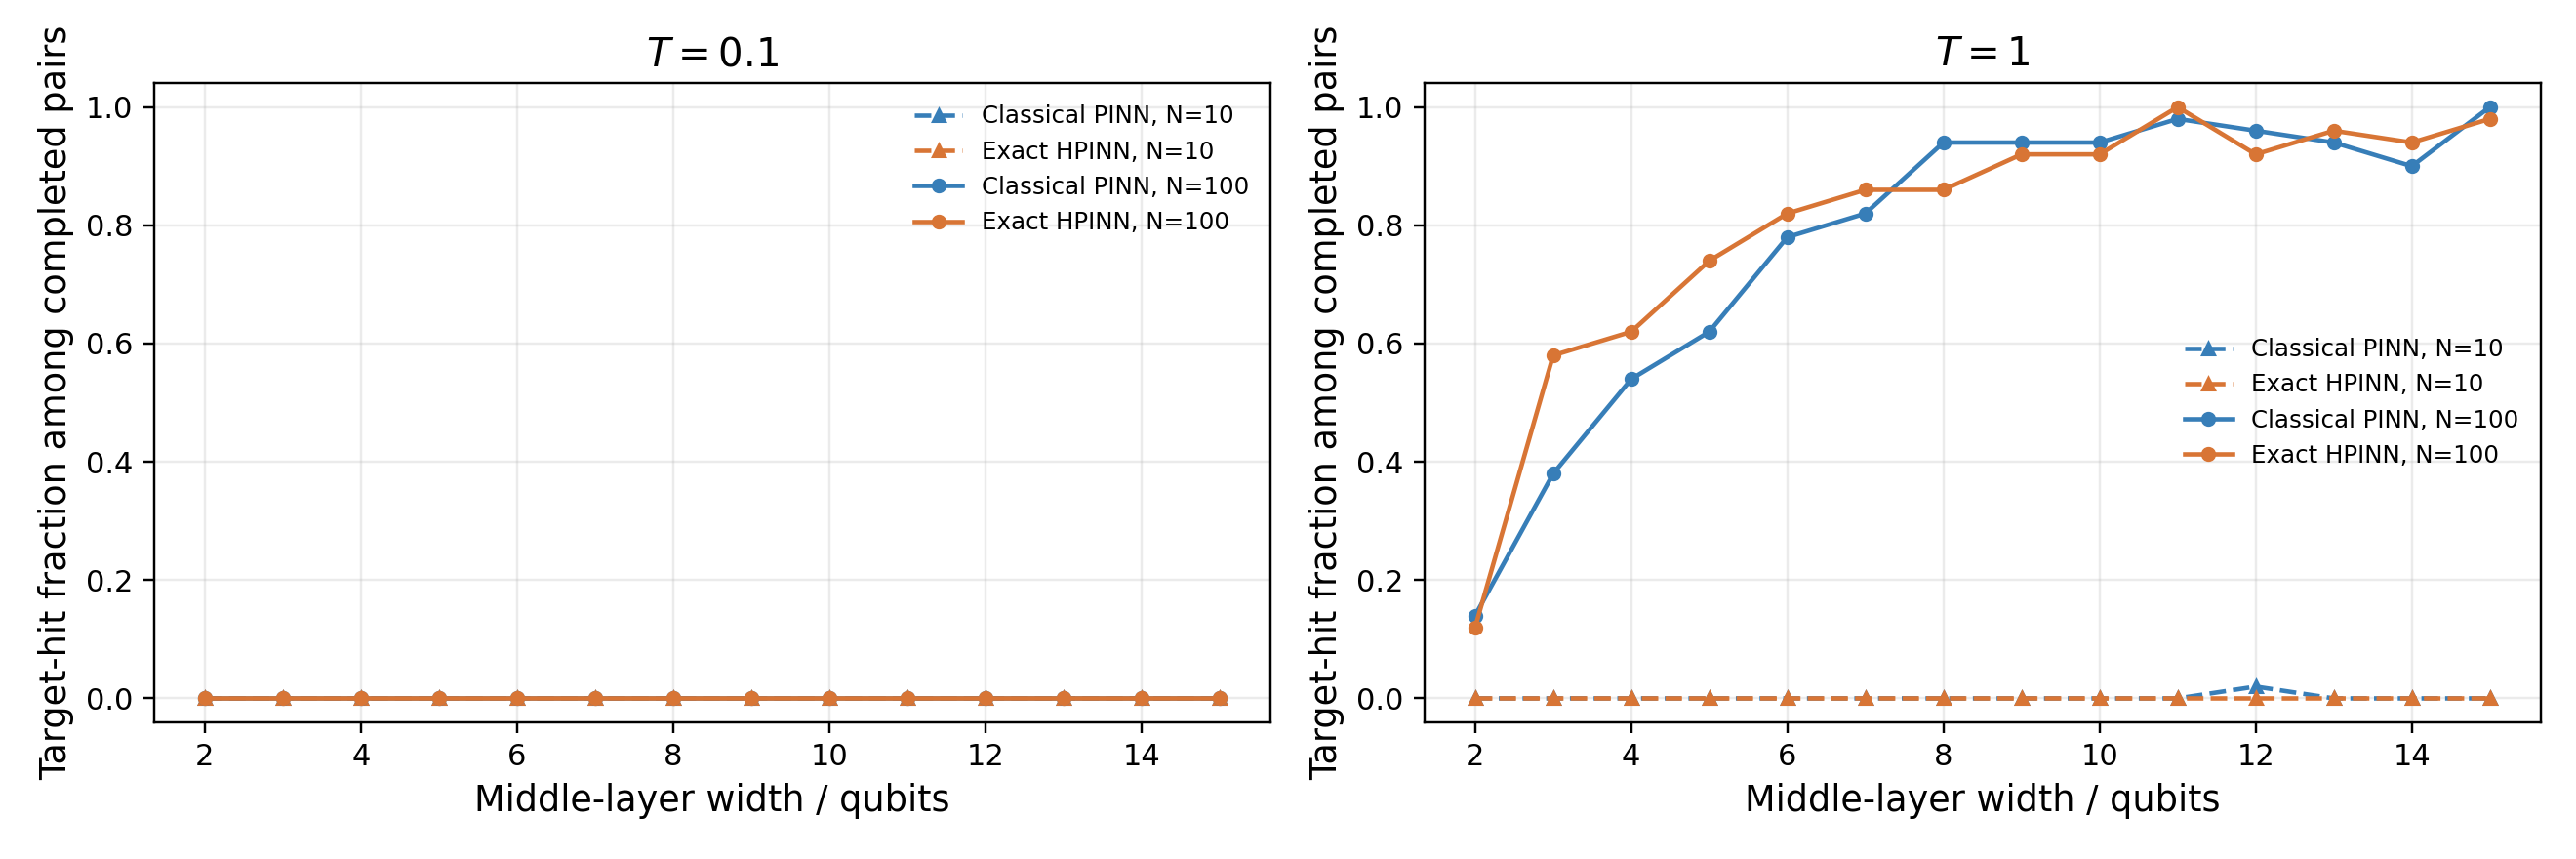

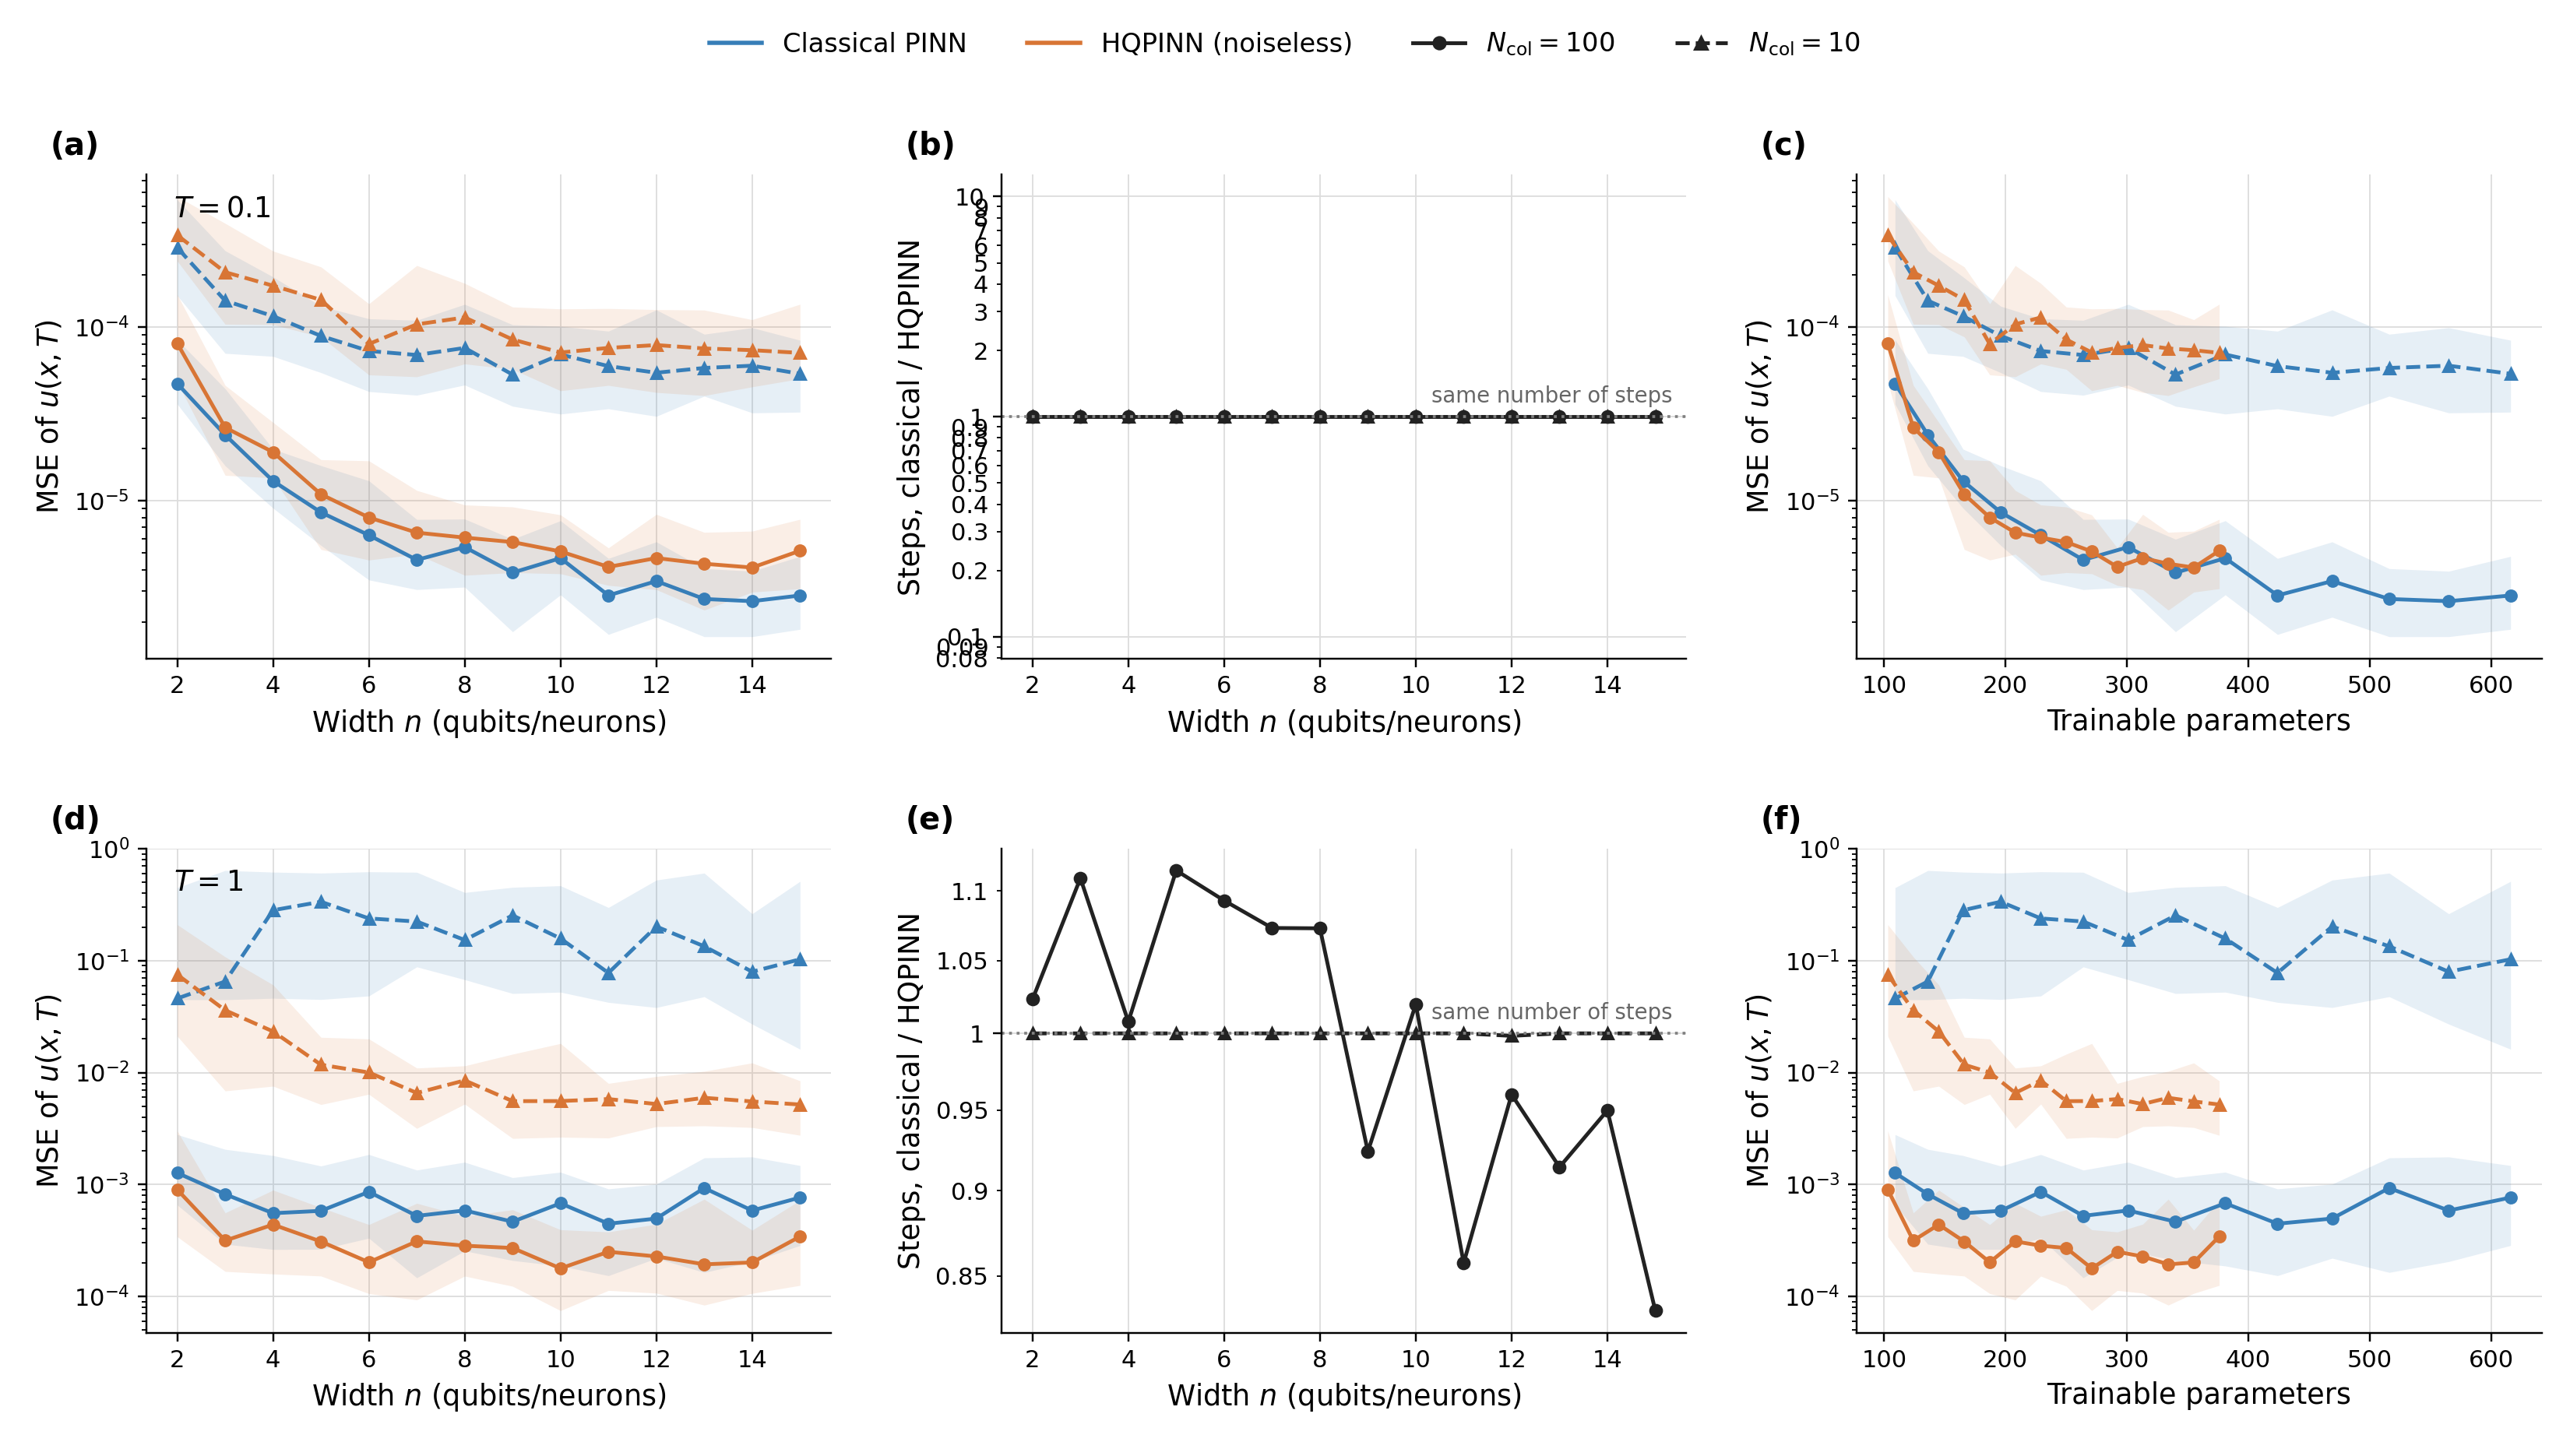

Tables and report: /home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/CBPF_comparison_results_vol4/adaptive_width_7f7e023c270c/comparison


In [38]:
from IPython.display import Image, display
from pathlib import Path
if "campaign_result" in globals():
    comparison = Path(campaign_result["study_dir"]) / "comparison"
    for path in sorted(comparison.glob("*.png")):
        display(Image(filename=str(path)))
    print("Tables and report:",comparison)
else:
    print("Run the campaign or ACTION='compare' first.")


In [ ]:
2+2

In [77]:
2+2

4

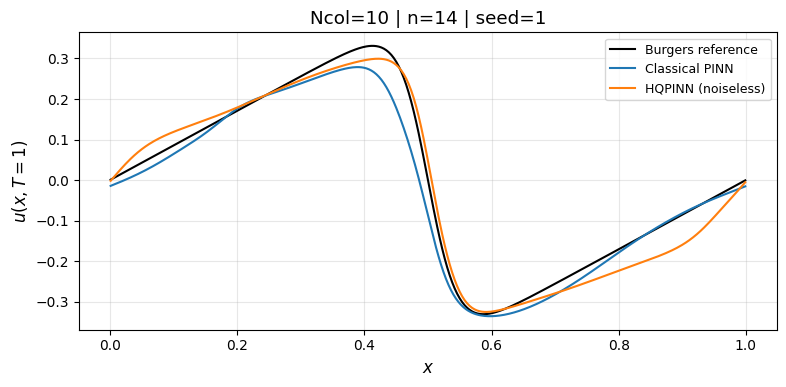

In [71]:
%matplotlib inline

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

T, Ncol, n, seed = 1.0, 10, 14, 1 
root = Path(campaign_result["study_dir"])

tag = f"T{T:g}_n{n}_N{Ncol}_".replace(".", "p")
matches = list(root.glob(f"runs/{tag}*/s{seed:04d}"))
if len(matches) != 1:
    raise ValueError("Confira T, Ncol, n, seed e a pasta do experimento.")

fig, ax = plt.subplots(figsize=(8, 4))
for kind, label, color in [
    ("classical", "Classical PINN", "tab:blue"),
    ("exact", "HQPINN (noiseless)", "tab:orange"),
]:
    path = matches[0] / kind / "evaluation" / "u_x_Tfin.csv"
    data = np.genfromtxt(path, delimiter=",", names=True)
    if kind == "classical":
        ax.plot(data["x"], data["u_reference"], "k-", label="Burgers reference")
    ax.plot(data["x"], data["u_prediction"], color=color, label=label)

ax.set(xlabel=r"$x$", ylabel=rf"$u(x,T={T:g})$",
       title=f"Ncol={Ncol} | n={n} | seed={seed}")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Reporting

Report median and interquartile range of final solution MSE over the seed cohort;
report mean and sample standard deviation of optimizer steps. A completed run
that misses the target contributes the full budget. These are capped step counts:
their mean is a lower bound on the mean steps to the first target hit if training
were continued, not an estimate of that uncensored quantity. The ratio uses
the arithmetic mean classical steps divided by the arithmetic mean HQPINN steps.
For incomplete studies the comparison uses available complete pairs and shows
coverage; failed/interrupted/missing runs are not silently treated as budget misses.
Success fractions are reported separately, so a ratio near 1 with widespread
censoring cannot be interpreted as equal uncensored convergence speed.

The reference figure provides a layout, not expected outcomes. No advantage,
plateau or monotonic improvement is imposed on the results. Include the actual
parameter counts and computational work when describing any observed difference.


T=0.1; factor: 1 -> 1000; budget: 1000
Excluded missing/incomplete runs: 0; unpaired completed runs: 0
Configurations with paired data: 28/28. Check n_pairs / expected_pairs.


,Ncol,n,n_pairs,expected_pairs,classical_success_rate,classical_mean_steps,classical_std_steps,exact_success_rate,exact_mean_steps,exact_std_steps,ratio_classical_exact
0,10,2,50,50,0.24,919.32,175.9035,0.20,956.32,113.9458,0.9613
1,10,3,50,50,0.64,795.36,188.5779,0.42,853.50,216.2530,0.9319
2,10,4,50,50,0.72,707.70,231.6452,0.62,823.00,183.5278,0.8599
3,10,5,50,50,0.86,636.46,209.5754,0.68,775.22,208.7719,0.8210
4,10,6,50,50,0.94,609.06,208.5290,0.76,775.68,196.0121,0.7852
5,10,7,50,50,0.96,604.98,190.4337,0.76,750.16,212.6909,0.8065
6,10,8,50,50,0.90,598.64,198.0758,0.82,736.72,203.9128,0.8126
7,10,9,50,50,0.92,534.30,201.2164,0.84,739.90,186.7875,0.7221
8,10,10,50,50,0.96,539.84,191.8841,0.86,698.06,208.5465,0.7733
9,10,11,50,50,1.00,531.34,191.6994,0.96,619.44,167.4129,0.8578


Saved analysis: /home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/CBPF_comparison_results_vol4/adaptive_width_7f7e023c270c/posthoc_targets/T0.1_factor1000


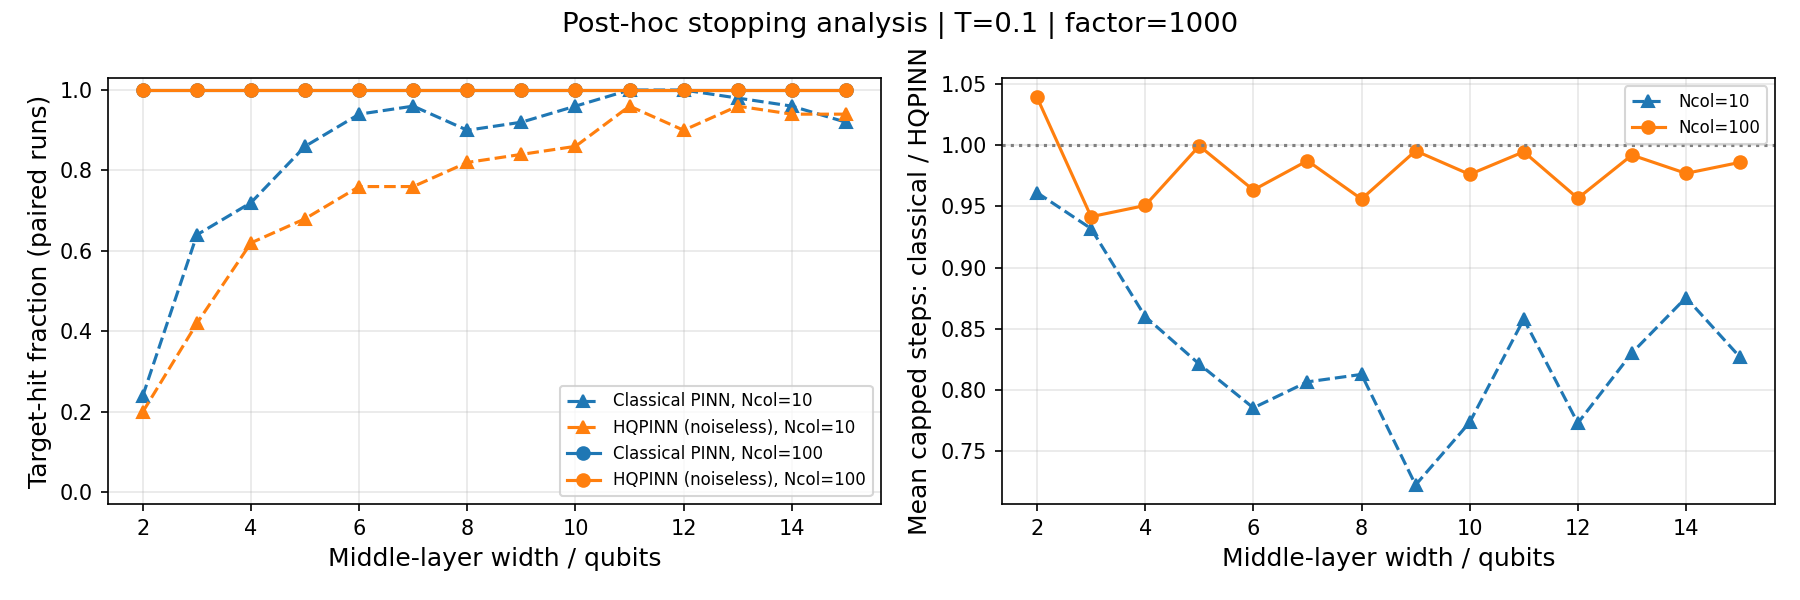

In [73]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Post-processing settings; these do not change the training configuration.
ROOT = Path(
    "/home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/"
    "CBPF_comparison_results_vol4/adaptive_width_7f7e023c270c"
)
T_ANALYSIS = 0.1
NEW_TARGET_FACTOR = 1000.0
SAVE_ANALYSIS = True


def reanalyze_target(root, horizon, new_factor, save=True):
    root = Path(root).expanduser()
    manifest = json.loads(
        (root / "campaign_manifest.json").read_text(encoding="utf-8")
    )
    old_factor = float(manifest["identity"]["targets"]["target_factor"])
    budget = int(manifest["plan"]["max_steps"])
    seeds = manifest["plan"]["seeds"]

    if not np.isfinite(new_factor) or new_factor < old_factor:
        raise ValueError(
            f"Use a finite NEW_TARGET_FACTOR >= {old_factor:g}."
        )

    scenarios = [
        s for s in manifest["plan"]["scenarios"]
        if np.isclose(s["Tfin"], horizon, rtol=0, atol=1e-12)
    ]
    if not scenarios:
        raise ValueError("T_ANALYSIS was not found in this campaign.")

    records, excluded = [], []

    for scenario in scenarios:
        for seed in seeds:
            for kind in ("classical", "exact"):
                folder = (
                    root / "runs" / scenario["scenario_id"]
                    / f"s{seed:04d}" / kind
                )
                result_file = folder / "result.json"
                history_file = folder / "training_history.csv"

                if not result_file.exists() or not history_file.exists():
                    excluded.append({
                        "folder": str(folder), "reason": "missing files"
                    })
                    continue

                result = json.loads(
                    result_file.read_text(encoding="utf-8")
                )
                if result.get("status") != "completed":
                    excluded.append({
                        "folder": str(folder),
                        "reason": result.get("status", "unknown"),
                    })
                    continue

                if (
                    result["protocol_hash"] != manifest["protocol_hash"]
                    or result["max_steps"] != budget
                    or result["kind"] != kind
                    or result["seed"] != seed
                    or any(
                        result[k] != scenario[k]
                        for k in ("scenario_id", "Tfin", "width", "n_collocation")
                    )
                ):
                    raise ValueError(f"Inconsistent run metadata: {folder}")

                history = pd.read_csv(history_file).sort_values("outer_step")
                last_step = int(result["steps_completed"])
                old_target = float(result["target"])

                valid_endpoint = (
                    result["stop_reason"] == "budget_exhausted"
                    and last_step == budget
                ) or result["stop_reason"] == "target_reached"

                if (
                    not valid_endpoint
                    or not 0 <= last_step <= budget
                    or not np.array_equal(
                        history["outer_step"].to_numpy(),
                        np.arange(last_step + 1),
                    )
                    or not np.isfinite(history["validation_loss"]).all()
                    or (history["validation_loss"] < 0).any()
                    or not np.isfinite(old_target)
                    or old_target <= 0
                    or not np.allclose(
                        history["target"], old_target, rtol=1e-10, atol=0
                    )
                ):
                    raise ValueError(
                        f"Incomplete or inconsistent history: {history_file}"
                    )

                if (
                    result["stop_reason"] == "target_reached"
                    and history["validation_loss"].iloc[-1] > old_target
                ):
                    raise ValueError(
                        f"Original target-hit flag disagrees with history: {folder}"
                    )

                new_target = old_target * new_factor / old_factor
                if not np.isfinite(new_target) or new_target <= 0:
                    raise ValueError(f"Invalid rescaled target: {folder}")

                # Includes initialization at step zero.
                hits = history.loc[history["validation_loss"] <= new_target]
                reached = not hits.empty

                if not reached and last_step < budget:
                    raise ValueError(
                        f"Insufficient history for this target: {folder}"
                    )

                records.append({
                    "Tfin": scenario["Tfin"],
                    "n_collocation": scenario["n_collocation"],
                    "width": scenario["width"],
                    "seed": seed,
                    "kind": kind,
                    "target_hash": result["target_hash"],
                    "old_target": old_target,
                    "new_target": new_target,
                    "reached": reached,
                    "first_hit_step": (
                        int(hits.iloc[0]["outer_step"]) if reached else np.nan
                    ),
                    "capped_steps": (
                        int(hits.iloc[0]["outer_step"]) if reached else budget
                    ),
                    "validation_at_hit": (
                        float(hits.iloc[0]["validation_loss"])
                        if reached else np.nan
                    ),
                    "minimum_validation_loss": float(
                        history["validation_loss"].min()
                    ),
                })

    if not records:
        raise ValueError("No completed runs available for this horizon.")

    runs = pd.DataFrame(records)
    keys = ["Tfin", "n_collocation", "width", "seed"]

    if runs.duplicated(keys + ["kind"]).any():
        raise ValueError("Duplicate model/seed records.")

    # Use the same seed cohort for both models.
    runs["paired"] = runs.groupby(keys)["kind"].transform("nunique").eq(2)
    paired = runs.loc[runs["paired"]]

    if paired.empty:
        raise ValueError("No complete classical/exact seed pairs available.")

    if (
        paired.groupby(keys)[["old_target", "target_hash"]].nunique() > 1
    ).any().any():
        raise ValueError(
            "Classical and exact runs do not share the same original target."
        )

    summary_rows = []
    for (ncol, width), group in paired.groupby(["n_collocation", "width"]):
        row = {
            "Ncol": ncol,
            "n": width,
            "n_pairs": group["seed"].nunique(),
            "expected_pairs": len(seeds),
        }
        for kind in ("classical", "exact"):
            part = group.loc[group["kind"] == kind]
            row[f"{kind}_success_rate"] = part["reached"].mean()
            row[f"{kind}_mean_steps"] = part["capped_steps"].mean()
            row[f"{kind}_std_steps"] = part["capped_steps"].std(ddof=1)

        # Ratio of means, not mean of per-seed ratios.
        row["ratio_classical_exact"] = (
            row["classical_mean_steps"] / row["exact_mean_steps"]
            if row["exact_mean_steps"] > 0 else np.nan
        )
        summary_rows.append(row)

    summary = pd.DataFrame(summary_rows).sort_values(["Ncol", "n"])

    print(
        f"T={horizon:g}; factor: {old_factor:g} -> {new_factor:g}; "
        f"budget: {budget}"
    )
    print(
        f"Excluded missing/incomplete runs: {len(excluded)}; "
        f"unpaired completed runs: {(~runs['paired']).sum()}"
    )
    print(
        f"Configurations with paired data: {len(summary)}/{len(scenarios)}. "
        "Check n_pairs / expected_pairs."
    )
    display(summary.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ncol, group in summary.groupby("Ncol"):
        style = "--^" if ncol == 10 else "-o"

        for kind, color, label in (
            ("classical", "tab:blue", "Classical PINN"),
            ("exact", "tab:orange", "HQPINN (noiseless)"),
        ):
            axes[0].plot(
                group["n"], group[f"{kind}_success_rate"],
                style, color=color, label=f"{label}, Ncol={ncol}"
            )

        axes[1].plot(
            group["n"], group["ratio_classical_exact"],
            style, label=f"Ncol={ncol}"
        )

    axes[0].set(
        ylabel="Target-hit fraction (paired runs)", ylim=(-0.03, 1.03)
    )
    axes[1].set(ylabel="Mean capped steps: classical / HQPINN")
    axes[1].axhline(1, color="gray", linestyle=":")

    for ax in axes:
        ax.set_xlabel("Middle-layer width / qubits")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(
        f"Post-hoc stopping analysis | T={horizon:g} | factor={new_factor:g}"
    )
    fig.tight_layout()

    if save:
        output = (
            root / "posthoc_targets"
            / f"T{horizon:g}_factor{new_factor:.17g}"
        )
        output.mkdir(parents=True, exist_ok=True)
        runs.to_csv(output / "per_seed.csv", index=False)
        summary.to_csv(output / "summary.csv", index=False)
        pd.DataFrame(
            excluded, columns=["folder", "reason"]
        ).to_csv(output / "excluded_runs.csv", index=False)

        metadata = {
            "Tfin": horizon,
            "original_factor": old_factor,
            "new_factor": new_factor,
            "source_protocol_hash": manifest["protocol_hash"],
            "max_steps": budget,
            "criterion": (
                "First validation_loss <= rescaled target; "
                "otherwise capped at max_steps."
            ),
            "comparison": "Complete classical/exact seed pairs only.",
            "limitation": (
                "No solution error or wall time is inferred "
                "at the new stopping step."
            ),
        }
        (output / "analysis_config.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )
        fig.savefig(output / "posthoc_comparison.png", dpi=180)
        print("Saved analysis:", output)

    # Explicit PNG display also works with the Agg backend.
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

    return runs, summary


posthoc_runs, posthoc_summary = reanalyze_target(
    ROOT, T_ANALYSIS, NEW_TARGET_FACTOR, SAVE_ANALYSIS
)

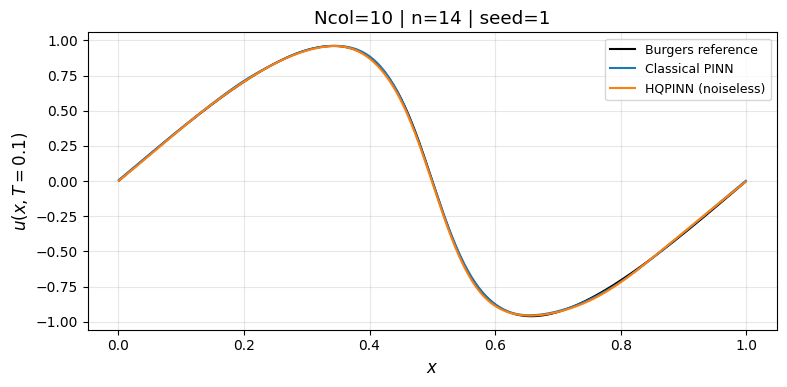

In [78]:
%matplotlib inline

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

T, Ncol, n, seed = 0.1, 10, 14, 1 
root = Path(
    "/home/erickcastro/projetos/meu_projeto/ExperimentsVol2/CBPF Geral/"
    "CBPF_comparison_results_vol4/adaptive_width_7f7e023c270c"
)

tag = f"T{T:g}_n{n}_N{Ncol}_".replace(".", "p")
matches = list(root.glob(f"runs/{tag}*/s{seed:04d}"))
if len(matches) != 1:
    raise ValueError("Confira T, Ncol, n, seed e a pasta do experimento.")

fig, ax = plt.subplots(figsize=(8, 4))
for kind, label, color in [
    ("classical", "Classical PINN", "tab:blue"),
    ("exact", "HQPINN (noiseless)", "tab:orange"),
]:
    path = matches[0] / kind / "evaluation" / "u_x_Tfin.csv"
    data = np.genfromtxt(path, delimiter=",", names=True)
    if kind == "classical":
        ax.plot(data["x"], data["u_reference"], "k-", label="Burgers reference")
    ax.plot(data["x"], data["u_prediction"], color=color, label=label)

ax.set(xlabel=r"$x$", ylabel=rf"$u(x,T={T:g})$",
       title=f"Ncol={Ncol} | n={n} | seed={seed}")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()